<a href="https://colab.research.google.com/github/gibranfp/CursoAprendizajeProfundo/blob/2027-1/notebooks/1e_procesamiento_audio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reconocimiento de comandos de voz
## Del sonido a Fourier y los espectrogramas

**Cuaderno progresivo para Google Colab · Alejandro Romero**  
**Alcance:** fundamentos de audio (parte 1), Fourier desde cero (parte 2), espectrogramas y reconstrucción (parte 3), y Mel, log-Mel y MFCC (parte 4). Cada parte contiene ejercicios para quien quiera indagar o practicar más.

**Ruta de lectura:** secciones 0–11 = parte 1; secciones 12–24 = parte 2; secciones 25–35 = parte 3; secciones 36–47 = parte 4. Si ya estudiaste la primera parte, ejecuta la celda de importaciones del inicio y continúa en la sección 12; los nuevos ejemplos crean sus propias señales.

Al terminar podrás representar audio, analizar sus frecuencias y construir un espectrograma paso a paso.

**Para empezar por la parte 3 o 4:** ejecuta las importaciones del inicio y las celdas desde la sección 25 o 36, respectivamente, en orden. Sus ejemplos son independientes de las partes anteriores. El índice lleva a cada tema; para ejecutar un ejemplo intermedio, ejecuta antes las celdas previas de su parte.

### Cómo usar esta libreta

1. Alternamos **Markdown** (explicación, fórmulas y preguntas) con **Python** (experimentos).
2. Puedes usar CPU: las partes 1–4 no necesitan GPU ni descargar un conjunto de datos.
3. Reproduce los audios manualmente y empieza con volumen bajo. Las gráficas y audios se regeneran al ejecutar.

**Todas las importaciones están en la primera celda de código.**

**Aplicación final:** las secciones 48–63 presentan Speech Commands, su preprocesamiento y la organización de ejemplos en `Dataset` y `DataLoader`. Este bloque requiere descargar el conjunto o indicar una carpeta que ya lo contenga. Las redes se presentan únicamente como introducción; el cuaderno termina en la preparación e inspección de los datos.

<a id="indice" name="indice"></a>

## Índice

Selecciona el **nombre del tema** para ir a su sección. Los enlaces **↑ Volver al índice** permiten regresar aquí.

Ejecuta primero las importaciones y después las celdas de la parte elegida en orden. Las partes 2, 3 y 4 comienzan en 12, 25 y 36. La aplicación final comienza en 48; su descarga se configura en 49.

### Parte 1 · Audio digital

- [**0. Librerías y configuración**](#tema-0)
- [**1. ¿Qué es una señal de audio?**](#tema-1)
- [**2. Representación digital del audio**](#tema-2)
- [**3. Amplitud, frecuencia y fase**](#tema-3)
- [**4. Muestreo**](#tema-4)
- [**4A. Teorema de muestreo de Nyquist–Shannon**](#tema-4a)
- [**5. Cuantización**](#tema-5)
- [**6. Amplitud normalizada y saturación**](#tema-6)
- [**7. Lectura y escritura de archivos WAV**](#tema-7)
- [**8. Audio mono y estéreo**](#tema-8)
- [**9. Ejercicio: generación de tonos**](#tema-9)
- [**10. Ejercicios de comprensión**](#tema-10)
- [**11. Organización del contenido y referencias**](#tema-11)

### Parte 2 · Fourier

- [**12. Suma de señales senoidales**](#tema-12)
- [**12A. Representación gráfica de Fourier**](#tema-12a)
- [**13. Comparación con senos y cosenos**](#tema-13)
- [**14. Transformada discreta de Fourier**](#tema-14)
- [**15. Cálculo de la FFT**](#tema-15)
- [**16. Magnitud y fase**](#tema-16)
- [**17. Transformada inversa de Fourier**](#tema-17)
- [**18. Duración y resolución en frecuencia**](#tema-18)
- [**19. Fuga espectral**](#tema-19)
- [**19A. Ventana Hann**](#tema-19a)
- [**20. Amplitud, potencia y decibelios**](#tema-20)
- [**21. Información temporal en el espectro**](#tema-21)
- [**22. Ejercicio: análisis de una mezcla**](#tema-22)
- [**23. Ejercicios y respuestas**](#tema-23)
- [**24. Referencias sobre Fourier**](#tema-24)

### Parte 3 · STFT y reconstrucción

- [**25. Análisis en tiempo y frecuencia**](#tema-25)
- [**26. Ventanas y solapamiento**](#tema-26)
- [**27. Cálculo de la STFT con NumPy**](#tema-27)
- [**27A. Reconstrucción mediante overlap-add**](#tema-27a)
- [**27B. Normalización de la reconstrucción**](#tema-27b)
- [**28. Representación del espectrograma**](#tema-28)
- [**29. Cálculo de la STFT con librosa**](#tema-29)
- [**30. Parámetros de la STFT**](#tema-30)
- [**31. Resolución temporal y frecuencial**](#tema-31)
- [**32. Interpretación de espectrogramas**](#tema-32)
- [**33. Ejercicio: parámetros de la STFT**](#tema-33)
- [**34. Ejercicios de comprensión**](#tema-34)
- [**35. Representaciones de audio y referencias**](#tema-35)

### Parte 4 · Mel, log-Mel y MFCC

- [**36. Características del audio**](#tema-36)
- [**37. Escala Mel**](#tema-37)
- [**38. Banco de filtros Mel**](#tema-38)
- [**39. Cálculo del espectrograma Mel**](#tema-39)
- [**40. Espectrograma log-Mel**](#tema-40)
- [**41. Coeficientes MFCC**](#tema-41)
- [**42. Reducción del número de coeficientes**](#tema-42)
- [**43. Efecto de la amplitud sobre las características**](#tema-43)
- [**44. Función de extracción de características**](#tema-44)
- [**45. Ejercicios y ejemplos de aplicación**](#tema-45)
- [**46. Ejercicios y respuestas razonadas**](#tema-46)
- [**47. Referencias sobre características de audio**](#tema-47)

### Aplicación final · Speech Commands y preprocesamiento

- [**48. Speech Commands**](#tema-48)
- [**49. Descarga y carpeta de trabajo**](#tema-49)
- [**50. Archivos, etiquetas y hablantes**](#tema-50)
- [**51. Particiones y distribución de clases**](#tema-51)
- [**52. Lectura y revisión de una grabación**](#tema-52)
- [**53. Preprocesamiento del audio**](#tema-53)
- [**54. Log-Mel de tamaño fijo**](#tema-54)
- [**55. Tensores de PyTorch**](#tema-55)
- [**56. Dataset: un ejemplo y su etiqueta**](#tema-56)
- [**57. Normalización con datos de entrenamiento**](#tema-57)
- [**58. DataLoader: organización por lotes**](#tema-58)
- [**59. collate_fn y longitudes diferentes**](#tema-59)
- [**60. Inspección de un lote**](#tema-60)
- [**61. Introducción a las redes para comandos de voz**](#tema-61)
- [**62. Ejercicios de preparación de datos**](#tema-62)
- [**63. Cierre y referencias**](#tema-63)

<a id="tema-0" name="tema-0"></a>

## 0. Librerías y configuración

| Herramienta | Alias / función | Para qué se usa aquí |
|---|---|---|
| NumPy | `np` | Guardar muestras, calcular senos y usar `np.fft` para Fourier. |
| Matplotlib | `plt` | Dibujar señales, muestras y comparaciones. |
| librosa | `librosa`, `librosa.display` | Calcular STFT y visualizar espectrogramas. |
| SciPy | `wavfile`, `dct`, `idct` | Archivos WAV y transformada coseno para MFCC. |
| PyTorch | `torch`, `Dataset`, `DataLoader` | Tensores y organización de datos por lotes. |
| Biblioteca estándar | `Counter`, `hashlib`, `tarfile`, `shutil`, `math`, `json` | Conteos, verificación de descarga, extracción y registro de parámetros. |
| IPython | `Audio`, `display` | Mostrar reproductores dentro del cuaderno. |
| Biblioteca estándar | `Path`, `sys`, `importlib.metadata` | Manejar carpetas y consultar versiones. |

`import ... as ...` crea un nombre corto. `from ... import ...` importa herramientas concretas.
Esta parte usa paquetes habituales de Colab. Si tu entorno no los tiene, ejecuta `%pip install numpy matplotlib scipy ipython librosa==0.11.0 torch` en una celda de instalación **antes** de esta celda y vuelve a ejecutarla. Los archivos WAV se leen con SciPy; las características se calculan con librosa y la organización por lotes se hace con PyTorch. No se necesita torchaudio para ejecutar estos ejemplos.

[**↑ Volver al índice**](#indice)

In [1]:
# Todas las importaciones del cuaderno, concentradas al inicio.
import sys
import importlib.metadata as metadata
from pathlib import Path
from collections import Counter
import hashlib
import tarfile
import shutil
import math
import json

import torch
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from scipy.io import wavfile
from scipy.fft import dct, idct
from IPython.display import Audio, display

plt.rcParams.update({
    "figure.figsize": (10, 3.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2, "font.size": 11,
})
COLOR = "#176B87"
ACENTO = "#DC6B32"
CARPETA = Path("audio_parte1")
CARPETA.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
for paquete in ["numpy", "matplotlib", "scipy", "ipython", "librosa", "torch"]:
    print(f"{paquete}: {metadata.version(paquete)}")
print("El cuaderno puede ejecutarse en CPU.")

Python: 3.13.18
numpy: 2.4.6
matplotlib: 3.10.0
scipy: 1.16.3
ipython: 7.34.0
librosa: 0.11.0
torch: 2.11.0+cpu
El cuaderno puede ejecutarse en CPU.


<a id="tema-1" name="tema-1"></a>

## 1. ¿Qué es una señal de audio?

El sonido es una variación de presión que se propaga en un medio, como el aire. Un micrófono transforma esas variaciones en una señal eléctrica; un sistema de adquisición la convierte en números.

Una **señal** describe cómo cambia una cantidad. En audio solemos observar su **amplitud en función del tiempo**. En nuestras gráficas, el eje horizontal será tiempo y el vertical amplitud.

Los valores positivos y negativos representan variaciones respecto a una referencia; **una muestra negativa no significa que el sonido sea inválido**. En estos ejemplos la amplitud será relativa y sin unidades físicas: no estamos midiendo presión en pascales.

### Un modelo sencillo: el tono puro

$$x(t)=A\sin(2\pi f t+\varphi)$$

| Símbolo | Significado | Unidad / ejemplo |
|---|---|---|
| $t$ | Tiempo | segundos (s) |
| $A$ | Amplitud máxima | 0.3 en nuestra escala relativa |
| $f$ | Frecuencia: ciclos por segundo | 440 hercios (Hz) |
| $\varphi$ | Fase inicial: dónde comienza el ciclo | radianes; usaremos 0 |
| $T=1/f$ | Periodo: tiempo de un ciclo | segundos |

Un tono puro permite estudiar una sola frecuencia. **La voz no es una sola onda seno:** contiene múltiples componentes y cambia durante la pronunciación.

[**↑ Volver al índice**](#indice)

<a id="tema-2" name="tema-2"></a>

## 2. Representación digital del audio

Una computadora almacena una secuencia finita de números. La **frecuencia de muestreo**, $f_s$, indica cuántas muestras se toman por segundo.

$$t_n=\frac{n}{f_s},\qquad x[n]=A\sin\left(2\pi f\frac{n}{f_s}+\varphi\right)$$

El índice $n$ toma valores $0,1,2,\ldots,N-1$. Si generamos 1 segundo con $f_s=16\,000$ muestras/s, obtenemos $N=16\,000$ muestras.

> **Distinción central:** $f$ describe las oscilaciones del sonido; $f_s$ describe la velocidad con que lo medimos. Un tono de 440 Hz puede almacenarse con 16 000 muestras por segundo.

En la siguiente celda, `np.arange(N)` crea los índices y dividirlos entre `fs` los convierte en tiempos. `np.sin` calcula el seno para todos los tiempos a la vez. `.astype(np.float32)` guarda cada valor como número de punto flotante de 32 bits.

[**↑ Volver al índice**](#indice)

In [2]:
fs = 16_000             # Frecuencia de muestreo: muestras por segundo.
duracion = 1.0          # Segundos.
frecuencia = 440.0      # Frecuencia del tono: ciclos por segundo.
amplitud = 0.3          # Amplitud relativa.
fase = 0.0             # Radianes.

N = int(round(fs * duracion))
t = np.arange(N) / fs
audio = (amplitud * np.sin(2 * np.pi * frecuencia * t + fase)).astype(np.float32)

print("Número de muestras:", len(audio))
print("Forma del arreglo:", audio.shape)
print("Tipo de dato:", audio.dtype)
print("Primeras 8 muestras:", np.round(audio[:8], 4))
print(f"Duración: {len(audio) / fs:.3f} s")
print(f"Separación entre muestras: {1 / fs:.7f} s")
print(f"Periodo del tono: {1000 / frecuencia:.3f} ms")

Número de muestras: 16000
Forma del arreglo: (16000,)
Tipo de dato: float32
Primeras 8 muestras: [0.     0.0516 0.1016 0.1486 0.1912 0.2281 0.2582 0.2806]
Duración: 1.000 s
Separación entre muestras: 0.0000625 s
Periodo del tono: 2.273 ms


`shape = (16000,)` significa **un arreglo con un eje y 16 000 valores**, no 16 000 canales. `audio[:8]` selecciona los primeros ocho valores.

### Escuchar y observar

`Audio(audio, rate=fs)` necesita las muestras y cuántas debe reproducir por segundo. Usaremos `normalize=False`: así el reproductor no iguala automáticamente los picos de cada ejemplo y podemos comparar amplitudes.

Una gráfica de todo el segundo puede parecer un bloque porque hay 440 ciclos. Ampliaremos los primeros 10 milisegundos (ms). Los puntos son las muestras; la línea que los une es una ayuda visual.

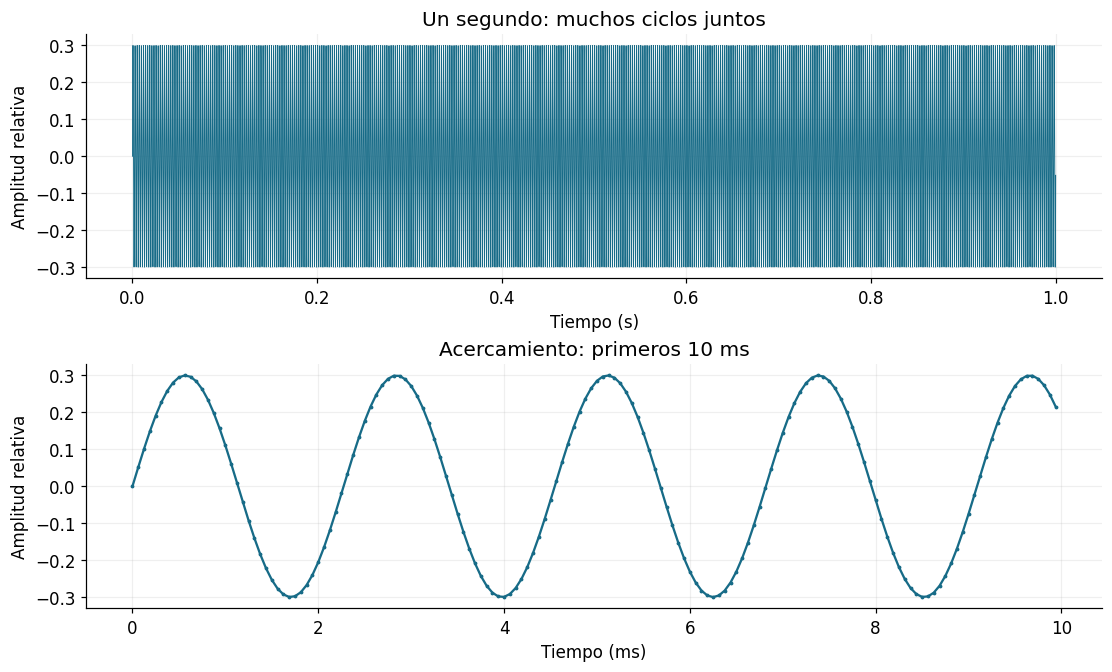

In [3]:
display(Audio(audio, rate=fs, normalize=False))
fig, ax = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
ax[0].plot(t, audio, color=COLOR, linewidth=0.6)
ax[0].set(title="Un segundo: muchos ciclos juntos", xlabel="Tiempo (s)", ylabel="Amplitud relativa")
vista = t < 0.010
ax[1].plot(t[vista] * 1000, audio[vista], ".-", color=COLOR, markersize=3)
ax[1].set(title="Acercamiento: primeros 10 ms", xlabel="Tiempo (ms)", ylabel="Amplitud relativa")
plt.show()

<a id="tema-3" name="tema-3"></a>

## 3. Amplitud, frecuencia y fase

**Amplitud:** al mantener la misma frecuencia y cambiar la amplitud, cambia el tamaño vertical de la señal. Con el mismo equipo y configuración, suele percibirse un cambio de volumen; la sonoridad también depende de la frecuencia, el oído y la reproducción.

Las siguientes señales tienen 440 Hz y el mismo periodo. Observa que el eje vertical usa la misma escala para ambas.

[**↑ Volver al índice**](#indice)

Tono de 440 Hz, amplitud 0.1


Tono de 440 Hz, amplitud 0.4


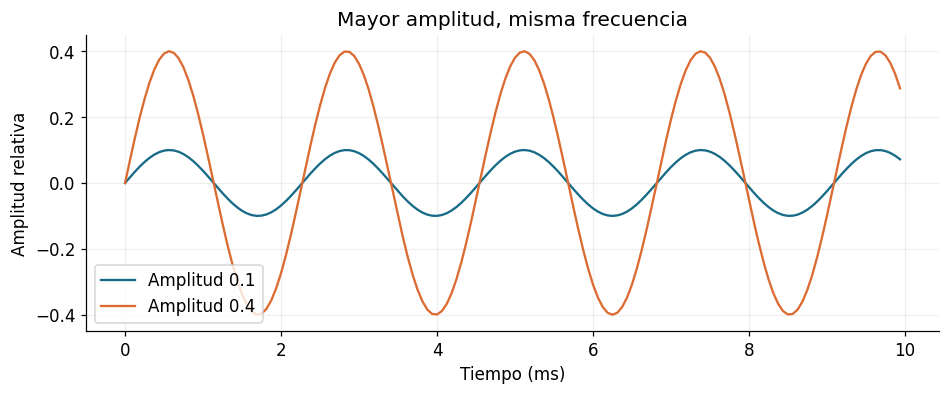

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for A, color in [(0.1, COLOR), (0.4, ACENTO)]:
    ejemplo = (A * np.sin(2 * np.pi * 440 * t)).astype(np.float32)
    ax.plot(t[vista] * 1000, ejemplo[vista], label=f"Amplitud {A}", color=color)
    print(f"Tono de 440 Hz, amplitud {A}")
    display(Audio(ejemplo, rate=fs, normalize=False))
ax.set(xlabel="Tiempo (ms)", ylabel="Amplitud relativa", title="Mayor amplitud, misma frecuencia", ylim=(-0.45, 0.45))
ax.legend()
plt.show()

**Frecuencia:** si aumentamos los ciclos por segundo, el tono puro se percibe más agudo. Si los disminuimos, más grave. En la gráfica aparecen más oscilaciones dentro del mismo intervalo de tiempo.

Aquí mantenemos la amplitud en 0.25. Eso iguala la amplitud numérica, aunque no garantiza idéntica sonoridad percibida.

Tono de 220 Hz


Tono de 880 Hz


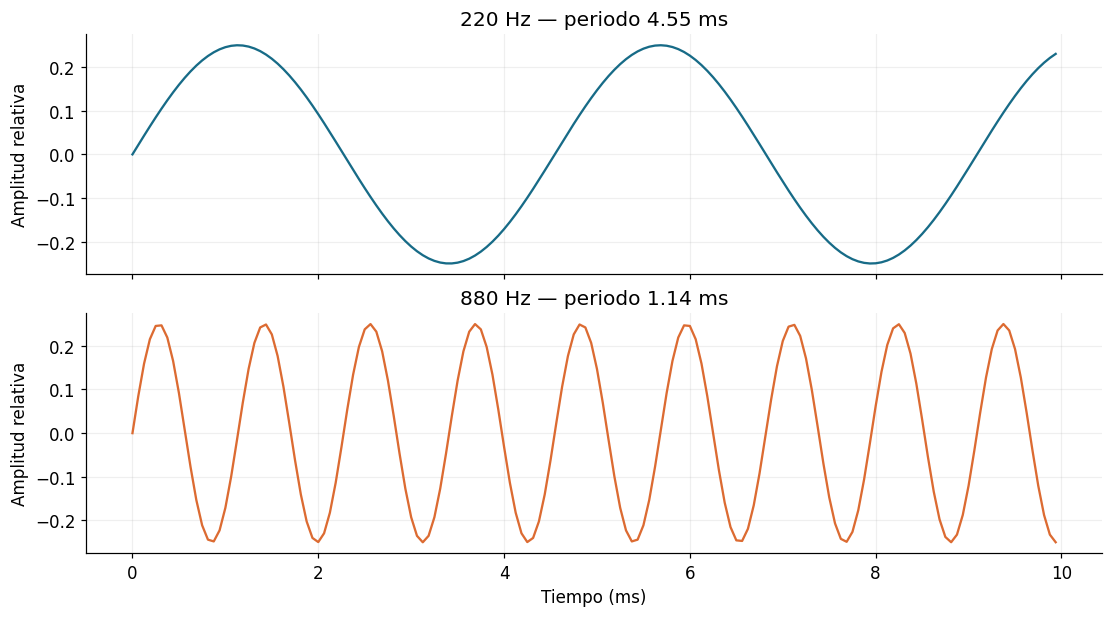

In [5]:
fig, ejes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, sharey=True, constrained_layout=True)
for ax, f, color in zip(ejes, [220, 880], [COLOR, ACENTO]):
    ejemplo = (0.25 * np.sin(2 * np.pi * f * t)).astype(np.float32)
    ax.plot(t[vista] * 1000, ejemplo[vista], color=color)
    ax.set(title=f"{f} Hz — periodo {1000/f:.2f} ms", ylabel="Amplitud relativa")
    print(f"Tono de {f} Hz")
    display(Audio(ejemplo, rate=fs, normalize=False))
ejes[-1].set_xlabel("Tiempo (ms)")
plt.show()

**Fase:** cambia la posición inicial dentro del ciclo. Dos senos con la misma frecuencia y amplitud pueden comenzar en valores diferentes. Una fase de $\pi/2$ equivale aquí a un cuarto de ciclo.

Al escuchar un tono aislado sostenido, este cambio puede ser difícil de distinguir. La fase sí importa al combinar señales; su efecto se analiza en los ejemplos de Fourier.

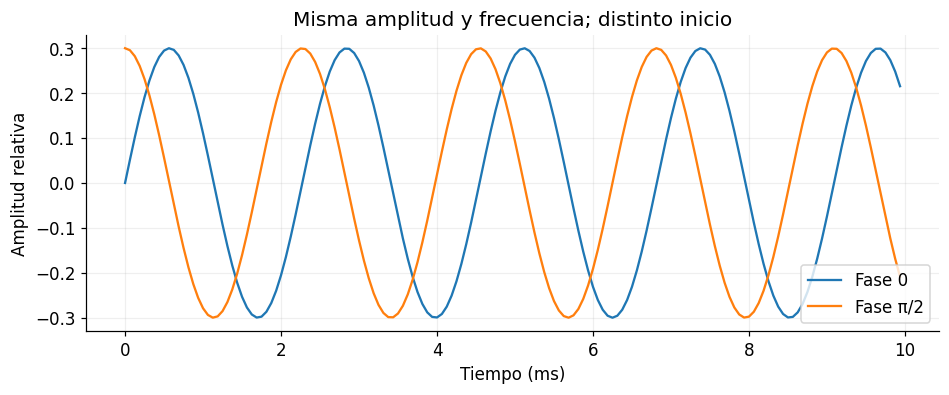

In [6]:
fig, ax = plt.subplots()
for phi, etiqueta in [(0, "Fase 0"), (np.pi/2, "Fase π/2")]:
    ejemplo = 0.3 * np.sin(2 * np.pi * 440 * t + phi)
    ax.plot(t[vista] * 1000, ejemplo[vista], label=etiqueta)
ax.set(xlabel="Tiempo (ms)", ylabel="Amplitud relativa", title="Misma amplitud y frecuencia; distinto inicio")
ax.legend()
plt.show()

<a id="tema-4" name="tema-4"></a>

## 4. Muestreo

Los puntos de la siguiente figura representan muestras de un tono de 5 Hz. La curva suave es una referencia calculada con muchos puntos; no es una medición analógica real.

Con 20 muestras/s obtenemos 4 muestras por ciclo; con 80 muestras/s, 16. Aumentar $f_s$ **no aumenta la frecuencia del tono**: aumenta la cantidad de observaciones por segundo.

Para representar sin ambigüedad una señal ideal limitada en banda, necesitamos $f_s>2f_{\max}$. La frecuencia $f_s/2$ se llama **frecuencia de Nyquist**. En adquisición real se filtra antes de muestrear y se deja margen para los filtros.

[**↑ Volver al índice**](#indice)

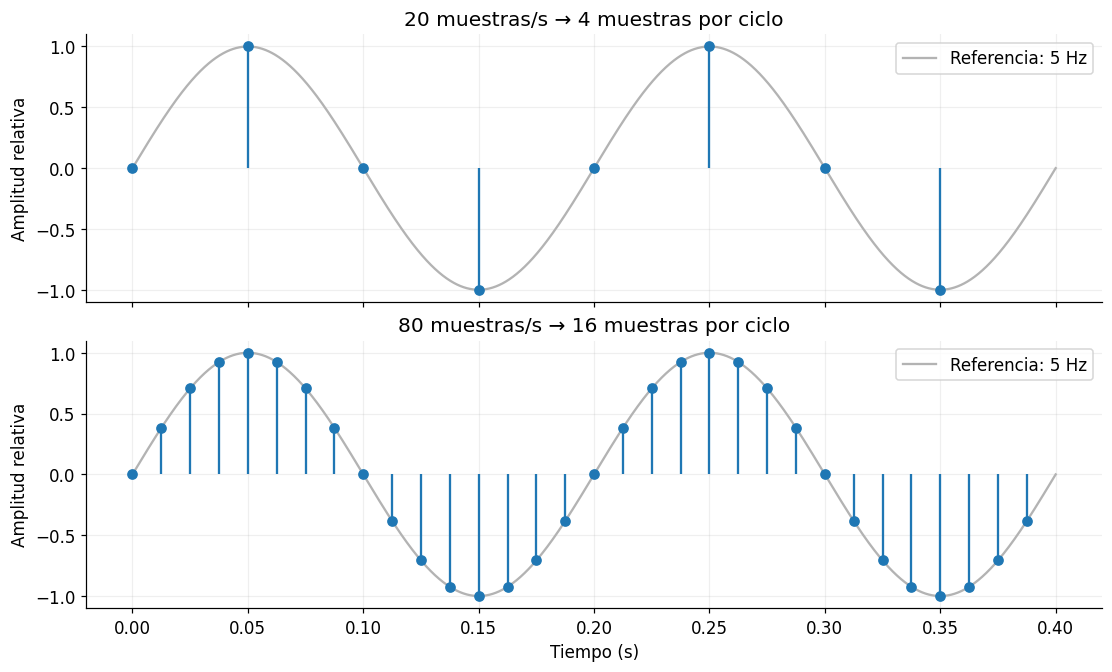

In [7]:
t_ref = np.linspace(0, 0.4, 2000)
fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
for ax, fs_demo in zip(ejes, [20, 80]):
    tiempos = np.arange(int(0.4 * fs_demo)) / fs_demo
    muestras = np.sin(2 * np.pi * 5 * tiempos)
    ax.plot(t_ref, np.sin(2 * np.pi * 5 * t_ref), color="0.7", label="Referencia: 5 Hz")
    ax.stem(tiempos, muestras, linefmt="C0-", markerfmt="C0o", basefmt=" ")
    ax.set(title=f"{fs_demo} muestras/s → {fs_demo/5:.0f} muestras por ciclo", ylabel="Amplitud relativa")
    ax.legend(loc="upper right")
ejes[-1].set_xlabel("Tiempo (s)")
plt.show()

### ¿Qué pasa si muestreamos demasiado lento? Aliasing

El *aliasing* ocurre cuando distintas frecuencias producen muestras indistinguibles. Muestrearemos un coseno de 900 Hz a 1 000 muestras/s: excede Nyquist (500 Hz). Esas muestras coinciden con las de un coseno de 100 Hz.

Usamos coseno, que es un seno desplazado en fase, para que la coincidencia sea directa. La frecuencia alta **no desaparece mágicamente del mundo físico**: perdemos la capacidad de identificarla a partir de estas muestras.

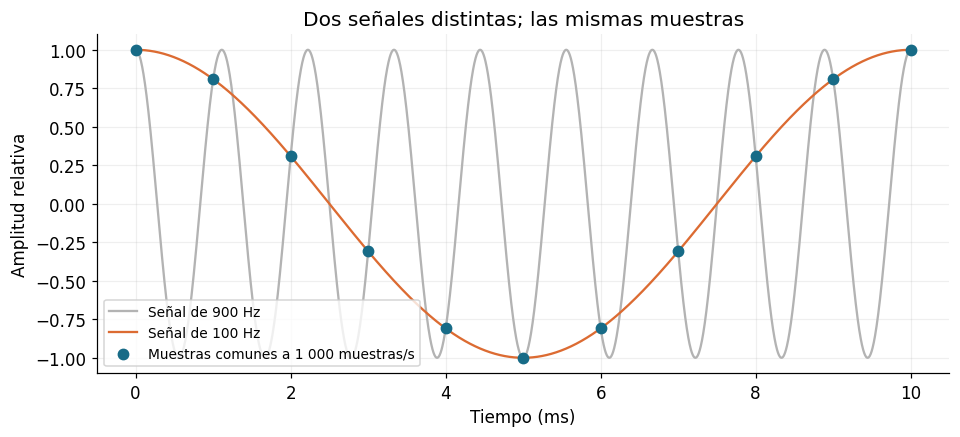

¿Coinciden las muestras? True


In [8]:
fs_alias = 1000
ta = np.arange(11) / fs_alias
fina = np.linspace(0, 0.010, 2500)
alta = np.cos(2 * np.pi * 900 * ta)
baja = np.cos(2 * np.pi * 100 * ta)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(fina * 1000, np.cos(2 * np.pi * 900 * fina), color="0.7", label="Señal de 900 Hz")
ax.plot(fina * 1000, np.cos(2 * np.pi * 100 * fina), color=ACENTO, label="Señal de 100 Hz")
ax.scatter(ta * 1000, alta, color=COLOR, s=45, zorder=3, label="Muestras comunes a 1 000 muestras/s")
ax.set(xlabel="Tiempo (ms)", ylabel="Amplitud relativa", title="Dos señales distintas; las mismas muestras")
ax.legend(loc="lower left", fontsize=9)
plt.show()
print("¿Coinciden las muestras?", np.allclose(alta, baja))

<a id="tema-4a" name="tema-4a"></a>

## 4A. Teorema de muestreo de Nyquist–Shannon

**Enunciado práctico para señales de banda base:** si una señal continua está limitada a frecuencias menores o iguales que $B$ Hz, puede recuperarse idealmente de sus muestras uniformes cuando $f_s>2B$. La condición evita que las copias del espectro creadas por el muestreo se superpongan.

| Idea | Significado |
|---|---|
| Limitada en banda | No contiene componentes por encima de $B$. No significa que dure poco. |
| Muestreo uniforme | Las muestras están separadas exactamente $T_s=1/f_s$ segundos. |
| Tasa de Nyquist de la señal | $2B$: depende de la banda que queremos preservar. |
| Frecuencia de Nyquist del sistema | $f_s/2$: depende de la frecuencia de muestreo elegida. |
| Reconstrucción ideal | Usa todas las muestras, precisión ideal y un filtro de reconstrucción ideal. Un archivo finito y ruidoso solo aproxima ese escenario. |

**Ejemplo:** si queremos conservar hasta 3 kHz, 4 kHz de muestreo no bastan. Más de 6 kHz satisfacen el criterio ideal; en un sistema real dejamos margen para el filtro. Si muestreamos a 16 kHz, debemos limitar la banda de entrada a menos de 8 kHz.

### ¿Por qué no basta decir «dos puntos por ciclo»?

En el límite exacto $f_s=2f$, un seno de fase cero se muestrea como $\sin(\pi n)=0$: todas sus muestras pueden ser cero. Un coseno a esa frecuencia produce una secuencia alternante. Por eso usamos la desigualdad estricta y no prometemos recuperar cualquier seno arbitrario justo en el borde.

El teorema tampoco dice que debamos dibujar una onda suave uniendo muestras con rectas. La reconstrucción ideal usa funciones sinc:

$$x(t)=\sum_{n=-\infty}^{\infty}x[n]\,\operatorname{sinc}(f_st-n),\qquad \operatorname{sinc}(u)=\frac{\sin(\pi u)}{\pi u}.$$

Cada sinc vale 1 en su propio instante de muestreo y 0 en los demás; sus colas contribuyen entre muestras. En la práctica se aproxima con filtros finitos.

### Aliasing: perder la identidad de una frecuencia

Un tono de 900 Hz muestreado a 1 000 muestras/s puede producir las mismas muestras que uno de 100 Hz, como vimos en la gráfica. Las frecuencias separadas por múltiplos de $f_s$ son indistinguibles en tiempo discreto; al plegarlas al intervalo $[0,f_s/2]$ obtenemos sus alias.

**Analogía:** las ruedas de una película pueden parecer quietas o girar hacia atrás cuando se observan solo en ciertos fotogramas. El muestreo temporal ambiguo cambia el movimiento aparente; el objeto real no cambió de sentido.

**Prevención:** filtrar antes de digitalizar, o antes de reducir la frecuencia de muestreo de una señal digital. Una vez que dos componentes se han superpuesto por aliasing, un filtro posterior no puede separarlas en general. Hann atenúa bordes de ventanas; **no sustituye al filtro antialias**.

Referencia: C. E. Shannon, *Communication in the Presence of Noise* (1949), [artículo original](https://doi.org/10.1109/JRPROC.1949.232969). La igualdad crítica requiere condiciones sobre el borde de banda; aquí adoptamos el criterio estricto que evita esa ambigüedad.

[**↑ Volver al índice**](#indice)

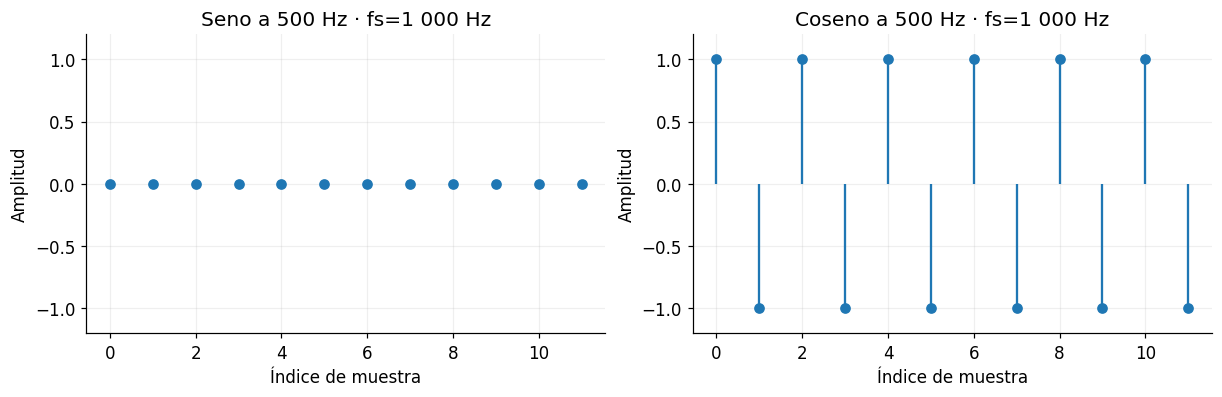

Magnitud máxima de las muestras del seno: 4.899825157862589e-15
Los residuos cercanos a 1e-15 son redondeo numérico, no un tono recuperable.


In [9]:
# Experimento autocontenido: justo en Nyquist la fase es decisiva.
fs_ny = 1000
n_ny = np.arange(12)
seno_ny = np.sin(2*np.pi*500*n_ny/fs_ny)
coseno_ny = np.cos(2*np.pi*500*n_ny/fs_ny)
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
for ax, x, nombre in zip(ejes, [seno_ny, coseno_ny], ["Seno a 500 Hz", "Coseno a 500 Hz"]):
    ax.stem(n_ny, x, basefmt=" ")
    ax.set(xlabel="Índice de muestra", ylabel="Amplitud", ylim=(-1.2,1.2), title=nombre+" · fs=1 000 Hz")
plt.show()
print("Magnitud máxima de las muestras del seno:", np.max(np.abs(seno_ny)))
print("Los residuos cercanos a 1e-15 son redondeo numérico, no un tono recuperable.")

<a id="tema-5" name="tema-5"></a>

## 5. Cuantización

El muestreo discretiza **el tiempo**; la cuantización discretiza **la amplitud**. En una representación de $b$ bits hay $2^b$ códigos posibles por muestra: con 16 bits, 65 536.

Visualizaremos una cuantización didáctica de solo 3 bits (8 niveles). El redondeo introduce un error. Este ejemplo usa niveles uniformes entre −1 y 1; ilustra el principio y no reproduce todos los detalles de un convertidor físico.

**No confundir:** guardar un arreglo como `float32` no significa que el micrófono haya capturado 32 bits de precisión efectiva.

[**↑ Volver al índice**](#indice)

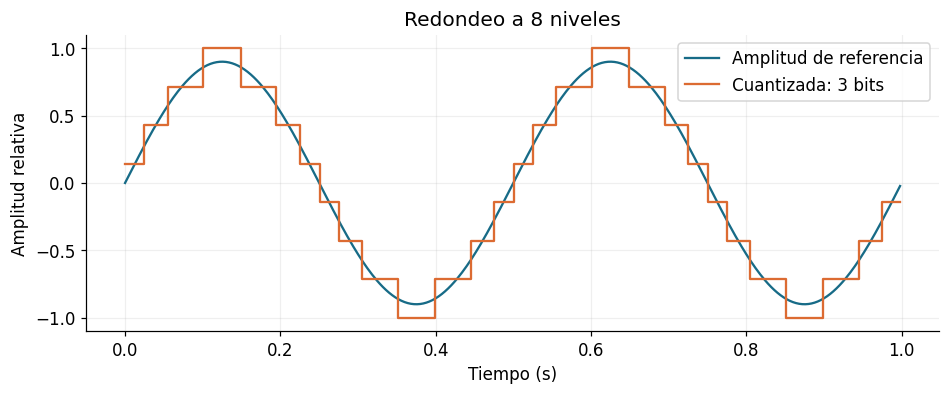

Error absoluto máximo en este ejemplo: 0.1429


In [10]:
bits = 3
niveles = 2 ** bits
tq = np.linspace(0, 1, 500, endpoint=False)
original = 0.9 * np.sin(2 * np.pi * 2 * tq)
paso = 2 / (niveles - 1)
cuantizada = np.round((original + 1) / paso) * paso - 1
fig, ax = plt.subplots()
ax.plot(tq, original, color=COLOR, label="Amplitud de referencia")
ax.step(tq, cuantizada, where="mid", color=ACENTO, label="Cuantizada: 3 bits")
ax.set(xlabel="Tiempo (s)", ylabel="Amplitud relativa", title="Redondeo a 8 niveles")
ax.legend()
plt.show()
print(f"Error absoluto máximo en este ejemplo: {np.max(np.abs(original-cuantizada)):.4f}")

<a id="tema-6" name="tema-6"></a>

## 6. Amplitud normalizada y saturación

Para nuestros reproductores usaremos valores entre −1 y 1. Si multiplicamos la amplitud demasiado y recortamos lo que queda fuera de ese intervalo, aparece **saturación o clipping**: se deforman los picos.

`np.clip` limita valores; no recupera la señal original. Tampoco es lo mismo que escalar toda la señal por un factor. Un arreglo flotante puede contener valores mayores que 1, pero aquí no los enviaremos directamente al reproductor.

[**↑ Volver al índice**](#indice)

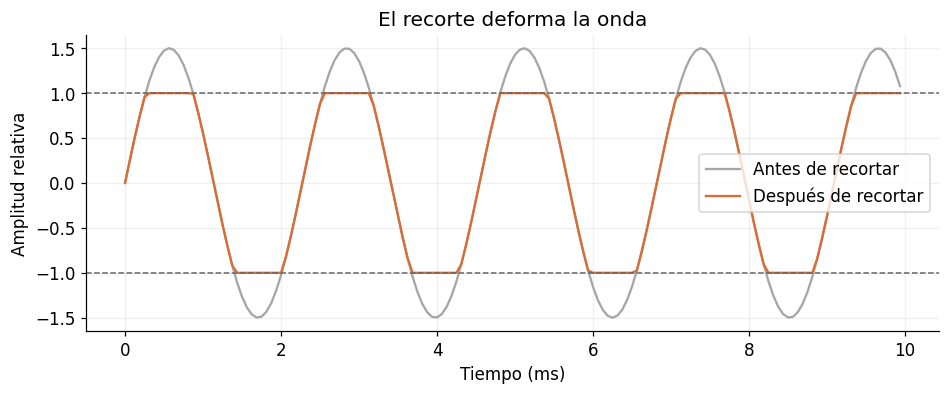

In [11]:
excesiva = 1.5 * np.sin(2 * np.pi * 440 * t)
recortada = np.clip(excesiva, -1, 1)
fig, ax = plt.subplots()
ax.plot(t[vista] * 1000, excesiva[vista], color="0.65", label="Antes de recortar")
ax.plot(t[vista] * 1000, recortada[vista], color=ACENTO, label="Después de recortar")
ax.axhline(1, color="0.4", linestyle="--", linewidth=1)
ax.axhline(-1, color="0.4", linestyle="--", linewidth=1)
ax.set(xlabel="Tiempo (ms)", ylabel="Amplitud relativa", title="El recorte deforma la onda")
ax.legend()
plt.show()

<a id="tema-7" name="tema-7"></a>

## 7. Lectura y escritura de archivos WAV

Un archivo WAV puede almacenar las muestras junto con información como la frecuencia de muestreo. Aquí crearemos nuestro propio archivo: no necesitas subir nada ni descargar grabaciones.

`wavfile.write(ruta, fs, datos)` escribe el archivo. `wavfile.read(ruta)` devuelve **primero la frecuencia de muestreo y después el arreglo**. El tipo de ese arreglo depende del formato del archivo: en este ejemplo será `float32`; otros WAV pueden usar enteros como `int16`.

Si un archivo usa enteros PCM con signo de 16 bits, convertirlo a escala flotante suele requerir dividir entre 32 768; usar solo `.astype(np.float32)` cambia el tipo, **no la escala**. No aplicaremos esa división a nuestro WAV porque ya tiene valores flotantes normalizados.

La duración de una grabación de $N$ muestras por canal es $N/f_s$. El tiempo de la última muestra es $(N-1)/f_s$: son cantidades ligeramente distintas.

[**↑ Volver al índice**](#indice)

In [12]:
ruta = CARPETA / "tono_440Hz.wav"
wavfile.write(str(ruta), fs, audio)
fs_leida, audio_leido = wavfile.read(str(ruta))

print("Archivo:", ruta)
print("Frecuencia de muestreo:", fs_leida, "muestras/s")
print("Forma:", audio_leido.shape)
print("Tipo:", audio_leido.dtype)
print(f"Duración: {audio_leido.shape[0] / fs_leida:.3f} s")
print(f"Tiempo de la última muestra: {(audio_leido.shape[0]-1)/fs_leida:.7f} s")
print("¿Se conservaron los valores?", np.allclose(audio, audio_leido))
display(Audio(audio_leido, rate=fs_leida, normalize=False))

Archivo: audio_parte1/tono_440Hz.wav
Frecuencia de muestreo: 16000 muestras/s
Forma: (16000,)
Tipo: float32
Duración: 1.000 s
Tiempo de la última muestra: 0.9999375 s
¿Se conservaron los valores? True


### Cambiar `rate` no es remuestrear

Si reproducimos las mismas 16 000 muestras a 8 000 muestras/s, tardarán 2 segundos y el tono de 440 Hz se escuchará a 220 Hz. Cambiamos la velocidad de reproducción.

**Remuestrear correctamente** significa calcular nuevas muestras para cambiar la frecuencia de muestreo conservando duración y contenido dentro de la banda permitida. Se aplica en el preprocesamiento del conjunto de voz; no basta con cambiar una variable.

In [13]:
fs_reproduccion = fs // 2
print(f"Duración al reproducir: {len(audio) / fs_reproduccion:.1f} s")
print(f"Frecuencia aparente del tono: {frecuencia * fs_reproduccion / fs:.0f} Hz")
display(Audio(audio, rate=fs_reproduccion, normalize=False))

Duración al reproducir: 2.0 s
Frecuencia aparente del tono: 220 Hz


<a id="tema-8" name="tema-8"></a>

## 8. Audio mono y estéreo

**Mono** contiene un canal. **Estéreo** contiene dos: izquierdo y derecho. Un canal es una secuencia de amplitudes, no una frecuencia individual.

| Objeto | Forma | Significado |
|---|---|---|
| Audio mono de este ejemplo | `(16000,)` | 16 000 muestras en un canal |
| Estéreo para `wavfile` | `(16000, 2)` | Muestras × canales |
| Estéreo para `Audio` | `(2, 16000)` | Canales × muestras |

`np.column_stack` coloca dos señales como columnas. `.T` transpone el arreglo: intercambia sus ejes. Cada librería puede esperar un orden distinto; siempre revisaremos `shape`.

[**↑ Volver al índice**](#indice)

In [14]:
izquierdo = (0.2 * np.sin(2 * np.pi * 440 * t)).astype(np.float32)
derecho = (0.2 * np.sin(2 * np.pi * 660 * t)).astype(np.float32)
estereo = np.column_stack([izquierdo, derecho])
mono = estereo.mean(axis=1)  # Promediamos canales para cada instante.

print("Estéreo para WAV:", estereo.shape)
print("Estéreo para reproductor:", estereo.T.shape)
print("Mono:", mono.shape)
print("Estéreo: 440 Hz a la izquierda y 660 Hz a la derecha")
display(Audio(estereo.T, rate=fs, normalize=False))
print("Mezcla mono: ambos tonos en el mismo canal")
display(Audio(mono, rate=fs, normalize=False))

Estéreo para WAV: (16000, 2)
Estéreo para reproductor: (2, 16000)
Mono: (16000,)
Estéreo: 440 Hz a la izquierda y 660 Hz a la derecha


Mezcla mono: ambos tonos en el mismo canal


Promediar canales es una conversión sencilla a mono, pero puede cancelar componentes si los canales tienen fases opuestas. Aquí lo usamos para entender los ejes, no como una regla universal.

<a id="tema-9" name="tema-9"></a>

## 9. Ejercicio: generación de tonos

Modifica los cuatro parámetros y vuelve a ejecutar. Cambia **uno a la vez** para identificar su efecto. Predice primero qué ocurrirá con el número de muestras, el periodo y el sonido.

`assert` comprueba una condición y detiene la celda con un mensaje si no se cumple. En este laboratorio restringimos la frecuencia a menos de Nyquist y la amplitud a un intervalo cómodo para los ejemplos.

[**↑ Volver al índice**](#indice)

Muestras: 12000 | Duración real: 0.7500 s
Periodo: 3.030 ms | Nyquist: 8000 Hz


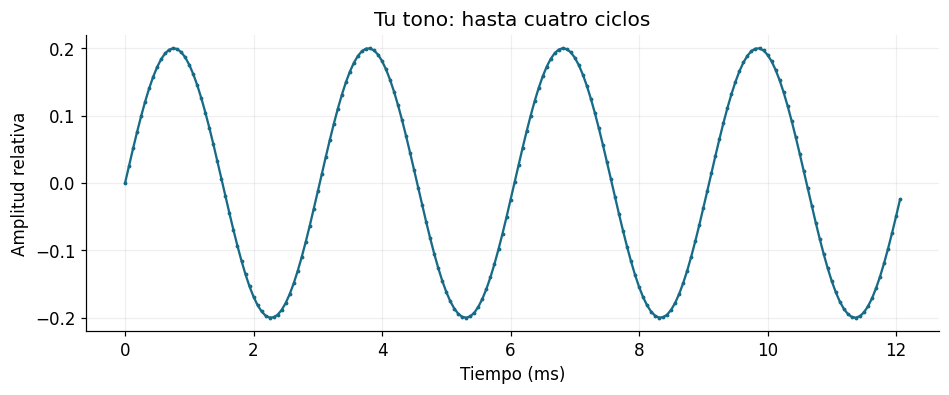

In [15]:
# Edita estos valores.
mi_fs = 16_000
mi_duracion = 0.75
mi_frecuencia = 330
mi_amplitud = 0.2

assert mi_fs > 0 and mi_duracion > 0, "Usa fs y duración positivos."
assert 0 < mi_frecuencia < mi_fs / 2, "Elige una frecuencia menor que Nyquist."
assert 0 < mi_amplitud <= 0.5, "Para este ejercicio usa amplitud entre 0 y 0.5."
mi_N = int(round(mi_fs * mi_duracion))
assert mi_N >= 2, "Genera al menos dos muestras."
mi_t = np.arange(mi_N) / mi_fs
mi_audio = (mi_amplitud * np.sin(2*np.pi*mi_frecuencia*mi_t)).astype(np.float32)

print(f"Muestras: {mi_N} | Duración real: {mi_N/mi_fs:.4f} s")
print(f"Periodo: {1000/mi_frecuencia:.3f} ms | Nyquist: {mi_fs/2:.0f} Hz")
display(Audio(mi_audio, rate=mi_fs, normalize=False))
ventana = mi_t < min(mi_N/mi_fs, 4/mi_frecuencia)
fig, ax = plt.subplots()
ax.plot(mi_t[ventana]*1000, mi_audio[ventana], ".-", color=COLOR, markersize=3)
ax.set(xlabel="Tiempo (ms)", ylabel="Amplitud relativa", title="Tu tono: hasta cuatro ciclos")
plt.show()

<a id="tema-10" name="tema-10"></a>

## 10. Ejercicios de comprensión

Responde en una celda Markdown antes de consultar las respuestas.

1. ¿Cuántas muestras por canal tiene un audio de 2.5 segundos a 16 000 muestras/s?
2. ¿Qué cambia si aumentas la amplitud de 0.1 a 0.3 y conservas la frecuencia?
3. ¿Cuál es el periodo de un tono de 500 Hz, en milisegundos?
4. ¿Puede un muestreo de 8 000 muestras/s representar sin ambigüedad un tono de 6 000 Hz?
5. Un arreglo leído con `wavfile` tiene forma `(32000, 2)` y $f_s=16000$. ¿Cuántos canales y cuánto tiempo contiene?
6. ¿Por qué cambiar únicamente `rate` de 16 000 a 8 000 no es un remuestreo correcto?
7. ¿Muestreo y cuantización significan lo mismo?
8. Genera 0.5 segundos de un tono de 600 Hz a 16 000 muestras/s, con amplitud 0.2. Escúchalo y grafica tres ciclos.

### Respuestas — consúltalas después de intentarlo

1. $2.5\times16000=40000$ muestras por canal.
2. Se triplica la amplitud numérica; no cambian ni frecuencia ni periodo. El volumen percibido no sigue necesariamente una proporción lineal.
3. $T=1/500=0.002$ s = **2 ms**.
4. No. Nyquist es 4 000 Hz y el tono queda por encima.
5. Dos canales y $32000/16000=2$ segundos.
6. Conserva las muestras, pero modifica su ritmo de reproducción: duplica la duración y reduce a la mitad las frecuencias aparentes.
7. No: el muestreo discretiza tiempo y la cuantización, amplitud.
8. Debes obtener 8 000 muestras y mostrar aproximadamente 5 ms para observar tres ciclos.

[**↑ Volver al índice**](#indice)

<a id="tema-11" name="tema-11"></a>

## 11. Organización del contenido y referencias

El cuaderno reúne los conceptos de audio y su aplicación a la preparación de comandos de voz.

| Parte | Contenido |
|---|---|
| 1 · Audio digital | Señales, muestreo, cuantización y archivos WAV. |
| 2 · Fourier | Transformada discreta, magnitud, fase y ventanas. |
| 3 · Espectrogramas | STFT, solapamiento y reconstrucción. |
| 4 · Características | Mel, log-Mel y MFCC. |
| Aplicación final | Speech Commands, preprocesamiento, tensores, `Dataset` y `DataLoader`. |

Las arquitecturas de redes se describen como introducción. No se entrenan modelos ni se presentan métricas experimentales.

### Documentación para consultar

- [NumPy: creación de secuencias con `arange`](https://numpy.org/doc/stable/reference/generated/numpy.arange.html).
- [Matplotlib: gráficas con `plot`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html).
- [IPython: reproductor `Audio` y parámetro `normalize`](https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html#IPython.display.Audio).
- [SciPy: lectura de WAV y tipos de datos](https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.wavfile.read.html).
- [SciPy: escritura de WAV](https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.wavfile.write.html).

Las gráficas son experimentos numéricos generados en este cuaderno. No requieren imágenes externas.

[**↑ Volver al índice**](#indice)

# Parte 2 · Fourier desde cero

<a id="tema-12" name="tema-12"></a>

## 12. Suma de señales senoidales

En la parte 1 vimos amplitud frente al tiempo. Ahora construiremos una señal sumando tonos de **220, 440 y 880 Hz** con amplitudes distintas. Al sumarlos, las muestras se combinan punto por punto; la onda resultante ya no parece un solo seno.

**Pregunta:** si solo tuviéramos esa mezcla, ¿cómo encontraríamos las frecuencias presentes?

La idea de Fourier es describir la señal mediante componentes senoidales. Cambiamos de representación: del **dominio del tiempo** (qué amplitud hay en cada instante) al **dominio de la frecuencia** (qué componentes contribuyen y con qué magnitud y fase).

No necesitamos nuevas importaciones: `np.fft` forma parte de NumPy, cargado arriba. Ejecuta primero esa celda si acabas de abrir el cuaderno.

[**↑ Volver al índice**](#indice)

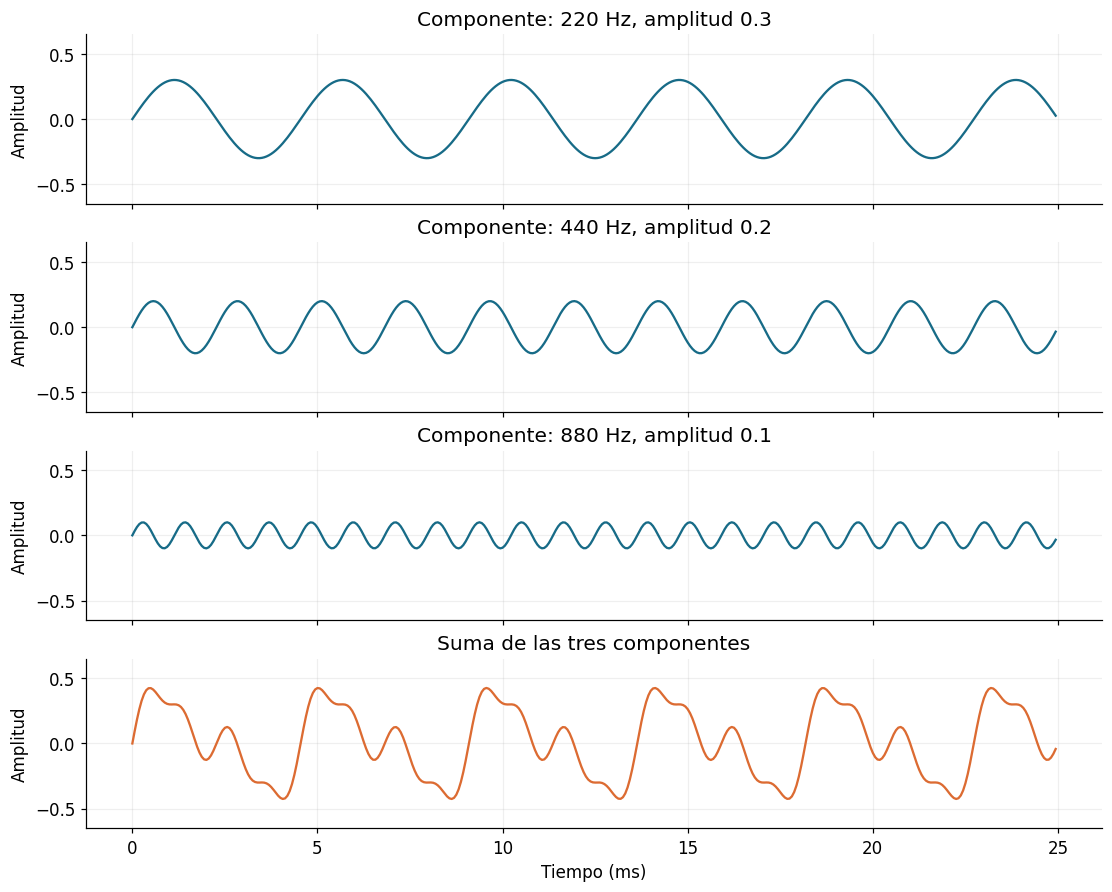

Componente de 220 Hz


Componente de 440 Hz


Componente de 880 Hz


Mezcla de las tres componentes


In [16]:
fs_f = 16_000
N_f = 16_000  # Un segundo: la rejilla de Fourier tendrá separación de 1 Hz.
t_f = np.arange(N_f) / fs_f
frecuencias_f = [220, 440, 880]
amplitudes_f = [0.30, 0.20, 0.10]
componentes_f = [A * np.sin(2*np.pi*f*t_f) for f, A in zip(frecuencias_f, amplitudes_f)]
mezcla_f = np.sum(componentes_f, axis=0)

fig, ejes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, constrained_layout=True)
vista_f = t_f < 0.025
for ax, senal, f, A in zip(ejes[:3], componentes_f, frecuencias_f, amplitudes_f):
    ax.plot(t_f[vista_f]*1000, senal[vista_f], color=COLOR)
    ax.set(ylabel="Amplitud", title=f"Componente: {f} Hz, amplitud {A}", ylim=(-0.65, 0.65))
ejes[3].plot(t_f[vista_f]*1000, mezcla_f[vista_f], color=ACENTO)
ejes[3].set(title="Suma de las tres componentes", xlabel="Tiempo (ms)", ylabel="Amplitud", ylim=(-0.65, 0.65))
plt.show()
for f, senal in zip(frecuencias_f, componentes_f):
    print(f"Componente de {f} Hz")
    display(Audio(senal, rate=fs_f, normalize=False))
print("Mezcla de las tres componentes")
display(Audio(mezcla_f, rate=fs_f, normalize=False))

<a id="tema-12a" name="tema-12a"></a>

## 12A. Representación gráfica de Fourier

Esta recreación se inspira en la imagen que compartiste, pero se genera con datos de nuestro propio ejemplo. Sigue los **mismos colores** de izquierda a derecha:

1. **Izquierda — tiempo:** las tres ondas se suman punto a punto y producen una sola señal, dibujada en negro. Solo se muestran 25 ms para distinguir las oscilaciones.
2. **Centro — componentes:** la vista en perspectiva separa las ondas según su frecuencia. El eje vertical representa amplitud. Separarlas visualmente no significa que se reproduzcan en momentos distintos: coexisten durante toda la grabación.
3. **Derecha — frecuencia:** cada seno produce un pico en su frecuencia, cuya altura recupera su amplitud con el escalado de este ejemplo. La FFT se calcula sobre el segundo completo, no solo los 25 ms mostrados.

**La flecha indica un cambio de representación, no el avance del tiempo.** Una línea temporal ondulada y un pico espectral describen la misma componente desde dos puntos de vista. El espectro mostrado contiene magnitud; la transformada completa también conserva fase.

Los tonos coinciden con bins de una observación de un segundo; por eso aquí se ven picos limpios. La sección 19 explica qué ocurre cuando no coinciden.

[**↑ Volver al índice**](#indice)

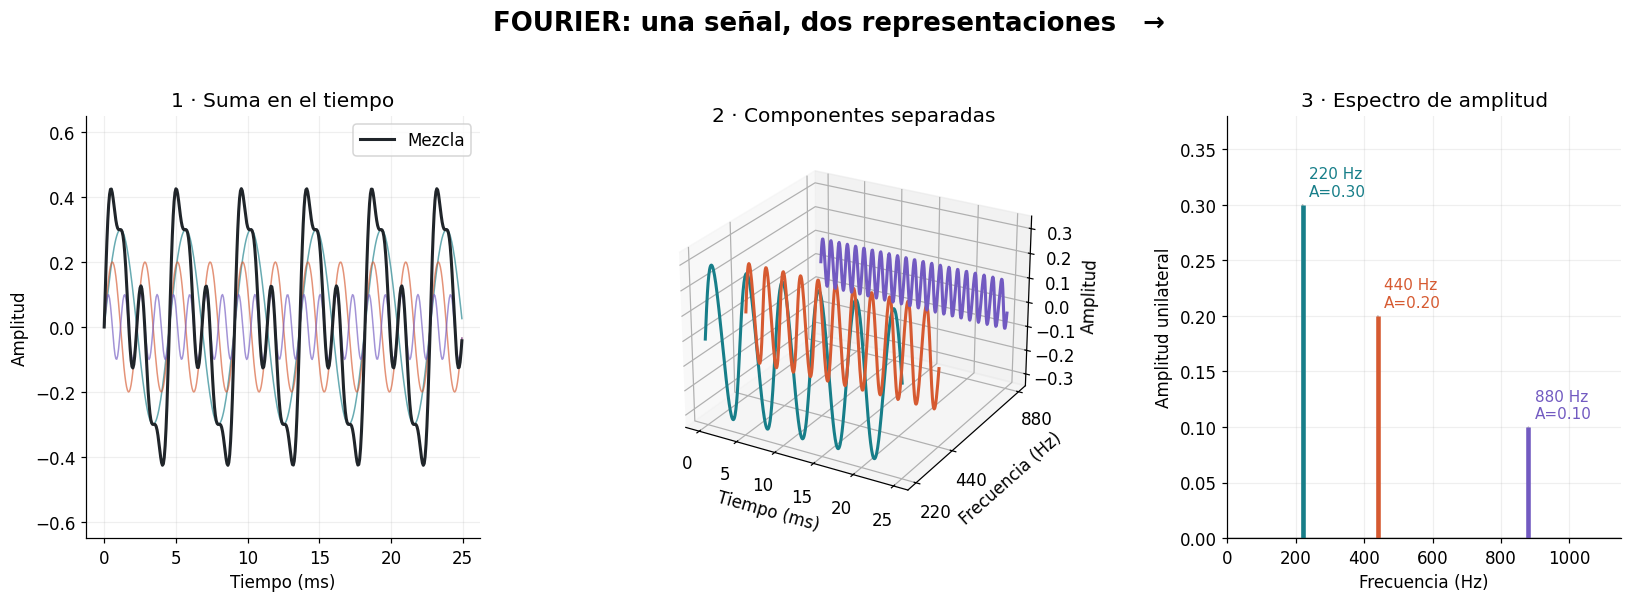

In [17]:

# Ilustración recreada con las componentes y la mezcla de la sección 12.
fig = plt.figure(figsize=(18, 6))
ax_t = fig.add_subplot(131)
ax_3d = fig.add_subplot(132, projection="3d")
ax_f = fig.add_subplot(133)
colores_vis = ["#177E89", "#D65A31", "#725AC1"]
mascara_vis = t_f < 0.025
for componente, f, A, color in zip(componentes_f, frecuencias_f, amplitudes_f, colores_vis):
    ax_t.plot(t_f[mascara_vis]*1000, componente[mascara_vis], color=color, alpha=0.65, linewidth=1)
    ax_3d.plot(t_f[mascara_vis]*1000, np.full(mascara_vis.sum(), f), componente[mascara_vis], color=color, linewidth=2)
ax_t.plot(t_f[mascara_vis]*1000, mezcla_f[mascara_vis], color="#20252A", linewidth=2, label="Mezcla")
ax_t.set(title="1 · Suma en el tiempo", xlabel="Tiempo (ms)", ylabel="Amplitud", ylim=(-0.65, 0.65))
ax_t.legend()
ax_3d.set(title="2 · Componentes separadas", xlabel="Tiempo (ms)", ylabel="Frecuencia (Hz)", zlabel="Amplitud", zlim=(-0.35, 0.35))
ax_3d.set_yticks(frecuencias_f)
ax_3d.view_init(elev=25, azim=-60)
X_vis = np.fft.rfft(mezcla_f)
f_vis = np.fft.rfftfreq(len(mezcla_f), d=1/fs_f)
a_vis = np.abs(X_vis)/len(mezcla_f)
a_vis[1:-1] *= 2
ax_f.plot(f_vis, a_vis, color="0.75", linewidth=1)
for f, A, color in zip(frecuencias_f, amplitudes_f, colores_vis):
    ax_f.vlines(f, 0, a_vis[np.argmin(abs(f_vis-f))], color=color, linewidth=3)
    ax_f.text(f+18, A+0.008, f"{f} Hz\nA={A:.2f}", color=color, fontsize=10)
ax_f.set(title="3 · Espectro de amplitud", xlabel="Frecuencia (Hz)", ylabel="Amplitud unilateral", xlim=(0, 1150), ylim=(0, 0.38))
fig.subplots_adjust(wspace=0.45, top=0.82, bottom=0.18)
fig.suptitle("FOURIER: una señal, dos representaciones   →", fontsize=17, fontweight="bold")
plt.show()


<a id="tema-13" name="tema-13"></a>

## 13. Comparación con senos y cosenos

Podemos multiplicar la señal por una onda de prueba y sumar los resultados. Si sus oscilaciones coinciden, las contribuciones pueden acumularse; si no, pueden cancelarse. Es parecido a medir cuánto se parece la señal a un patrón.

**Una sola comparación con seno no basta:** una componente podría estar desplazada en fase y dar una suma nula. Por eso necesitamos **dos referencias por frecuencia: seno y coseno**.

$$C(f)=\frac{2}{N}\sum_{n=0}^{N-1}x[n]\cos(2\pi f t_n),\qquad
S(f)=\frac{2}{N}\sum_{n=0}^{N-1}x[n]\sin(2\pi f t_n)$$
$$A_{\mathrm{estimada}}(f)=\sqrt{C(f)^2+S(f)^2}$$

El factor $2/N$ permite recuperar la amplitud de tonos interiores de la rejilla de Fourier bajo estas condiciones: señal real, ventana rectangular y ciclos completos en el fragmento. **No es una fórmula exacta de amplitud para cualquier frecuencia o ventana**; la componente constante y Nyquist requieren un tratamiento diferente.

`np.sum` suma los productos. `np.hypot(C, S)` calcula $\sqrt{C^2+S^2}$ sin perder la contribución de una fase distinta.

[**↑ Volver al índice**](#indice)

Prueba  110 Hz → C=-0.000, S=-0.000, amplitud≈0.000
Prueba  220 Hz → C=+0.000, S=+0.300, amplitud≈0.300
Prueba  330 Hz → C=-0.000, S=+0.000, amplitud≈0.000
Prueba  440 Hz → C=+0.000, S=+0.200, amplitud≈0.200
Prueba  550 Hz → C=+0.000, S=-0.000, amplitud≈0.000
Prueba  880 Hz → C=-0.000, S=+0.100, amplitud≈0.100


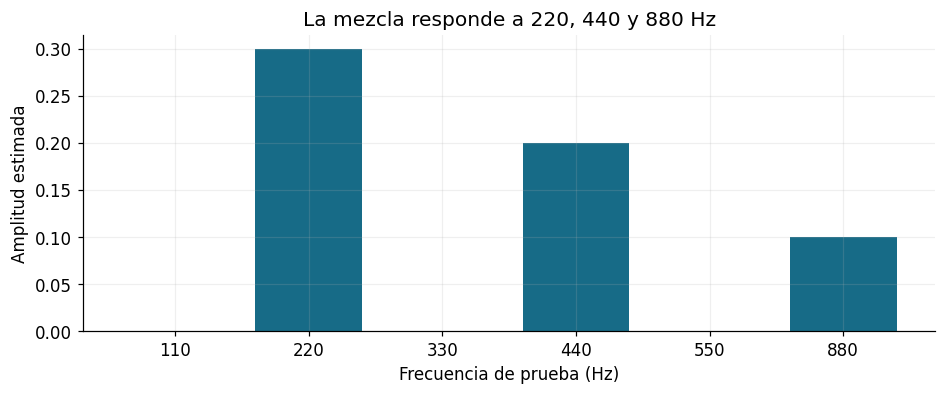

In [18]:
pruebas_f = [110, 220, 330, 440, 550, 880]
respuestas_f = []
for f in pruebas_f:
    C = 2 / N_f * np.sum(mezcla_f * np.cos(2*np.pi*f*t_f))
    S = 2 / N_f * np.sum(mezcla_f * np.sin(2*np.pi*f*t_f))
    respuesta = np.hypot(C, S)
    respuestas_f.append(respuesta)
    print(f"Prueba {f:4d} Hz → C={C:+.3f}, S={S:+.3f}, amplitud≈{respuesta:.3f}")
fig, ax = plt.subplots()
ax.bar([str(f) for f in pruebas_f], respuestas_f, color=COLOR)
ax.set(xlabel="Frecuencia de prueba (Hz)", ylabel="Amplitud estimada", title="La mezcla responde a 220, 440 y 880 Hz")
plt.show()

<a id="tema-14" name="tema-14"></a>

## 14. Transformada discreta de Fourier

La transformada de Fourier tiene versiones relacionadas:

| Nombre | Qué describe |
|---|---|
| Serie de Fourier | Una señal periódica como suma de armónicos. |
| Transformada de Fourier continua | Una representación en frecuencia de señales de tiempo continuo, bajo las condiciones matemáticas correspondientes. |
| Transformada discreta de Fourier —DFT— | Una lista de $N$ muestras mediante $N$ coeficientes complejos. Es la que calcularemos. |
| Transformada rápida de Fourier —FFT— | Una familia de algoritmos eficientes para calcular la DFT. **No es otra representación.** |

Con la convención predeterminada de NumPy:

$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N}$$

| Símbolo | Significado |
|---|---|
| $x[n]$ | Muestra de entrada en el índice $n$. |
| $N$ | Número de muestras que transformamos. |
| $k$ | Índice de un coeficiente o *bin* de frecuencia. |
| $j$ | Unidad imaginaria: $j^2=-1$; en Python se escribe `1j`. |
| $X[k]$ | Coeficiente complejo de Fourier. |

Por la identidad de Euler, $e^{-j\theta}=\cos(\theta)-j\sin(\theta)$: **cada coeficiente reúne las dos comparaciones anteriores**. La parte imaginaria lleva signo negativo por esta convención.

Para la mitad no negativa del espectro, $f_k=kf_s/N$. En la salida completa de `fft`, los índices superiores a la mitad corresponden a frecuencias negativas mediante $f_k=(k-N)f_s/N$; la frecuencia de Nyquist tiene una convención de signo particular cuando $N$ es par.

La DFT admite una interpretación como un periodo de una secuencia periódica. El audio real no tiene por qué repetirse: esa interpretación nos ayudará a entender los bordes del fragmento.

[**↑ Volver al índice**](#indice)

### Una DFT pequeña calculada directamente

Usaremos solo 8 muestras para ver lo que hace la fórmula. `np.exp` calcula la exponencial compleja. El bucle recorre cada frecuencia y suma la contribución de las ocho muestras.

La implementación directa requiere aproximadamente $N^2$ operaciones; los algoritmos FFT usuales reducen ese crecimiento a aproximadamente $N\log N$. Usaremos la fórmula para aprender y la FFT para trabajar.

In [19]:
N_mini = 8
n_mini = np.arange(N_mini)
x_mini = np.cos(2*np.pi*1*n_mini/N_mini)
X_manual = np.zeros(N_mini, dtype=complex)
for k in range(N_mini):
    X_manual[k] = np.sum(x_mini * np.exp(-2j*np.pi*k*n_mini/N_mini))
X_rapida = np.fft.fft(x_mini)
print("Muestras:", np.round(x_mini, 3))
print("DFT directa:", np.round(X_manual, 3))
print("FFT NumPy: ", np.round(X_rapida, 3))
print("Error máximo:", np.max(np.abs(X_manual-X_rapida)))
assert np.allclose(X_manual, X_rapida)

Muestras: [ 1.     0.707  0.    -0.707 -1.    -0.707 -0.     0.707]
DFT directa: [-0.+0.j  4.-0.j -0.-0.j  0.-0.j  0.-0.j  0.-0.j  0.-0.j  4.+0.j]
FFT NumPy:  [-0.+0.j  4.-0.j  0.+0.j -0.-0.j  0.+0.j -0.+0.j  0.+0.j  4.+0.j]
Error máximo: 4.090555313135825e-15


Los coeficientes de índices 1 y 7 tienen magnitud 4: representan las frecuencias positiva y negativa del coseno. En señales reales, esas mitades están relacionadas por **simetría conjugada**. No son dos sonidos independientes.

<a id="tema-15" name="tema-15"></a>

## 15. Cálculo de la FFT

Como el audio tiene muestras reales, usaremos `np.fft.rfft`, que devuelve solo la mitad no negativa. Devuelve $\lfloor N/2\rfloor+1$ coeficientes: para $N=16000$, son 8001.

| Expresión | Entrada | Salida |
|---|---|---|
| `np.fft.rfft(x)` | Muestras reales | Coeficientes complejos. |
| `np.fft.rfftfreq(N, d=1/fs)` | Longitud y separación temporal | Frecuencia en Hz de cada coeficiente. |
| `np.abs(X)` | Coeficientes complejos | Magnitud. |
| `np.angle(X)` | Coeficientes complejos | Fase en radianes. |

`rfft` no conoce $f_s$: transforma números. Necesitamos `rfftfreq` para colocar los coeficientes sobre un eje en **Hz**. Su argumento `d` es el tiempo entre muestras; no se le pasa `fs` directamente.

### Magnitud y amplitud de un tono

La magnitud cruda depende de $N$. Para construir un espectro de amplitud unilateral, dividimos por $N$ y duplicamos los coeficientes que tienen una pareja negativa. **No duplicamos el de 0 Hz ni el de Nyquist, si existe.**

La altura de un pico recupera la amplitud de un tono aislado que coincide con la rejilla en estas condiciones. La sección de fuga espectral analiza qué cambia si el tono cae entre dos bins.

[**↑ Volver al índice**](#indice)

Entrada: (16000,) | Salida rfft: (8001,)
Separación entre bins: 1.0 Hz


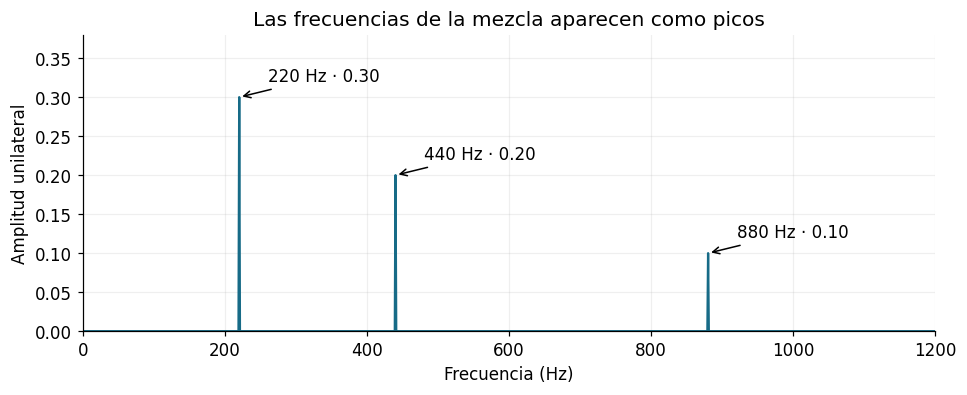

Bin 220: 220 Hz, amplitud 0.300
Bin 440: 440 Hz, amplitud 0.200
Bin 880: 880 Hz, amplitud 0.100


In [20]:
def espectro_amplitud(x, fs_senal):
    """Amplitud unilateral; señal real 1D, ventana rectangular, FFT sin relleno."""
    x = np.asarray(x)
    assert x.ndim == 1 and len(x) >= 2 and np.isrealobj(x)
    N_local = len(x)
    X = np.fft.rfft(x)
    freqs = np.fft.rfftfreq(N_local, d=1/fs_senal)
    amplitud = np.abs(X) / N_local
    if N_local % 2 == 0:
        amplitud[1:-1] *= 2  # N par: no duplicar DC ni Nyquist.
    else:
        amplitud[1:] *= 2    # N impar: no hay bin exacto en Nyquist.
    return freqs, amplitud, X

freq_f, amp_f, X_f = espectro_amplitud(mezcla_f, fs_f)
print("Entrada:", mezcla_f.shape, "| Salida rfft:", X_f.shape)
print(f"Separación entre bins: {freq_f[1]-freq_f[0]:.1f} Hz")
fig, ax = plt.subplots()
ax.plot(freq_f, amp_f, color=COLOR)
for f, A in zip(frecuencias_f, amplitudes_f):
    ax.annotate(f"{f} Hz · {A:.2f}", xy=(f, A), xytext=(f+40, A+0.02), arrowprops={"arrowstyle":"->"})
ax.set(xlim=(0, 1200), ylim=(0, 0.38), xlabel="Frecuencia (Hz)", ylabel="Amplitud unilateral", title="Las frecuencias de la mezcla aparecen como picos")
plt.show()
indices_f = np.argsort(amp_f)[-3:][::-1]
for k in indices_f:
    print(f"Bin {k}: {freq_f[k]:.0f} Hz, amplitud {amp_f[k]:.3f}")
assert np.allclose(amp_f[np.array(frecuencias_f)], amplitudes_f)

<a id="tema-16" name="tema-16"></a>

## 16. Magnitud y fase

Para $z=a+jb$, la magnitud es $\lvert z\rvert=\sqrt{a^2+b^2}$ y la fase es su ángulo en el plano complejo. La magnitud indica tamaño; la fase conserva información sobre la posición de las oscilaciones.

Para un coseno $A\cos(2\pi ft+\varphi)$ que coincide con un bin interior, la fase del coeficiente positivo es $\varphi$ (módulo $2\pi$). Para un seno, aparece un desplazamiento adicional de $-\pi/2$ por la convención usada.

**Solo interpretaremos fase donde la magnitud sea relevante.** En bins casi nulos, el ángulo puede reflejar errores numéricos sin significado útil.

[**↑ Volver al índice**](#indice)

Amplitud recuperada: 0.300
Fase esperada: 1.0472 rad | recuperada: 1.0472 rad


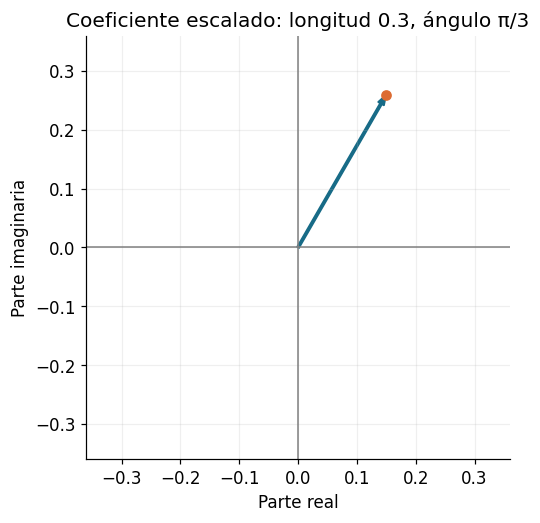

In [21]:
phi_f = np.pi / 3
cos_f = 0.3 * np.cos(2*np.pi*440*t_f + phi_f)
f_cos, a_cos, X_cos = espectro_amplitud(cos_f, fs_f)
k_cos = np.argmin(np.abs(f_cos-440))
print(f"Amplitud recuperada: {a_cos[k_cos]:.3f}")
print(f"Fase esperada: {phi_f:.4f} rad | recuperada: {np.angle(X_cos[k_cos]):.4f} rad")
fig, ax = plt.subplots(figsize=(5, 5))
z_f = X_cos[k_cos] * (2/N_f)
ax.arrow(0, 0, z_f.real, z_f.imag, width=0.004, color=COLOR, length_includes_head=True)
ax.scatter([z_f.real], [z_f.imag], color=ACENTO)
ax.axhline(0, color="0.5", linewidth=1)
ax.axvline(0, color="0.5", linewidth=1)
ax.set(xlim=(-0.36, 0.36), ylim=(-0.36, 0.36), xlabel="Parte real", ylabel="Parte imaginaria", title="Coeficiente escalado: longitud 0.3, ángulo π/3", aspect="equal")
plt.show()

<a id="tema-17" name="tema-17"></a>

## 17. Transformada inversa de Fourier

Fourier no elimina información si conservamos **todos los coeficientes complejos necesarios**. La inversa reconstruye las muestras:

$$x[n]=\frac{1}{N}\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}$$

`np.fft.irfft(X, n=N)` es la pareja de `rfft`; reconstruye una señal real aprovechando su simetría. Indicamos `n` explícitamente para conservar la longitud también cuando sea impar.

Guardar solamente magnitudes descarta la fase: no basta, en general, para recuperar la señal original. Esto será relevante porque muchos clasificadores usan espectrogramas de magnitud o potencia.

[**↑ Volver al índice**](#indice)

Error máximo con todos los coeficientes: 4.718e-16


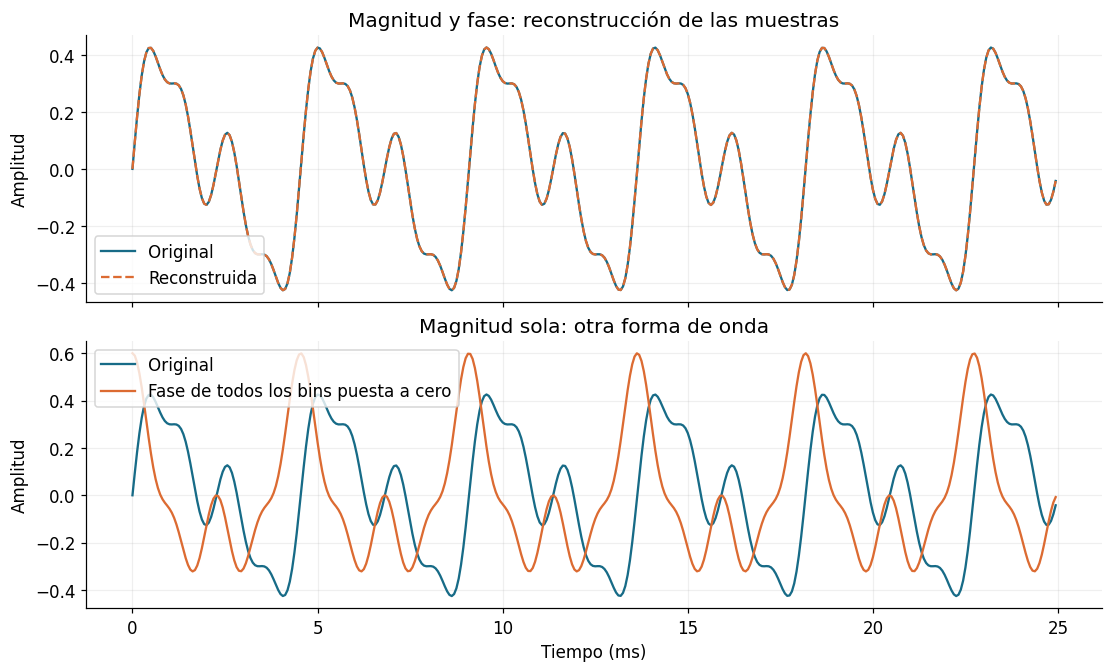

In [22]:
reconstruida_f = np.fft.irfft(X_f, n=N_f)
sin_fase_f = np.fft.irfft(np.abs(X_f), n=N_f)
error_f = np.max(np.abs(reconstruida_f-mezcla_f))
print(f"Error máximo con todos los coeficientes: {error_f:.3e}")
assert np.allclose(reconstruida_f, mezcla_f)
fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
ejes[0].plot(t_f[vista_f]*1000, mezcla_f[vista_f], label="Original", color=COLOR)
ejes[0].plot(t_f[vista_f]*1000, reconstruida_f[vista_f], "--", label="Reconstruida", color=ACENTO)
ejes[0].set(title="Magnitud y fase: reconstrucción de las muestras", ylabel="Amplitud")
ejes[0].legend()
ejes[1].plot(t_f[vista_f]*1000, mezcla_f[vista_f], label="Original", color=COLOR)
ejes[1].plot(t_f[vista_f]*1000, sin_fase_f[vista_f], label="Fase de todos los bins puesta a cero", color=ACENTO)
ejes[1].set(title="Magnitud sola: otra forma de onda", xlabel="Tiempo (ms)", ylabel="Amplitud")
ejes[1].legend()
plt.show()

### Experimento: retirar una componente

Copiaremos los coeficientes y pondremos a cero el bin de 440 Hz. La transformada inversa permite escuchar la mezcla resultante.

Esto funciona limpiamente porque nuestros tonos coinciden exactamente con bins. **No es un separador general de voces ni un método completo para quitar ruido**: en audio real las componentes suelen ocupar varios bins y los filtros abruptos pueden producir artefactos.

Mezcla original: 220 + 440 + 880 Hz


Mezcla después de retirar 440 Hz: 220 + 880 Hz


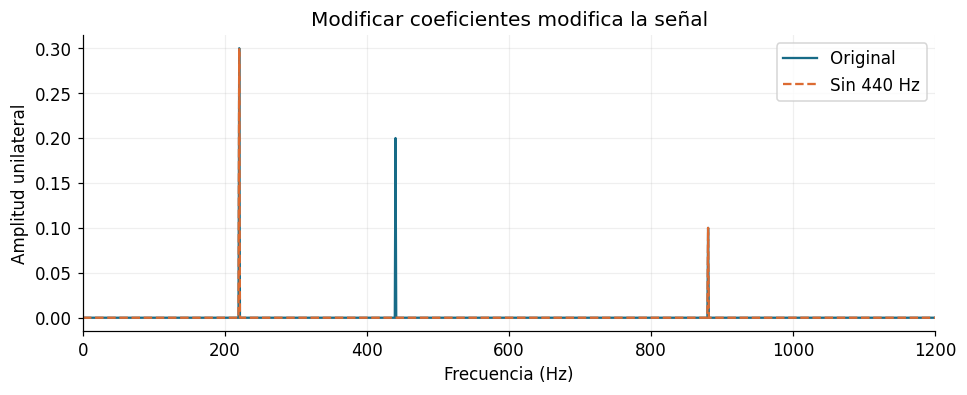

In [23]:
X_editada_f = X_f.copy()
k_quitar_f = np.argmin(np.abs(freq_f-440))
X_editada_f[k_quitar_f] = 0
filtrada_f = np.fft.irfft(X_editada_f, n=N_f)
print("Mezcla original: 220 + 440 + 880 Hz")
display(Audio(mezcla_f, rate=fs_f, normalize=False))
print("Mezcla después de retirar 440 Hz: 220 + 880 Hz")
display(Audio(filtrada_f, rate=fs_f, normalize=False))
f_edit, a_edit, _ = espectro_amplitud(filtrada_f, fs_f)
fig, ax = plt.subplots()
ax.plot(freq_f, amp_f, label="Original", color=COLOR)
ax.plot(f_edit, a_edit, "--", label="Sin 440 Hz", color=ACENTO)
ax.set(xlim=(0, 1200), xlabel="Frecuencia (Hz)", ylabel="Amplitud unilateral", title="Modificar coeficientes modifica la señal")
ax.legend()
plt.show()

<a id="tema-18" name="tema-18"></a>

## 18. Duración y resolución en frecuencia

Con una FFT de $N$ muestras sin relleno, la separación de bins es:

$$\Delta f=\frac{f_s}{N}=\frac{1}{D},\qquad D=\frac{N}{f_s}$$

Un fragmento de 0.05 s da una separación de 20 Hz; uno de 0.5 s da 2 Hz. **Observar más tiempo permite distinguir frecuencias más cercanas**, aunque la capacidad efectiva también depende de la ventana, el ruido y las amplitudes.

El *zero-padding* agrega ceros antes de calcular una FFT más larga: hace más densa la rejilla, pero **no añade observaciones ni mejora por sí solo la capacidad de separar componentes**. En la figura rellenaremos ambos fragmentos hasta una rejilla de 0.25 Hz para mostrar que una curva suave no implica mayor información.

[**↑ Volver al índice**](#indice)

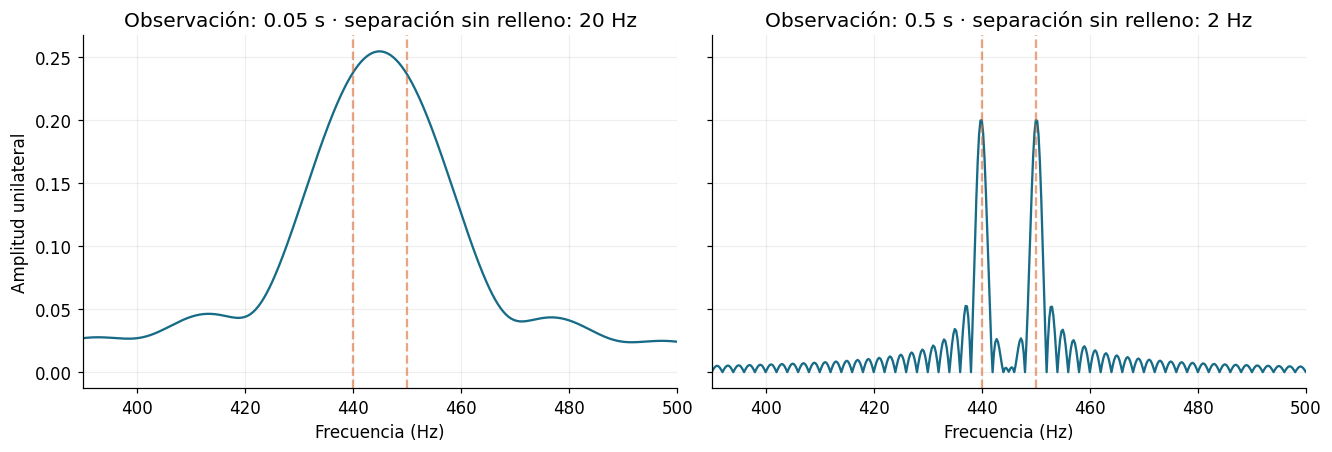

In [24]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
for ax, D in zip(ejes, [0.05, 0.5]):
    n_obs = int(fs_f*D)
    tiempos = np.arange(n_obs)/fs_f
    x_obs = 0.2*np.sin(2*np.pi*440*tiempos) + 0.2*np.sin(2*np.pi*450*tiempos)
    n_fft_demo = 64_000
    X_pad = np.fft.rfft(x_obs, n=n_fft_demo)
    f_pad = np.fft.rfftfreq(n_fft_demo, d=1/fs_f)
    # Escalar por las muestras observadas, no por la longitud rellenada.
    a_pad = np.abs(X_pad)/n_obs
    a_pad[1:-1] *= 2
    ax.plot(f_pad, a_pad, color=COLOR)
    for f in [440, 450]: ax.axvline(f, linestyle="--", color=ACENTO, alpha=0.6)
    ax.set(xlim=(390, 500), xlabel="Frecuencia (Hz)", title=f"Observación: {D} s · separación sin relleno: {1/D:g} Hz")
ejes[0].set_ylabel("Amplitud unilateral")
plt.show()

<a id="tema-19" name="tema-19"></a>

## 19. Fuga espectral

Si observamos 0.1 s, los bins están separados 10 Hz. Un tono de 440 Hz completa 44 ciclos en ese fragmento; uno de 443 Hz completa 44.3 y no coincide con la rejilla.

Un fragmento finito equivale a aplicar una ventana. La ventana rectangular conserva todas las muestras tal cual; al analizar una frecuencia entre bins aparece **fuga espectral**: la magnitud se distribuye entre varios coeficientes. No significa que el generador haya producido todas esas frecuencias como tonos independientes.

Una **ventana Hann** atenúa los extremos del fragmento. Reduce lóbulos laterales, pero ensancha el lóbulo principal: hay un compromiso. No elimina todos los efectos de observar una señal durante un tiempo finito.

Usaremos una Hann periódica construida con `np.hanning(N+1)[:-1]`. Dividir por la suma de la ventana compensa su ganancia para tonos centrados en bins; no vuelve exacta la amplitud del pico cuando el tono cae entre ellos.

[**↑ Volver al índice**](#indice)

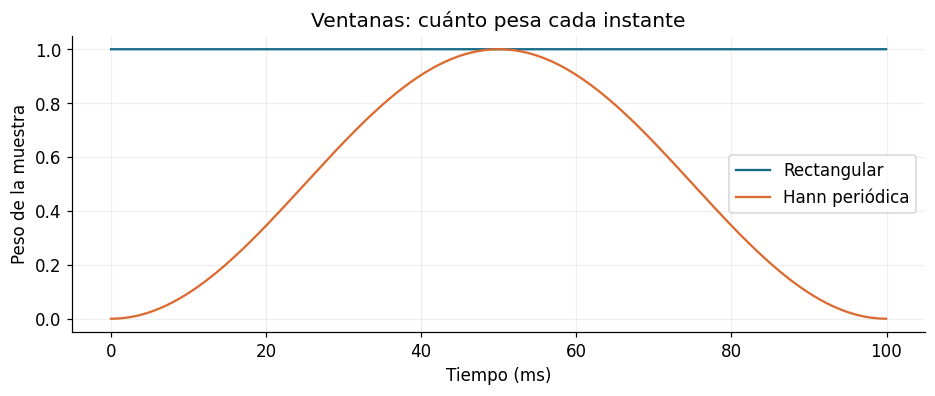

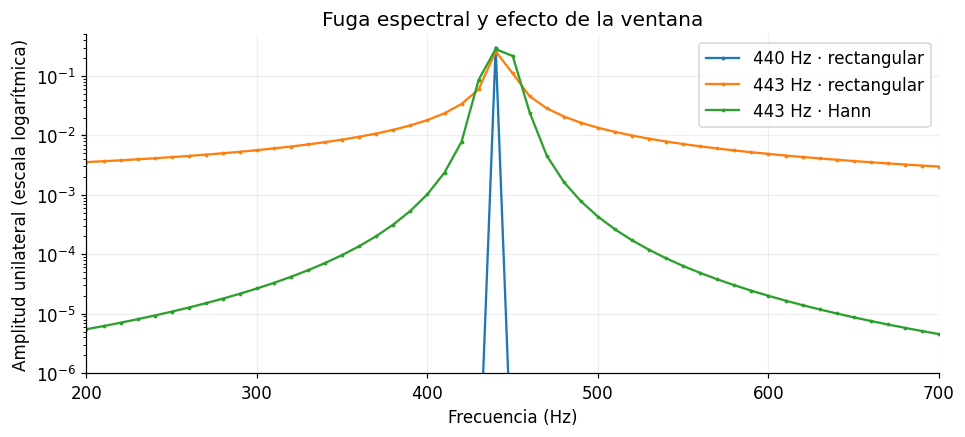

In [25]:
N_vent = 1600
t_vent = np.arange(N_vent)/fs_f
hann_f = np.hanning(N_vent+1)[:-1]
fig, ax = plt.subplots()
ax.plot(t_vent*1000, np.ones(N_vent), label="Rectangular", color=COLOR)
ax.plot(t_vent*1000, hann_f, label="Hann periódica", color=ACENTO)
ax.set(xlabel="Tiempo (ms)", ylabel="Peso de la muestra", title="Ventanas: cuánto pesa cada instante")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
for f_tono, ventana, etiqueta in [(440, np.ones(N_vent), "440 Hz · rectangular"), (443, np.ones(N_vent), "443 Hz · rectangular"), (443, hann_f, "443 Hz · Hann")]:
    x_vent = 0.3*np.sin(2*np.pi*f_tono*t_vent)
    X_vent = np.fft.rfft(x_vent*ventana)
    a_vent = np.abs(X_vent)/ventana.sum()
    a_vent[1:-1] *= 2
    f_vent = np.fft.rfftfreq(N_vent, d=1/fs_f)
    ax.semilogy(f_vent, np.maximum(a_vent, 1e-8), ".-", label=etiqueta, markersize=3)
ax.set(xlim=(200, 700), ylim=(1e-6, 0.5), xlabel="Frecuencia (Hz)", ylabel="Amplitud unilateral (escala logarítmica)", title="Fuga espectral y efecto de la ventana")
ax.legend()
plt.show()

<a id="tema-19a" name="tema-19a"></a>

## 19A. Ventana Hann

Al extraer un fragmento, la DFT lo interpreta como un periodo. Si el final no conecta suavemente con el principio, esa repetición contiene un salto. Ese borde contribuye a extender el espectro: la **fuga espectral** no es aliasing.

La Hann periódica es

$$w[n]=\tfrac12-\tfrac12\cos(2\pi n/L),\qquad n=0,\ldots,L-1.$$

Pesa más el centro y menos los extremos. La versión simétrica usa $L-1$ en el denominador; no son idénticas. Usamos la periódica para las FFT y para las identidades de solapamiento de este cuaderno.

**Analogía visual:** una fotografía recortada con un borde brusco crea una transición muy fuerte. Un borde difuminado suaviza esa transición, pero también difumina detalles cercanos. Hann hace algo semejante en el tiempo.

| Ventana rectangular | Ventana Hann |
|---|---|
| Conserva el mismo peso en todo el fragmento. | Reduce el peso de los extremos. |
| Lóbulo principal más estrecho. | Lóbulo principal más ancho. |
| Lóbulos laterales relativamente altos. | Lóbulos laterales menores; facilita observar componentes débiles lejos de una fuerte. |
| Es útil cuando encaja con el objetivo del análisis. | Es una opción habitual, no una obligación ni la mejor para todos los problemas. |

Hann **no permite separar arbitrariamente frecuencias próximas**, no quita ruido por sí sola y no evita el aliasing de adquisición. Aporta un compromiso útil entre fuga y resolución. Si un evento cae donde una ventana pesa poco, el solapamiento permite observarlo cerca del centro de otras ventanas.

La sección **27A** explica otra propiedad: con saltos adecuados, sus pesos se combinan de forma predecible para reconstruir audio sin subir y bajar artificialmente el volumen.

Referencia técnica: [SciPy, ventana Hann](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.windows.hann.html); F. J. Harris, *On the use of windows for harmonic analysis with the discrete Fourier transform* (1978), [DOI](https://doi.org/10.1109/PROC.1978.10837).

[**↑ Volver al índice**](#indice)

<a id="tema-20" name="tema-20"></a>

## 20. Amplitud, potencia y decibelios

No son términos intercambiables:

| Cantidad | Operación de base | Qué conserva |
|---|---|---|
| Coeficiente complejo | $X[k]$ | Magnitud y fase. |
| Magnitud | $\lvert X[k]\rvert$ | Tamaño del coeficiente. |
| Potencia espectral sin normalizar | $\lvert X[k]\rvert^{2}$ | Magnitud al cuadrado; su escala depende de la normalización. |
| Magnitud en dB relativos | $20\log_{10}(A/A_{\mathrm{ref}})$ | Razón de amplitudes en escala logarítmica. |
| Potencia en dB relativos | $10\log_{10}(P/P_{\mathrm{ref}})$ | Razón de potencias en escala logarítmica. |

Aquí usaremos como referencia el pico de amplitud: el máximo será **0 dB**, y un pico con la mitad de amplitud estará aproximadamente a −6.02 dB. Estos valores **no son dB SPL** (presión sonora calibrada) ni medidas del volumen físico de tus audífonos.

Las convenciones de normalización importan al interpretar potencia o densidad de potencia; no basta con llamar “potencia física” a cualquier magnitud al cuadrado. Para construir espectrogramas conservaremos una convención explícita.

`np.maximum` limita la razón antes del logaritmo para evitar $\log(0)$. Mostraremos hasta −80 dB.

[**↑ Volver al índice**](#indice)

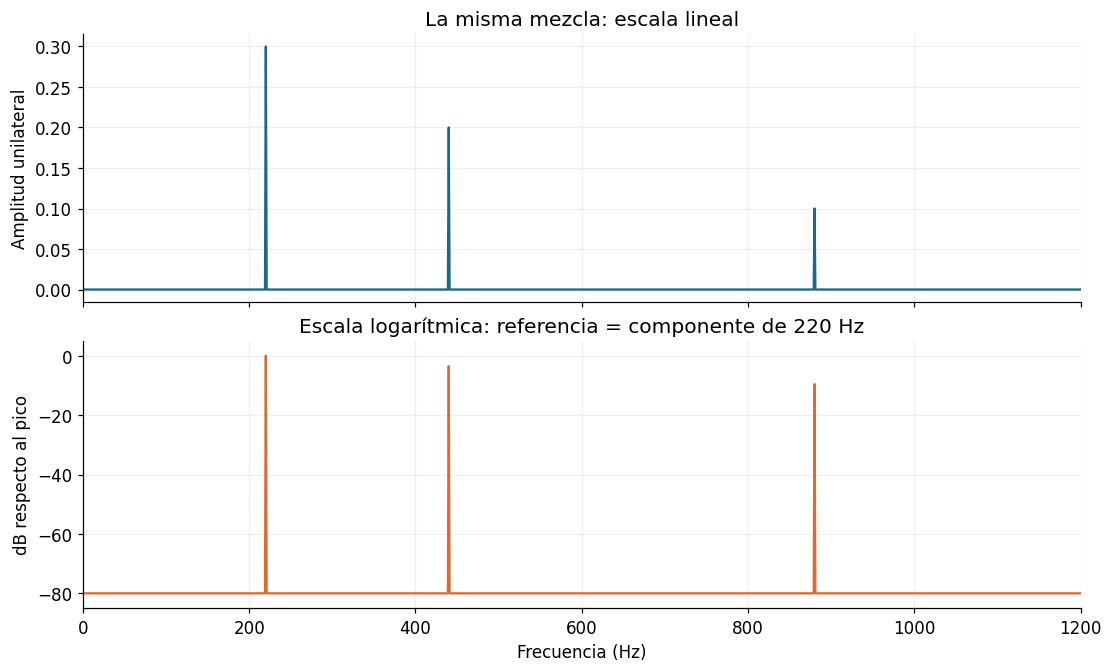

220 Hz: amplitud 0.30 → 0.00 dB relativos
440 Hz: amplitud 0.20 → -3.52 dB relativos
880 Hz: amplitud 0.10 → -9.54 dB relativos


In [26]:
referencia_f = amp_f.max()
amp_db_f = 20*np.log10(np.maximum(amp_f/referencia_f, 10**(-80/20)))
fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
ejes[0].plot(freq_f, amp_f, color=COLOR)
ejes[0].set(ylabel="Amplitud unilateral", title="La misma mezcla: escala lineal")
ejes[1].plot(freq_f, amp_db_f, color=ACENTO)
ejes[1].set(xlim=(0, 1200), ylim=(-85, 5), xlabel="Frecuencia (Hz)", ylabel="dB respecto al pico", title="Escala logarítmica: referencia = componente de 220 Hz")
plt.show()
for f in frecuencias_f:
    k = np.argmin(np.abs(freq_f-f))
    print(f"{f} Hz: amplitud {amp_f[k]:.2f} → {amp_db_f[k]:.2f} dB relativos")

<a id="tema-21" name="tema-21"></a>

## 21. Información temporal en el espectro

La voz cambia durante una palabra. Un espectro de magnitud calculado sobre todo el audio no muestra directamente **cuándo** aparece cada componente.

Construiremos un audio A con 300 Hz en la primera mitad y 900 Hz en la segunda. B tendrá las mitades intercambiadas. B es un desplazamiento circular de A: esa operación cambia las fases, pero conserva la magnitud de su DFT.

**No estamos diciendo que la transformada compleja completa pierda el orden temporal.** Lo que no distingue estos ejemplos es el espectro global de magnitud, que es la representación visual que hemos usado.

[**↑ Volver al índice**](#indice)

A: primero 300 Hz, después 900 Hz


B: primero 900 Hz, después 300 Hz


¿Coinciden sus magnitudes globales? True


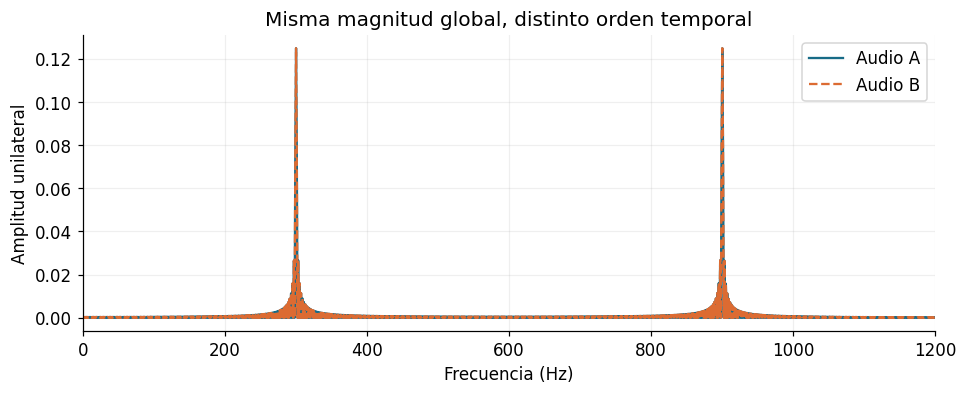

In [27]:
N_orden = 16_000
t_mitad = np.arange(N_orden//2)/fs_f
primera = 0.25*np.sin(2*np.pi*300*t_mitad)
segunda = 0.25*np.sin(2*np.pi*900*t_mitad)
audio_A = np.concatenate([primera, segunda])
audio_B = np.roll(audio_A, N_orden//2)
f_orden, a_A, _ = espectro_amplitud(audio_A, fs_f)
_, a_B, _ = espectro_amplitud(audio_B, fs_f)
print("A: primero 300 Hz, después 900 Hz")
display(Audio(audio_A, rate=fs_f, normalize=False))
print("B: primero 900 Hz, después 300 Hz")
display(Audio(audio_B, rate=fs_f, normalize=False))
print("¿Coinciden sus magnitudes globales?", np.allclose(a_A, a_B))
fig, ax = plt.subplots()
ax.plot(f_orden, a_A, label="Audio A", color=COLOR)
ax.plot(f_orden, a_B, "--", label="Audio B", color=ACENTO)
ax.set(xlim=(0, 1200), xlabel="Frecuencia (Hz)", ylabel="Amplitud unilateral", title="Misma magnitud global, distinto orden temporal")
ax.legend()
plt.show()

El análisis por STFT utiliza **fragmentos cortos sucesivos**, conservando tanto el eje de tiempo como el de frecuencia. Ese procedimiento corresponde a la **transformada de Fourier de tiempo corto (STFT)** y al **espectrograma**.

<a id="tema-22" name="tema-22"></a>

## 22. Ejercicio: análisis de una mezcla

Edita las frecuencias y amplitudes. Mantén inicialmente frecuencias enteras y 1 segundo de duración para que coincidan con bins. Después usa 437.5 Hz y observa cómo cambia el espectro.

`np.argsort` ordena índices por magnitud. Seleccionar los tres mayores bins es un ejercicio válido para estos tonos separados y centrados; **no es un detector general de tres fuentes**, porque varios bins de un mismo tono pueden dominar si hay fuga espectral.

[**↑ Volver al índice**](#indice)

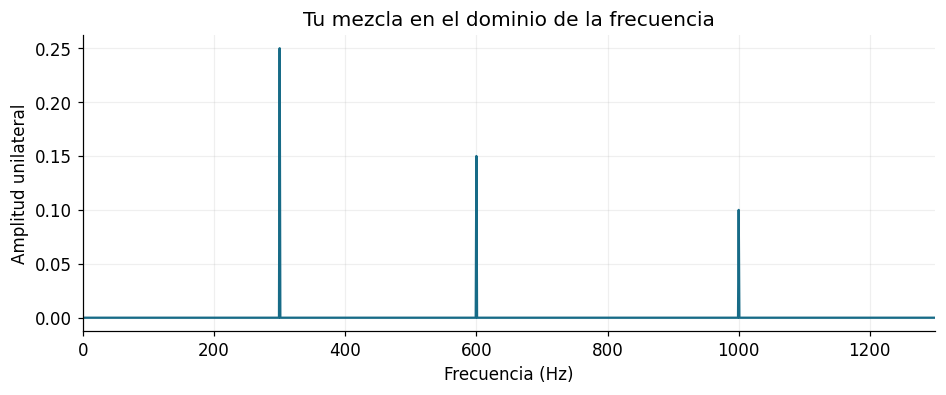

Bin destacado: 300.00 Hz · amplitud 0.2500
Bin destacado: 600.00 Hz · amplitud 0.1500
Bin destacado: 1000.00 Hz · amplitud 0.1000


In [28]:
mis_frecuencias = [300, 600, 1000]
mis_amplitudes = [0.25, 0.15, 0.10]
mi_fs_fft = 16_000
mi_duracion_fft = 1.0
assert len(mis_frecuencias) == len(mis_amplitudes) and len(mis_frecuencias) > 0
assert all(0 < f < mi_fs_fft/2 for f in mis_frecuencias)
assert all(a > 0 for a in mis_amplitudes) and sum(mis_amplitudes) <= 0.8
assert mi_duracion_fft > 0
mi_t_fft = np.arange(int(round(mi_fs_fft*mi_duracion_fft)))/mi_fs_fft
mi_mezcla_fft = np.sum([a*np.sin(2*np.pi*f*mi_t_fft) for f,a in zip(mis_frecuencias,mis_amplitudes)], axis=0)
mis_bins, mis_amps, mis_coef = espectro_amplitud(mi_mezcla_fft, mi_fs_fft)
display(Audio(mi_mezcla_fft, rate=mi_fs_fft, normalize=False))
fig, ax = plt.subplots()
ax.plot(mis_bins, mis_amps, color=COLOR)
ax.set(xlim=(0, min(mi_fs_fft/2, max(mis_frecuencias)*1.3)), xlabel="Frecuencia (Hz)", ylabel="Amplitud unilateral", title="Tu mezcla en el dominio de la frecuencia")
plt.show()
for k in np.argsort(mis_amps)[-3:][::-1]:
    print(f"Bin destacado: {mis_bins[k]:.2f} Hz · amplitud {mis_amps[k]:.4f}")

<a id="tema-23" name="tema-23"></a>

## 23. Ejercicios y respuestas

Responde primero en una celda Markdown:

1. ¿Qué diferencia hay entre DFT y FFT?
2. ¿Por qué comparamos con seno **y** coseno?
3. Si $f_s=16000$ y $N=8000$, ¿cuál es la duración observada y la separación entre bins sin relleno?
4. ¿Cuántos coeficientes entrega `rfft` para esas 8 000 muestras?
5. ¿Agregar ceros equivale a grabar durante más tiempo?
6. ¿Por qué un tono de 443 Hz presenta fuga con un fragmento de 0.1 s?
7. ¿Qué cambia al usar Hann? ¿Tiene algún costo?
8. ¿Podemos reconstruir en general las muestras exactas guardando solo magnitudes?
9. ¿Qué falta en el espectro de magnitud global para analizar el orden de sonidos en una palabra?
10. En el laboratorio cambia la amplitud de la componente de 600 Hz de 0.15 a 0.075. Predice el cambio en escala lineal y en dB respecto a la misma referencia.

### Respuestas comentadas

1. La DFT es la transformación matemática; la FFT es un algoritmo eficiente para calcularla.
2. Una sola referencia puede no detectar una componente por su fase. Ambas capturan sus dos proyecciones.
3. Duración de 0.5 s y separación de 2 Hz.
4. $8000/2+1=4001$ coeficientes complejos.
5. No: densifica la rejilla calculada, pero no añade información observada.
6. Los bins están a múltiplos de 10 Hz; 443 Hz queda entre ellos y no completa un número entero de ciclos.
7. Reduce lóbulos laterales y atenúa extremos, pero ensancha el lóbulo principal y exige considerar su escala.
8. No, en general también necesitamos fase. `irfft` sí reconstruye usando los coeficientes complejos conservados.
9. Localización temporal de las componentes. La STFT analizará ventanas sucesivas.
10. El pico se reduce a la mitad y disminuye aproximadamente 6.02 dB con la referencia fija.

[**↑ Volver al índice**](#indice)

<a id="tema-24" name="tema-24"></a>

## 24. Referencias sobre Fourier

Los ejemplos muestran cómo calcular e interpretar los coeficientes de Fourier y recuperar las muestras mediante la transformada inversa. La duración, la fase y la ventana determinan qué información puede obtenerse del análisis.

### Documentación de esta parte

- [NumPy: convenciones y normalización de Fourier](https://numpy.org/doc/stable/reference/routines.fft.html).
- [NumPy: `rfft`](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html).
- [NumPy: frecuencias de los bins con `rfftfreq`](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfftfreq.html).
- [NumPy: inversa `irfft`](https://numpy.org/doc/stable/reference/generated/numpy.fft.irfft.html).
- [NumPy: ventana Hann](https://numpy.org/doc/stable/reference/generated/numpy.hanning.html).

Todos los gráficos y audios de esta parte se generan con las celdas; no requieren archivos externos ni GPU.

[**↑ Volver al índice**](#indice)

# Parte 3 · STFT y espectrogramas

<a id="tema-25" name="tema-25"></a>

## 25. Análisis en tiempo y frecuencia

Un espectro global de magnitud resume todo el fragmento. Para analizar cómo cambia el audio, calcularemos Fourier sobre **ventanas cortas que avanzan en el tiempo**.

La **transformada de Fourier de tiempo corto (STFT)** entrega una matriz compleja: una columna por ventana y una fila por frecuencia. Un espectrograma suele representar su magnitud o su potencia con colores. Aquí usaremos **potencia en dB relativos**.

Crearemos dos tonos consecutivos (300 y 900 Hz) y un barrido que sube de 300 a 1 800 Hz. Son señales sintéticas para reconocer patrones, no grabaciones de voz. Speech Commands aporta los ejemplos de voz real de la aplicación final.

`librosa` es una librería de análisis de audio. Ya se importó arriba; esta parte no necesita descargar audios.

[**↑ Volver al índice**](#indice)

Dos tonos: 300 Hz durante un segundo y después 900 Hz


Barrido ascendente: 300 a 1 800 Hz


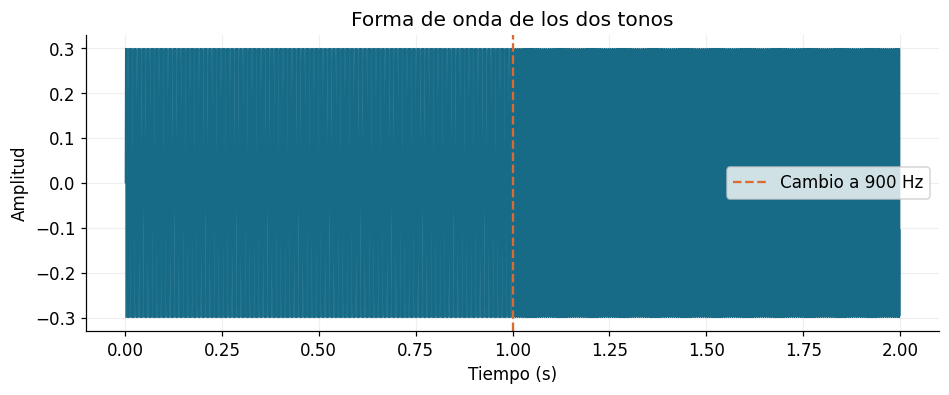

In [29]:
sr_s = 16_000
N_s = 32_000
t_s = np.arange(N_s)/sr_s
senal_s = np.where(t_s < 1.0, 0.3*np.sin(2*np.pi*300*t_s), 0.3*np.sin(2*np.pi*900*t_s))
# Frecuencia instantánea del barrido: f(t)=f0 + pendiente*t.
# La fase es la integral de 2*pi*f(t), no 2*pi*f(t)*t.
f0_s, f1_s = 300, 1800
pendiente_s = (f1_s-f0_s)/(N_s/sr_s)
barrido_s = 0.3*np.sin(2*np.pi*(f0_s*t_s + 0.5*pendiente_s*t_s**2))
print("Dos tonos: 300 Hz durante un segundo y después 900 Hz")
display(Audio(senal_s, rate=sr_s, normalize=False))
print("Barrido ascendente: 300 a 1 800 Hz")
display(Audio(barrido_s, rate=sr_s, normalize=False))
fig, ax = plt.subplots()
ax.plot(t_s, senal_s, linewidth=0.5, color=COLOR)
ax.axvline(1, linestyle="--", color=ACENTO, label="Cambio a 900 Hz")
ax.set(xlabel="Tiempo (s)", ylabel="Amplitud", title="Forma de onda de los dos tonos")
ax.legend()
plt.show()

<a id="tema-26" name="tema-26"></a>

## 26. Ventanas y solapamiento

En cada posición hacemos cuatro operaciones:

1. Tomar un fragmento de muestras.
2. Multiplicarlo por una ventana Hann para atenuar sus extremos.
3. Calcular `rfft` de ese fragmento.
4. Avanzar un número fijo de muestras y repetir.

Los fragmentos pueden solaparse. **Solapamiento no es duplicar sonidos:** solo observamos algunos instantes desde varias ventanas.

Usaremos inicialmente `n_fft = win_length = 512` y `hop_length = 128`. A 16 000 muestras/s, analizamos 32 ms cada vez y avanzamos 8 ms; el solapamiento es de 384 muestras (75%).

[**↑ Volver al índice**](#indice)

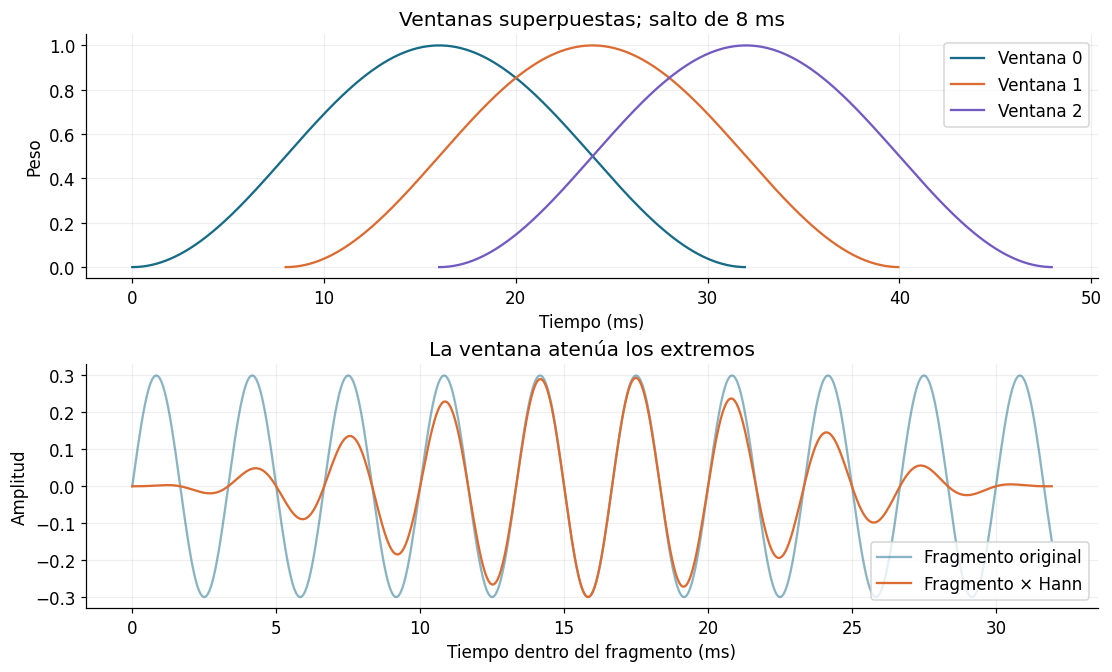

In [30]:
n_fft_s = 512
win_s = 512
hop_s = 128
ventana_s = np.hanning(win_s+1)[:-1]  # Hann periódica.
fig, ejes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
for m, color in zip(range(3), [COLOR, ACENTO, "#725AC1"]):
    inicio = m*hop_s
    tiempos = (inicio+np.arange(win_s))/sr_s*1000
    ejes[0].plot(tiempos, ventana_s, label=f"Ventana {m}", color=color)
segmento_s = senal_s[:win_s]
ejes[0].set(title="Ventanas superpuestas; salto de 8 ms", xlabel="Tiempo (ms)", ylabel="Peso")
ejes[0].legend()
ejes[1].plot(np.arange(win_s)/sr_s*1000, segmento_s, alpha=0.5, label="Fragmento original", color=COLOR)
ejes[1].plot(np.arange(win_s)/sr_s*1000, segmento_s*ventana_s, label="Fragmento × Hann", color=ACENTO)
ejes[1].set(xlabel="Tiempo dentro del fragmento (ms)", ylabel="Amplitud", title="La ventana atenúa los extremos")
ejes[1].legend()
plt.show()

<a id="tema-27" name="tema-27"></a>

## 27. Cálculo de la STFT con NumPy

Para este primer ejemplo, sin relleno en los extremos y con longitud de ventana igual a la FFT:

$$D[k,m]=\sum_{n=0}^{L-1}x[mH+n]w[n]e^{-j2\pi kn/L}$$

$L$ es la longitud de ventana, $H$ el salto, $m$ el índice de ventana y $k$ el bin de frecuencia. `w[n]` son los pesos Hann.

Si el audio tiene $N\geq L$ muestras, solo tomamos ventanas completas:

$$M=1+\left\lfloor\frac{N-L}{H}\right\rfloor,\qquad F=\lfloor L/2\rfloor+1.$$

La matriz tendrá forma **`(F, M)` = (frecuencias, ventanas temporales)**. `np.stack(..., axis=1)` coloca cada resultado como una columna.

Para las gráficas asignaremos a cada columna el tiempo de su centro de análisis, $(mH+L/2)/f_s$. El inicio del fragmento es $mH/f_s$; no son la misma marca temporal. Las muestras finales que no completen una ventana quedan fuera de este ejemplo.

[**↑ Volver al índice**](#indice)

In [31]:
def stft_manual_s(x, n_fft, hop):
    """Caso didáctico: Hann periódica, win_length=n_fft y center=False."""
    assert x.ndim == 1 and len(x) >= n_fft and 0 < hop <= n_fft
    ventana = np.hanning(n_fft+1)[:-1]
    inicios = np.arange(0, len(x)-n_fft+1, hop)
    columnas = [np.fft.rfft(x[i:i+n_fft]*ventana) for i in inicios]
    return np.stack(columnas, axis=1), inicios

D_manual_s, inicios_s = stft_manual_s(senal_s, n_fft_s, hop_s)
freq_s = np.fft.rfftfreq(n_fft_s, d=1/sr_s)
centros_s = (inicios_s+n_fft_s/2)/sr_s
print("Audio:", senal_s.shape)
print("STFT:", D_manual_s.shape, "→ frecuencias × ventanas")
print("Tipo:", D_manual_s.dtype, "(cada valor conserva magnitud y fase)")
print(f"Separación de bins: {sr_s/n_fft_s:.2f} Hz")
print(f"Salto: {hop_s/sr_s*1000:.1f} ms")
print("Número de ventanas esperado:", 1+(len(senal_s)-n_fft_s)//hop_s)
print("Muestras finales sin ventana completa:", len(senal_s)-(inicios_s[-1]+n_fft_s))

Audio: (32000,)
STFT: (257, 247) → frecuencias × ventanas
Tipo: complex128 (cada valor conserva magnitud y fase)
Separación de bins: 31.25 Hz
Salto: 8.0 ms
Número de ventanas esperado: 247
Muestras finales sin ventana completa: 0


<a id="tema-27a" name="tema-27a"></a>

## 27A. Reconstrucción mediante overlap-add

Lo que llamas **overlap and sum** suele llamarse **overlap-add (OLA)**: reconstruir una señal colocando cada bloque en su posición temporal y sumando donde se superpone con otros. No es concatenar bloques ni calcular el promedio de toda la grabación.

Una STFT hace análisis por bloques. Para invertirla:

1. Aplicar `irfft` a cada columna **compleja**, conservando la fase.
2. Colocar el bloque reconstruido donde comenzó: índice $mH$.
3. Sumar sus contribuciones en las muestras compartidas.
4. Compensar los pesos acumulados de las ventanas.

**Ejemplo diminuto:** un bloque `[1, 2, 3, 4]` empieza en 0 y otro `[10, 20, 30, 40]` en 2. La suma alineada es `[1, 2, 13, 24, 30, 40]`. La muestra de índice 2 recibe `3 + 10`. No se obtiene `[1,2,3,4,10,20,30,40]`.

**Analogía:** al unir fotos panorámicas, las zonas compartidas deben combinarse con pesos. Sumarlas sin compensación haría más brillantes las zonas con más fotos; en audio puede generar variaciones artificiales de amplitud.

### Caso 1: ventana solo durante el análisis

La inversa de cada columna devuelve $x[n]w[n-mH]$. Sumando y dividiendo:

$$\hat x[n]=\frac{\sum_m b_m[n-mH]}{\sum_m w[n-mH]}.$$

Si la suma de ventanas es constante y no nula, basta dividir por esa constante: condición **COLA** (*Constant Overlap-Add*, suma constante al solapar).

### Caso 2: Hann en análisis y también en síntesis

Si volvemos a multiplicar por Hann después de la inversa, cada contribución lleva $w^2$. Entonces:

$$\hat x[n]=\frac{\sum_m w[n-mH]b_m[n-mH]}{\sum_m w^2[n-mH]}.$$

El denominador es **la suma de cuadrados**, no el cuadrado de la suma. Debe ser distinto de cero en cada muestra que queremos reconstruir: condición **NOLA** (*Nonzero Overlap-Add*). Puede variar con el tiempo; la división punto a punto lo compensa.

Con Hann periódica y 50% de solapamiento, la suma de ventanas vale 1 en la zona completamente cubierta, pero la suma de sus cuadrados no es constante. Con 75%, la suma vale 2 y la suma de cuadrados vale 1.5 en esa zona. **No confundas la condición sobre $w$ con la condición sobre $w^2$.**

Fuentes: [SciPy: COLA](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.check_COLA.html), [SciPy: NOLA](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.check_NOLA.html), [librosa: ISTFT](https://librosa.org/doc/0.11.0/generated/librosa.istft.html).

[**↑ Volver al índice**](#indice)

Overlap-add: [ 1.  2. 13. 24. 30. 40.]


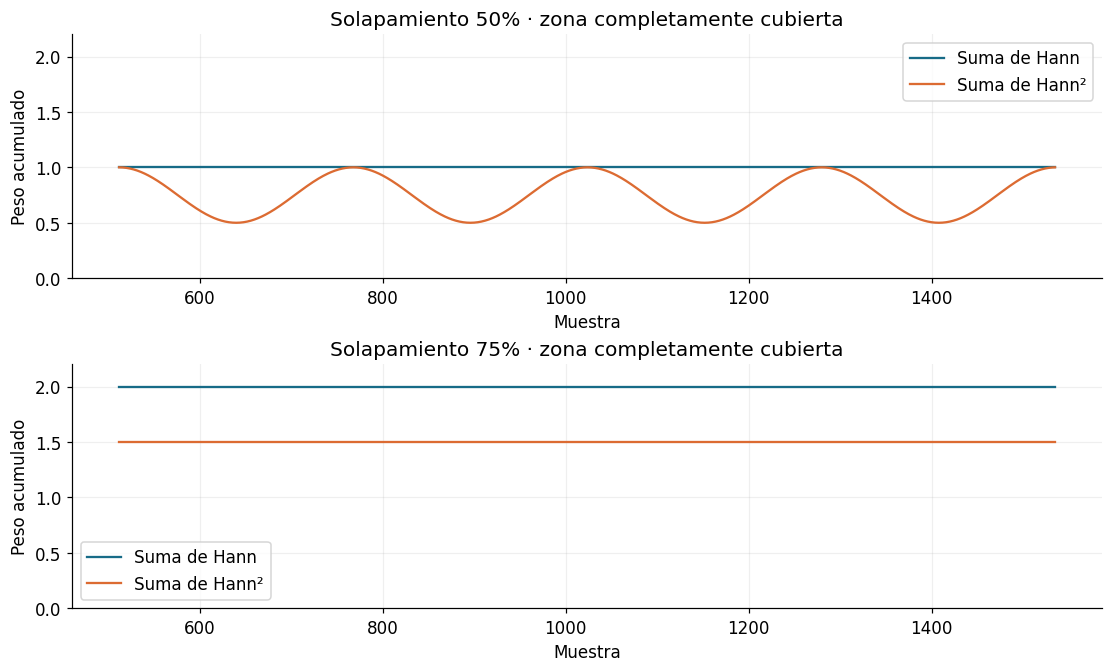

In [32]:
# Suma alineada con un ejemplo pequeño.
mini_ola = np.zeros(6)
mini_ola[0:4] += np.array([1,2,3,4])
mini_ola[2:6] += np.array([10,20,30,40])
print("Overlap-add:", mini_ola)

L_ola = 512
w_ola = np.hanning(L_ola+1)[:-1]
fig, ejes = plt.subplots(2,1,figsize=(10,6),constrained_layout=True)
for ax, H in zip(ejes,[L_ola//2,L_ola//4]):
    sw = np.zeros(4*L_ola)
    sw2 = np.zeros_like(sw)
    for inicio in range(0,len(sw)-L_ola+1,H):
        sw[inicio:inicio+L_ola] += w_ola
        sw2[inicio:inicio+L_ola] += w_ola**2
    zona = slice(L_ola,3*L_ola)
    ax.plot(np.arange(len(sw))[zona],sw[zona],label="Suma de Hann",color=COLOR)
    ax.plot(np.arange(len(sw))[zona],sw2[zona],label="Suma de Hann²",color=ACENTO)
    ax.set(title=f"Solapamiento {100*(1-H/L_ola):.0f}% · zona completamente cubierta",xlabel="Muestra",ylabel="Peso acumulado",ylim=(0,2.2))
    ax.legend()
plt.show()

<a id="tema-27b" name="tema-27b"></a>

## 27B. Normalización de la reconstrucción

Este ejemplo puede ejecutarse con las importaciones del inicio. Usaremos una señal que empieza en un valor distinto de cero para que el problema del borde no quede oculto.

Si aplicáramos Hann al primer bloque sin relleno, la primera muestra recibiría peso 0. Dividir por un número pequeño no recuperaría información perdida. Añadimos relleno antes y después, reconstruimos y retiramos ese relleno. También aseguramos cobertura completa del final.

La suma sin compensar producirá una envolvente artificial. La división por la suma de cuadrados recuperará la señal original, salvo redondeo. Para una STFT modificada, las columnas pueden dejar de ser consistentes entre sí: no toda modificación de un espectrograma corresponde exactamente a una señal.

[**↑ Volver al índice**](#indice)

Error máximo sin compensar: 0.17403732299534774
Error máximo normalizado:  2.220446049250313e-16


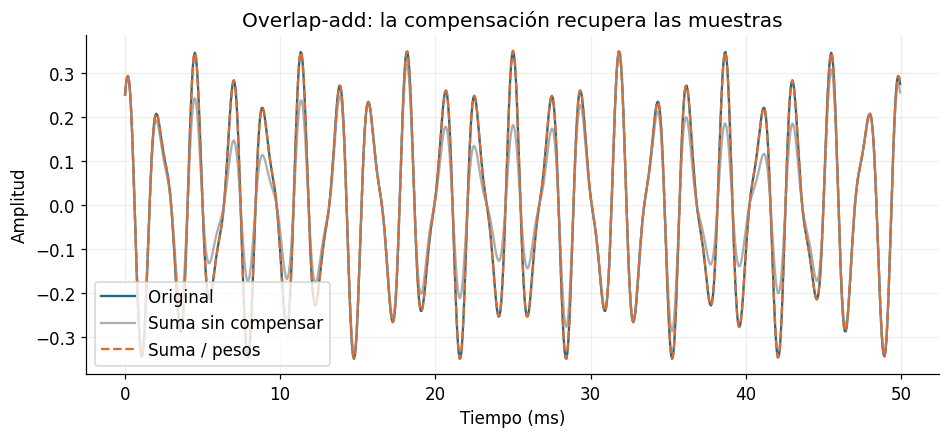

Error máximo con librosa: 1.942890293094024e-16
Original


Reconstrucción normalizada


In [33]:
fs_ola = 16000
x_t_ola = np.arange(16000)/fs_ola
x_ola = 0.25*np.cos(2*np.pi*440*x_t_ola) + 0.1*np.sin(2*np.pi*730*x_t_ola)
L_ola, H_ola = 512, 256
w_ola = np.hanning(L_ola+1)[:-1]
pad_ola = L_ola
xp_ola = np.pad(x_ola,(pad_ola,pad_ola))
extra_ola = (-(len(xp_ola)-L_ola)) % H_ola
xp_ola = np.pad(xp_ola,(0,extra_ola))
suma_ola = np.zeros_like(xp_ola)
pesos_ola = np.zeros_like(xp_ola)
for inicio in range(0,len(xp_ola)-L_ola+1,H_ola):
    bloque = xp_ola[inicio:inicio+L_ola]*w_ola
    espectro = np.fft.rfft(bloque)
    bloque_inverso = np.fft.irfft(espectro,n=L_ola)
    suma_ola[inicio:inicio+L_ola] += bloque_inverso*w_ola
    pesos_ola[inicio:inicio+L_ola] += w_ola**2
rec_ola = np.divide(suma_ola,pesos_ola,out=np.zeros_like(suma_ola),where=pesos_ola>1e-12)
recorte_ola = slice(pad_ola,pad_ola+len(x_ola))
correcta_ola = rec_ola[recorte_ola]
incorrecta_ola = suma_ola[recorte_ola]
assert np.all(pesos_ola[recorte_ola]>0)
assert np.allclose(x_ola,correcta_ola,atol=1e-10)
print("Error máximo sin compensar:", np.max(np.abs(x_ola-incorrecta_ola)))
print("Error máximo normalizado: ", np.max(np.abs(x_ola-correcta_ola)))
fig, ax = plt.subplots(figsize=(10,4))
ver = x_t_ola<0.05
ax.plot(x_t_ola[ver]*1000,x_ola[ver],label="Original",color=COLOR)
ax.plot(x_t_ola[ver]*1000,incorrecta_ola[ver],label="Suma sin compensar",color="0.6",alpha=0.8)
ax.plot(x_t_ola[ver]*1000,correcta_ola[ver],"--",label="Suma / pesos",color=ACENTO)
ax.set(xlabel="Tiempo (ms)",ylabel="Amplitud",title="Overlap-add: la compensación recupera las muestras")
ax.legend()
plt.show()
# La implementación de librosa hace la normalización automáticamente.
D_ola = librosa.stft(x_ola,n_fft=L_ola,win_length=L_ola,hop_length=H_ola,window="hann",center=True)
lib_ola = librosa.istft(D_ola,n_fft=L_ola,win_length=L_ola,hop_length=H_ola,window="hann",center=True,length=len(x_ola))
assert np.allclose(x_ola,lib_ola,atol=1e-10)
print("Error máximo con librosa:",np.max(np.abs(x_ola-lib_ola)))
print("Original")
display(Audio(x_ola,rate=fs_ola,normalize=False))
print("Reconstrucción normalizada")
display(Audio(correcta_ola,rate=fs_ola,normalize=False))

### Tres ideas que no deben mezclarse

- **Solapamiento de análisis:** determina cuántas veces observamos una muestra y cada cuánto calculamos una STFT.
- **Overlap-add de síntesis:** alinea y combina bloques para volver a una señal temporal; requiere pesos y cobertura adecuados.
- **Overlap-add para convolución rápida:** divide una señal en bloques, calcula convoluciones por FFT y suma sus colas. Allí se necesita suficiente relleno para evitar convolución circular: al menos `longitud_bloque + longitud_filtro − 1`. Está relacionado, pero no es el mismo procedimiento que nuestra síntesis STFT.

Para clasificar comandos podemos trabajar directamente con características sin reconstruir audio. Estudiamos la inversa para entender qué hace cada ventana y qué información se conserva o descarta.

<a id="tema-28" name="tema-28"></a>

## 28. Representación del espectrograma

Primero calculamos **potencia sin normalizar**, $P=\lvert D\rvert^2$. Para una visualización relativa:

$$P_{\mathrm{dB}}=10\log_{10}\left(\frac{P}{P_{\mathrm{ref}}}\right),\qquad P_{\mathrm{ref}}=\max P.$$

El máximo es 0 dB y los valores menores son negativos. Limitaremos la visualización a −80 dB. El color no representa fase ni presión sonora calibrada: muestra potencia relativa al máximo de esta matriz.

**Cómo leerlo:** eje horizontal = tiempo; eje vertical = frecuencia; colores claros = mayor potencia relativa. Una banda horizontal indica una frecuencia sostenida; una diagonal, una frecuencia que cambia.

`pcolormesh` convierte la matriz en un mapa de colores. Le pasamos explícitamente los centros de tiempo y los bins en Hz para evitar ejes numéricos ambiguos. Cada celda pintada representa un valor discreto; el ancho visual no es una medición exacta de la resolución.

[**↑ Volver al índice**](#indice)

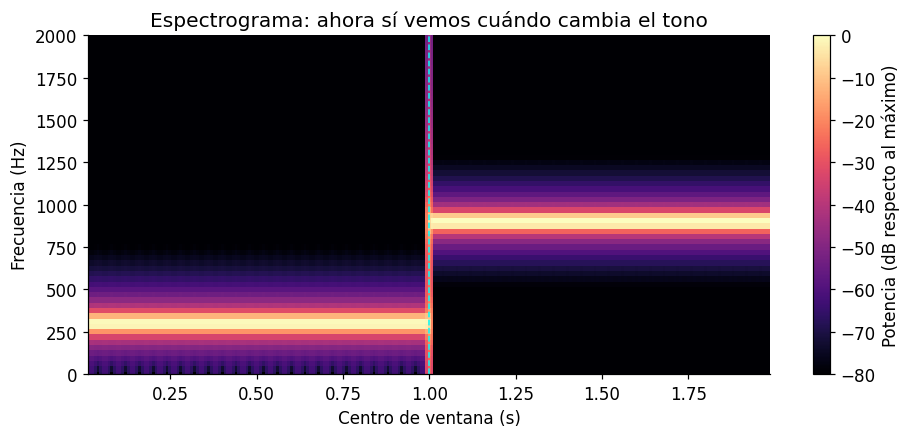

In [34]:
potencia_s = np.abs(D_manual_s)**2
ref_s = potencia_s.max()
db_manual_s = 10*np.log10(np.maximum(potencia_s/ref_s, 1e-8))
fig, ax = plt.subplots(figsize=(10, 4))
ax.grid(False)
im = ax.pcolormesh(centros_s, freq_s, db_manual_s, shading="auto", cmap="magma", vmin=-80, vmax=0)
ax.set(xlabel="Centro de ventana (s)", ylabel="Frecuencia (Hz)", ylim=(0, 2000), title="Espectrograma: ahora sí vemos cuándo cambia el tono")
ax.axvline(1, color="cyan", linestyle="--", linewidth=1)
fig.colorbar(im, ax=ax, label="Potencia (dB respecto al máximo)")
plt.show()

<a id="tema-29" name="tema-29"></a>

## 29. Cálculo de la STFT con librosa

`librosa.stft` automatiza el proceso, pero sus parámetros deben coincidir con nuestro cálculo. Usaremos **`center=False`** y la misma Hann periódica; también fijamos explícitamente FFT, ventana y salto.

El valor predeterminado de `center` es `True`: la librería agrega relleno para centrar ventanas sobre el audio. Si no lo aclaramos, cambiarán el número de columnas y su interpretación temporal.

`librosa.power_to_db` realiza la conversión logarítmica con protecciones numéricas. `ref=np.max` usa el máximo de la matriz como referencia. No es una normalización global para entrenar modelos; esa decisión se explica en el apartado de preprocesamiento.

`librosa.display.specshow` solo dibuja una matriz: **no calcula la STFT**. Indicamos coordenadas temporales explícitas porque analizamos con `center=False` y queremos mostrar centros de ventana.

[**↑ Volver al índice**](#indice)

Forma manual: (257, 247) | librosa: (257, 247)
Error máximo: 1.432144669219779e-14


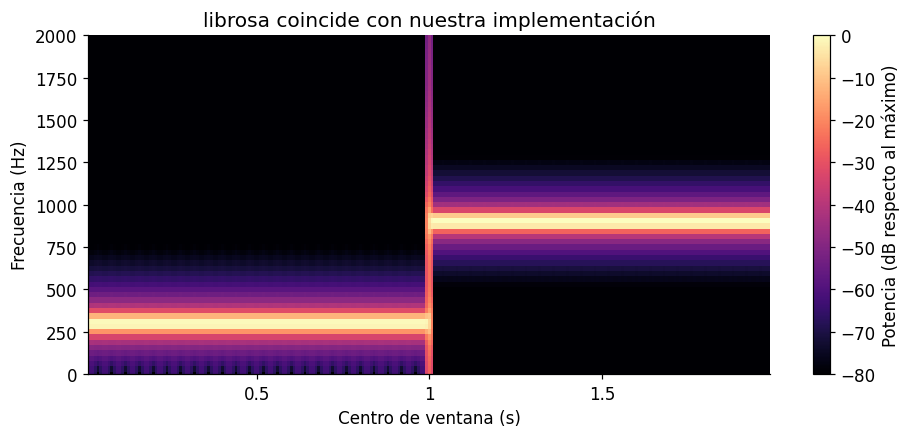

In [35]:
D_lib_s = librosa.stft(senal_s, n_fft=n_fft_s, win_length=win_s, hop_length=hop_s, window="hann", center=False)
print("Forma manual:", D_manual_s.shape, "| librosa:", D_lib_s.shape)
print("Error máximo:", np.max(np.abs(D_manual_s-D_lib_s)))
assert np.allclose(D_manual_s, D_lib_s, atol=1e-10)
P_lib_s = np.abs(D_lib_s)**2
db_lib_s = librosa.power_to_db(P_lib_s, ref=np.max, top_db=80)
assert np.allclose(db_manual_s, db_lib_s, atol=1e-8)
fig, ax = plt.subplots(figsize=(10, 4))
ax.grid(False)
im = librosa.display.specshow(db_lib_s, sr=sr_s, hop_length=hop_s, n_fft=n_fft_s, x_coords=centros_s, y_coords=freq_s, x_axis="time", y_axis="linear", cmap="magma", vmin=-80, vmax=0, ax=ax)
ax.set(ylim=(0, 2000), xlabel="Centro de ventana (s)", ylabel="Frecuencia (Hz)", title="librosa coincide con nuestra implementación")
fig.colorbar(im, ax=ax, label="Potencia (dB respecto al máximo)")
plt.show()

<a id="tema-30" name="tema-30"></a>

## 30. Parámetros de la STFT

| Parámetro | Qué cambia | Qué no debes confundir |
|---|---|---|
| `win_length` | Muestras con peso de ventana; duración efectiva de observación local. | Una ventana larga mezcla acontecimientos separados en el tiempo. |
| `n_fft` | Longitud de FFT y número de bins: $\lfloor n_{\mathrm{fft}}/2\rfloor+1$. | Aumentarlo manteniendo `win_length` agrega ceros a la ventana; densifica bins, no añade observación. |
| `hop_length` | Avance entre análisis; espaciamiento temporal $H/f_s$. | Un salto menor genera más columnas, pero no acorta la ventana. |
| `window` | Forma de ponderar el fragmento. | Modifica fuga, anchura de lóbulos y escala. |
| `center` | Si se agrega relleno para centrar los análisis. | Cambia bordes, tiempos y número de columnas. |

En librosa, si `win_length < n_fft`, la ventana se centra y rellena con ceros hasta `n_fft`. Con `center=False` se extraen marcos de `n_fft` muestras: el número de columnas depende de **`n_fft`**, no solo de `win_length`.

Con `center=True`, `n_fft` par y relleno predeterminado, obtenemos $1+\lfloor N/H\rfloor$ columnas. Sus centros son $mH/f_s$. Los análisis cercanos a los extremos usan parte del relleno, no únicamente muestras observadas.

[**↑ Volver al índice**](#indice)

In [36]:
D_centro_s = librosa.stft(senal_s, n_fft=n_fft_s, win_length=win_s, hop_length=hop_s, center=True, pad_mode="constant")
print("center=False:", D_lib_s.shape, "primer centro:", centros_s[0], "s")
print("center=True: ", D_centro_s.shape, "primer centro: 0.0 s (incluye relleno)")
print("\nMisma señal; diferentes configuraciones:")
for nfft, win, hop in [(512,512,128), (2048,512,128), (512,512,64), (2048,2048,128)]:
    D = librosa.stft(senal_s, n_fft=nfft, win_length=win, hop_length=hop, center=False)
    print(f"FFT={nfft:4d} | ventana={win/sr_s*1000:5.1f} ms | salto={hop/sr_s*1000:4.1f} ms | bins Δf={sr_s/nfft:5.2f} Hz | forma={D.shape}")

center=False: (257, 247) primer centro: 0.016 s
center=True:  (257, 251) primer centro: 0.0 s (incluye relleno)

Misma señal; diferentes configuraciones:
FFT= 512 | ventana= 32.0 ms | salto= 8.0 ms | bins Δf=31.25 Hz | forma=(257, 247)
FFT=2048 | ventana= 32.0 ms | salto= 8.0 ms | bins Δf= 7.81 Hz | forma=(1025, 235)
FFT= 512 | ventana= 32.0 ms | salto= 4.0 ms | bins Δf=31.25 Hz | forma=(257, 493)
FFT=2048 | ventana=128.0 ms | salto= 8.0 ms | bins Δf= 7.81 Hz | forma=(1025, 235)


<a id="tema-31" name="tema-31"></a>

## 31. Resolución temporal y frecuencial

Ahora combinaremos dos tonos cercanos (600 y 680 Hz) con un pulso breve en 1 s. Una ventana corta localiza mejor el pulso, pero las bandas cercanas aparecen anchas. Una ventana larga separa mejor las frecuencias, pero extiende la influencia del pulso sobre más tiempo.

Mantendremos el mismo salto de 64 muestras (4 ms) en las dos vistas. Así aislamos el efecto del tamaño de ventana, sin atribuirlo al salto.

Cada panel se expresa en dB respecto a **su propio máximo**. Comparamos la forma y ubicación de los patrones, no potencia absoluta entre paneles.

[**↑ Volver al índice**](#indice)

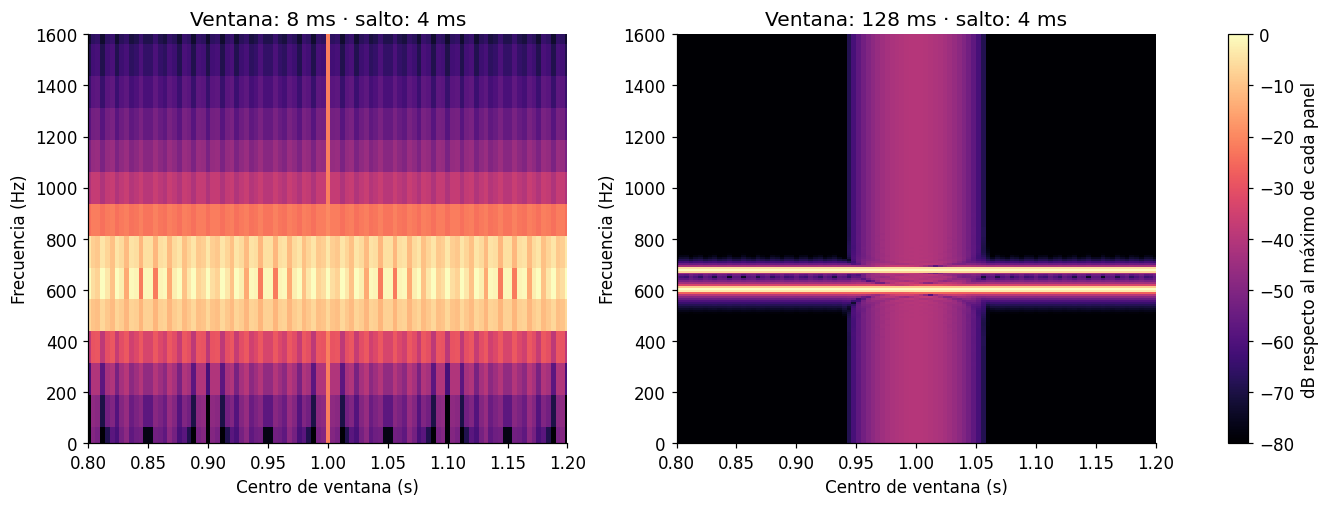

In [37]:
comparacion_s = 0.12*np.sin(2*np.pi*600*t_s) + 0.12*np.sin(2*np.pi*680*t_s)
comparacion_s[sr_s] += 0.6  # Pulso de una muestra.
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, tam in zip(ejes, [128, 2048]):
    D = librosa.stft(comparacion_s, n_fft=tam, win_length=tam, hop_length=64, center=False)
    db = librosa.amplitude_to_db(np.abs(D), ref=np.max, top_db=80)
    tiempos = (np.arange(D.shape[1])*64+tam/2)/sr_s
    frecuencias = np.fft.rfftfreq(tam, d=1/sr_s)
    ax.grid(False)
    im = ax.pcolormesh(tiempos, frecuencias, db, shading="auto", cmap="magma", vmin=-80, vmax=0)
    ax.set(xlim=(0.8, 1.2), ylim=(0, 1600), xlabel="Centro de ventana (s)", ylabel="Frecuencia (Hz)", title=f"Ventana: {tam/sr_s*1000:g} ms · salto: 4 ms")
fig.colorbar(im, ax=ejes, label="dB respecto al máximo de cada panel")
plt.show()

<a id="tema-32" name="tema-32"></a>

## 32. Interpretación de espectrogramas

El barrido aparece como una banda ascendente. Los tonos consecutivos aparecen como dos bandas a alturas distintas en tiempos distintos. El ancho de cada banda depende del análisis: un tono puro no se convierte físicamente en un conjunto de tonos por verse ancho.

La misma matriz puede dibujarse con un eje de frecuencia lineal o logarítmico. **Cambiar el eje a logarítmico no construye un espectrograma Mel**: Mel requiere aplicar un banco de filtros, que se aplica en la sección de Mel.

[**↑ Volver al índice**](#indice)

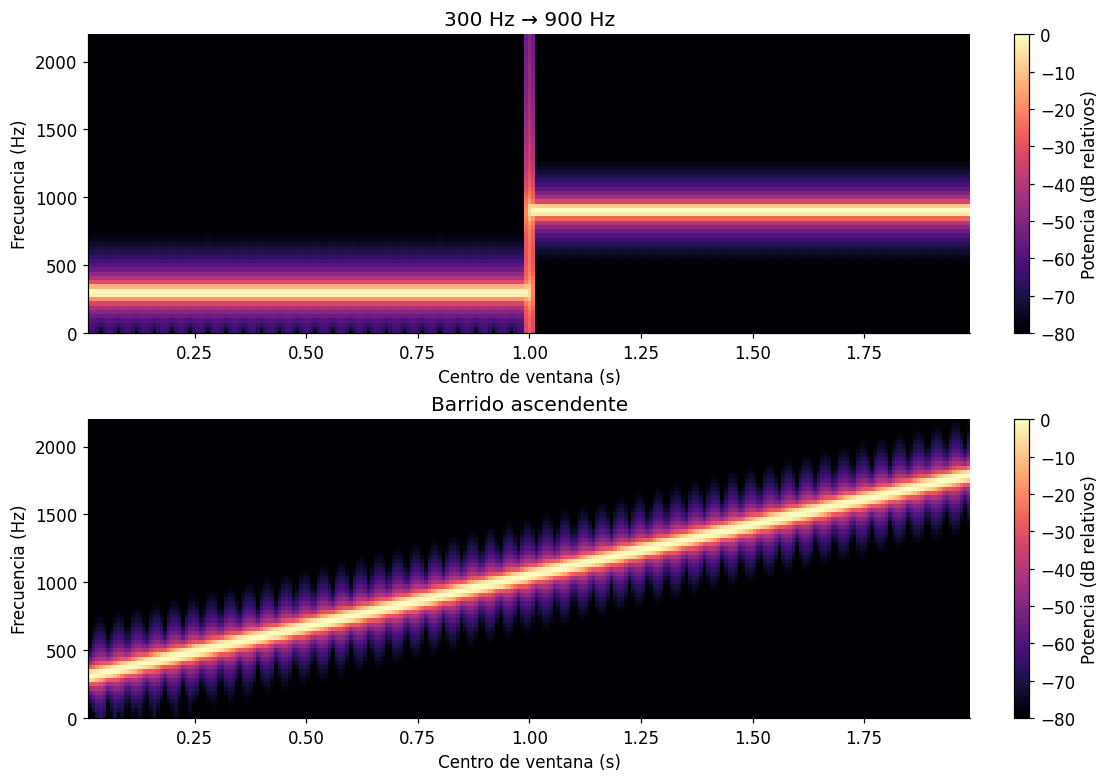

In [38]:
fig, ejes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
for ax, x, titulo in zip(ejes, [senal_s, barrido_s], ["300 Hz → 900 Hz", "Barrido ascendente"]):
    D = librosa.stft(x, n_fft=512, win_length=512, hop_length=128, center=False)
    db = librosa.power_to_db(np.abs(D)**2, ref=np.max, top_db=80)
    tiempos = (np.arange(D.shape[1])*128+256)/sr_s
    frecuencias = np.fft.rfftfreq(512, d=1/sr_s)
    ax.grid(False)
    im = ax.pcolormesh(tiempos, frecuencias, db, shading="auto", cmap="magma", vmin=-80, vmax=0)
    ax.set(xlabel="Centro de ventana (s)", ylabel="Frecuencia (Hz)", ylim=(0, 2200), title=titulo)
    fig.colorbar(im, ax=ax, label="Potencia (dB relativos)")
plt.show()

<a id="tema-33" name="tema-33"></a>

## 33. Ejercicio: parámetros de la STFT

Fija primero `mi_fft=2048`; prueba `mi_ventana=256` y luego 1024 manteniendo el salto. Así la ventana nunca excederá la FFT. Después conserva ventana y FFT y reduce el salto de 128 a 32. Finalmente fija `mi_ventana=512` y compara `mi_fft=512` con `mi_fft=2048`, conservando el salto.

Antes de ejecutar, predice: ¿cambiará la anchura de las bandas, el número de filas o el número de columnas? La tabla de parámetros te ayuda a justificarlo.

[**↑ Volver al índice**](#indice)

Forma frecuencias × ventanas: (257, 247)
Ventana 32 ms | salto 8 ms | bins cada 31.25 Hz


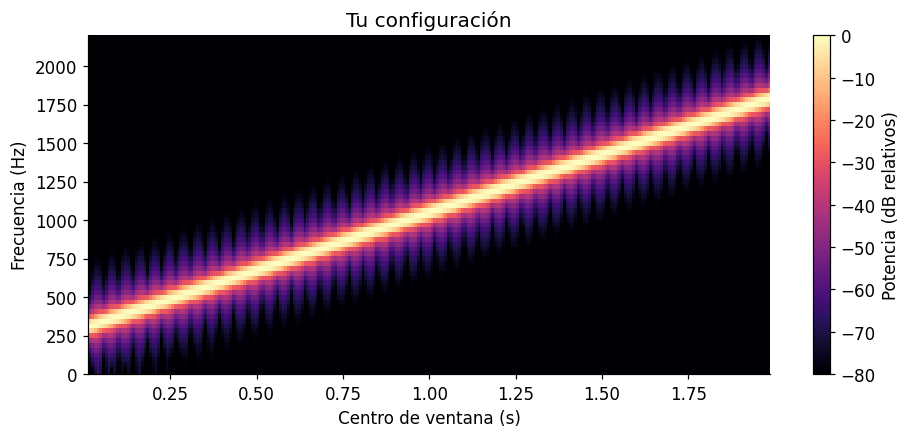

In [39]:
mi_fft = 512
mi_ventana = 512
mi_salto = 128
mi_senal_stft = barrido_s  # También puedes elegir senal_s.
assert 2 <= mi_ventana <= mi_fft <= len(mi_senal_stft)
assert 0 < mi_salto <= mi_ventana
mi_D = librosa.stft(mi_senal_stft, n_fft=mi_fft, win_length=mi_ventana, hop_length=mi_salto, center=False)
mi_db = librosa.power_to_db(np.abs(mi_D)**2, ref=np.max, top_db=80)
mi_tiempos = (np.arange(mi_D.shape[1])*mi_salto+mi_fft/2)/sr_s
mi_freqs = np.fft.rfftfreq(mi_fft, d=1/sr_s)
print("Forma frecuencias × ventanas:", mi_D.shape)
print(f"Ventana {mi_ventana/sr_s*1000:g} ms | salto {mi_salto/sr_s*1000:g} ms | bins cada {sr_s/mi_fft:g} Hz")
fig, ax = plt.subplots(figsize=(10, 4))
ax.grid(False)
im = ax.pcolormesh(mi_tiempos, mi_freqs, mi_db, shading="auto", cmap="magma", vmin=-80, vmax=0)
ax.set(xlabel="Centro de ventana (s)", ylabel="Frecuencia (Hz)", ylim=(0, 2200), title="Tu configuración")
fig.colorbar(im, ax=ax, label="Potencia (dB relativos)")
plt.show()

<a id="tema-34" name="tema-34"></a>

## 34. Ejercicios de comprensión

1. ¿En qué se diferencia una STFT compleja de un espectrograma de potencia?
2. Para `n_fft=512`, `win_length=512`, `hop_length=128` y 16 000 muestras/s, calcula duración de ventana, salto y número de filas.
3. Con 32 000 muestras, esa configuración y `center=False`, ¿cuántas columnas hay?
4. ¿Por qué reducir el salto no equivale a mejorar la resolución temporal de la ventana?
5. Si aumentas `n_fft` de 512 a 2048 manteniendo `win_length=512`, ¿obtienes cuatro veces más tiempo observado por ventana?
6. ¿Por qué `center=True` afecta los bordes?
7. ¿Qué significan 0 dB y −20 dB en nuestros mapas con referencia al máximo?
8. ¿Un eje vertical logarítmico convierte el espectrograma en Mel?

### Respuestas comentadas

1. La STFT conserva coeficientes complejos y fase. El espectrograma de potencia usa $\lvert D\rvert^2$; la fase ya no aparece en esa matriz.
2. Ventana de 32 ms, salto de 8 ms y 257 filas.
3. $1+\lfloor(32000-512)/128\rfloor=247$ columnas.
4. Hay más análisis superpuestos, pero cada uno sigue mezclando el mismo intervalo de observación.
5. No: se densifica la rejilla. La ventana con peso sigue teniendo 512 muestras (32 ms). En librosa también cambia el enmarcado y por eso puede cambiar el número de columnas.
6. Agrega relleno: las ventanas extremas incluyen valores que no provienen de la grabación.
7. 0 dB corresponde al máximo de esa matriz; −20 dB equivale a una centésima de su potencia. No expresa presión sonora calibrada.
8. No. Mel requiere combinar bins mediante filtros.

[**↑ Volver al índice**](#indice)

<a id="tema-35" name="tema-35"></a>

## 35. Representaciones de audio y referencias

El espectrograma organiza la señal en una matriz de frecuencias y tiempo. Estas representaciones se utilizan en los apartados de características y preparación de datos.

| Representación o etapa | Contenido del cuaderno |
|---|---|
| Mel | Agrupación de frecuencias mediante un banco de filtros. |
| log-Mel | Transformación logarítmica de las potencias Mel. |
| MFCC | Transformada coseno sobre log-Mel y selección de coeficientes. |
| Preparación de datos | Speech Commands, preprocesamiento, `Dataset` y `DataLoader`. |

### Documentación de esta parte

- [librosa 0.11: STFT y parámetros](https://librosa.org/doc/0.11.0/generated/librosa.stft.html).
- [librosa: conversión de potencia a decibelios](https://librosa.org/doc/0.11.0/generated/librosa.power_to_db.html).
- [librosa: visualización con specshow](https://librosa.org/doc/0.11.0/generated/librosa.display.specshow.html).

Esta parte se verificó con librosa 0.11.0. Todos los audios y gráficos se generan en el cuaderno, sin archivos externos.

[**↑ Volver al índice**](#indice)

<a id="tema-36" name="tema-36"></a>

# Parte 4 · Mel, log-Mel y MFCC
## 36. Características del audio

**Ruta:** audio → STFT compleja → potencia → filtros Mel → log-Mel → transformada coseno → MFCC.

No todas las tareas necesitan llegar hasta MFCC. En este cuaderno calculamos las tres representaciones y utilizamos **log-Mel** para la preparación de datos. La comparación de arquitecturas se aborda de forma conceptual.

| Representación | Eje vertical | Qué cambia respecto a la anterior |
|---|---|---|
| Potencia STFT | Bins de frecuencia, Hz | Se descarta fase al calcular magnitud al cuadrado. |
| Mel | Bandas de filtros | Se combinan bins; se pierde detalle fino. |
| log-Mel | Las mismas bandas Mel | Se comprime el rango numérico con logaritmos. |
| MFCC | Índices de coeficientes | Se cambia de base a cosenos sobre las bandas; al truncar se descarta información. |

Para estudiar todo sin descargas construiremos dos sonidos **similares a vocales**, con la misma frecuencia fundamental y diferentes envolventes espectrales. Son un modelo didáctico: no corresponden a grabaciones de personas ni sustituyen Speech Commands.

**Analogía fuente–filtro:** una cuerda o las cuerdas vocales aportan una excitación; una caja resonante o el tracto vocal refuerza ciertas regiones. Dos sonidos pueden compartir nota y diferir en timbre. Esas regiones reforzadas en voz se relacionan con **formantes**, no con la frecuencia fundamental.

[**↑ Volver al índice**](#indice)

Dos timbres sintéticos con la misma fundamental de 120 Hz


STFT: (513, 126) | potencia: (513, 126)


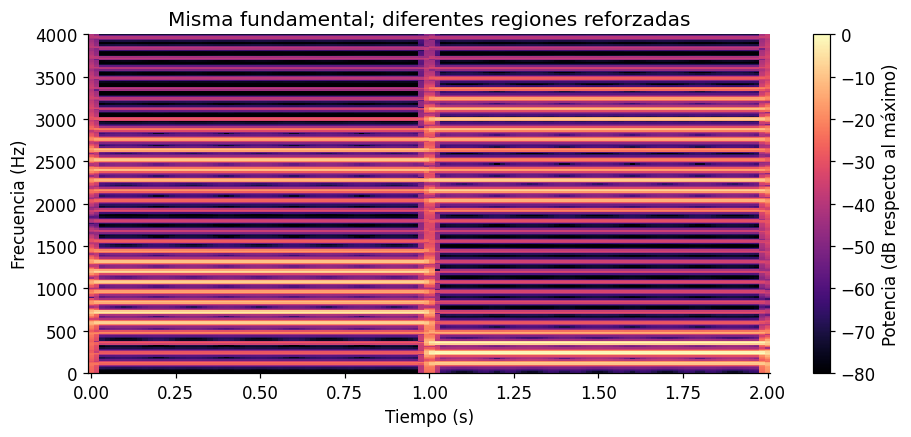

In [40]:
# Inicio independiente de la parte 4: solo requiere las importaciones de arriba.
sr_m = 16000
N_m = 32000
t_m = np.arange(N_m)/sr_m
f0_m = 120.0
armonicos_m = np.arange(1, int(7000/f0_m)+1)*f0_m
# Centros y anchuras de resonancias: parámetros didácticos, no plantilla de hablante.
formantes_m = [(700,1200,2500),(300,2200,3000)]
anchuras_m = [100,150,220]
vocales_m=[]
for formantes in formantes_m:
    pesos=np.zeros_like(armonicos_m)
    for centro, ancho in zip(formantes,anchuras_m):
        pesos += np.exp(-0.5*((armonicos_m-centro)/ancho)**2)
    pesos=(0.04+pesos)/np.sqrt(np.arange(1,len(armonicos_m)+1))
    tono=np.sum(pesos[:,None]*np.sin(2*np.pi*armonicos_m[:,None]*t_m[None,:]),axis=0)
    vocales_m.append(0.35*tono/np.max(np.abs(tono)))
y_m=np.concatenate([vocales_m[0][:16000],vocales_m[1][16000:]])
# Transición abrupta deliberada; puede producir energía transitoria cerca de 1 s.
print("Dos timbres sintéticos con la misma fundamental de 120 Hz")
display(Audio(y_m,rate=sr_m,normalize=False))
nfft_m, win_m, hop_m = 1024, 1024, 256
D_m=librosa.stft(y_m,n_fft=nfft_m,win_length=win_m,hop_length=hop_m,window="hann",center=True)
P_m=np.abs(D_m)**2
freq_m=np.fft.rfftfreq(nfft_m,d=1/sr_m)
tiempos_m=np.arange(D_m.shape[1])*hop_m/sr_m
print("STFT:",D_m.shape,"| potencia:",P_m.shape)
fig, ax=plt.subplots(figsize=(10,4))
ax.grid(False)
im=ax.pcolormesh(tiempos_m,freq_m,librosa.power_to_db(P_m,ref=np.max,top_db=80),shading="auto",cmap="magma",vmin=-80,vmax=0)
ax.set(ylim=(0,4000),xlabel="Tiempo (s)",ylabel="Frecuencia (Hz)",title="Misma fundamental; diferentes regiones reforzadas")
fig.colorbar(im,ax=ax,label="Potencia (dB respecto al máximo)")
plt.show()

<a id="tema-37" name="tema-37"></a>

## 37. Escala Mel

La percepción de altura no responde linealmente a incrementos en Hz. Mel propone un eje inspirado en juicios perceptuales; **no es una copia exacta del oído ni de todas las personas**.

Una fórmula común, usada por la convención HTK, es

$$m(f)=2595\log_{10}(1+f/700),\qquad f(m)=700(10^{m/2595}-1).$$

En cambio, **librosa usa por defecto la convención Slaney** (`htk=False`): lineal por debajo de 1 kHz y logarítmica por encima. Fijaremos Slaney explícitamente para que fórmula, gráficos y funciones no se confundan. La fórmula HTK anterior sirve para conocer otra convención, no para describir nuestros valores Slaney.

**Ejemplo general:** un cambio de 100 Hz no tiene el mismo significado perceptual a 100 Hz que a 5 000 Hz. Del mismo modo, sumar 100 pesos tiene distinto efecto relativo sobre 200 que sobre 20 000. La analogía explica la compresión relativa; no demuestra una ley exacta de audición.

En el banco Mel, los centros se espacian uniformemente sobre ese eje: sus separaciones en Hz crecen en la región alta.

Fuentes: [librosa: frecuencias Mel y convenciones](https://librosa.org/doc/0.11.0/generated/librosa.mel_frequencies.html); S. S. Stevens, J. Volkmann y E. B. Newman (1937), *A scale for the measurement of the psychological magnitude pitch*, [DOI](https://doi.org/10.1121/1.1915893).

[**↑ Volver al índice**](#indice)

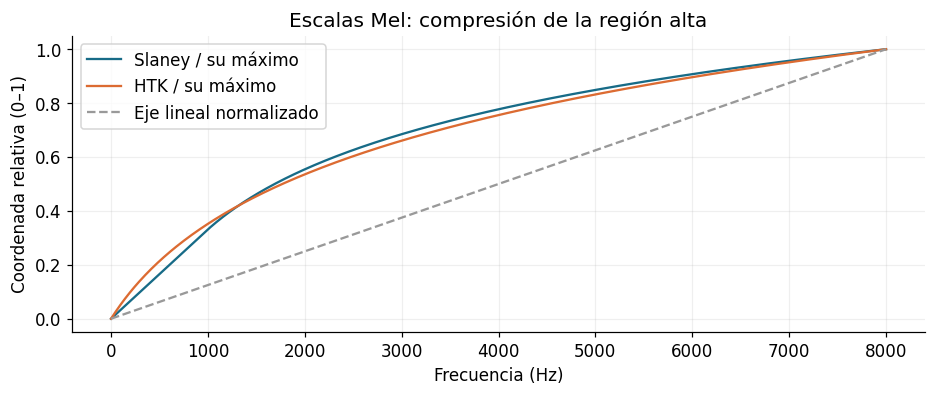

In [41]:
f_escala=np.linspace(0,8000,500)
mel_slaney=librosa.hz_to_mel(f_escala,htk=False)
mel_htk=2595*np.log10(1+f_escala/700)
# Normalizamos solo para comparar la curvatura: NO altera el banco de filtros posterior.
fig,ax=plt.subplots()
ax.plot(f_escala,mel_slaney/mel_slaney[-1],label="Slaney / su máximo",color=COLOR)
ax.plot(f_escala,mel_htk/mel_htk[-1],label="HTK / su máximo",color=ACENTO)
ax.plot(f_escala,f_escala/8000,"--",color="0.6",label="Eje lineal normalizado")
ax.set(xlabel="Frecuencia (Hz)",ylabel="Coordenada relativa (0–1)",title="Escalas Mel: compresión de la región alta")
ax.legend()
plt.show()

<a id="tema-38" name="tema-38"></a>

## 38. Banco de filtros Mel

Un filtro triangular toma bins vecinos, asigna mayor peso cerca de su centro y menor peso hacia sus extremos. No es un simple cambio de etiquetas del eje.

**Analogía:** agrupar edades individuales en intervalos pierde detalle, pero simplifica comparar poblaciones. Aquí los grupos se superponen y cada bin contribuye con pesos, así que no son cajas disjuntas.

Usaremos $B=40$ bandas, de 0 a 8 kHz. `librosa.filters.mel` devuelve una matriz $W$ de forma `(40, 513)`. Cada fila contiene los pesos de un filtro sobre los 513 bins de la FFT de 1024 puntos.

Con `norm='slaney'`, los filtros se normalizan aproximadamente por área: las bandas anchas no acumulan más solo por cubrir más Hz. Por eso sus picos no tienen que valer 1. `htk=False` fija los centros Slaney; **`norm='slaney'` controla otra cosa: los pesos**.

Fuente: [librosa: filtros Mel](https://librosa.org/doc/0.11.0/generated/librosa.filters.mel.html).

[**↑ Volver al índice**](#indice)

Pesos del banco: (40, 513)


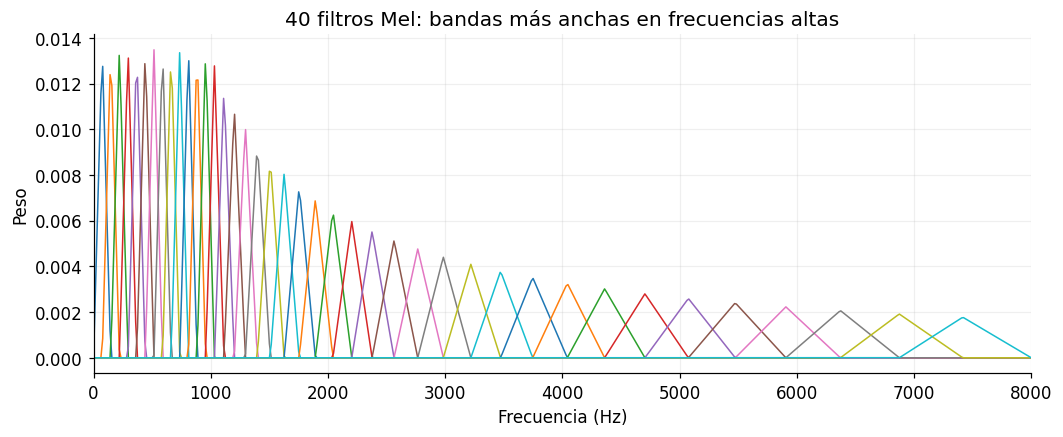

Primeros centros (Hz): [ 73.6 147.1 220.7 294.3 367.9 441.4]
Últimos centros (Hz): [5074.4 5474.4 5905.9 6371.5 6873.7 7415.5]


In [42]:
n_mels_m=40
W_m=librosa.filters.mel(sr=sr_m,n_fft=nfft_m,n_mels=n_mels_m,fmin=0,fmax=sr_m/2,htk=False,norm="slaney",dtype=np.float64)
centros_m=librosa.mel_frequencies(n_mels=n_mels_m+2,fmin=0,fmax=sr_m/2,htk=False)[1:-1]
print("Pesos del banco:",W_m.shape)
fig,ax=plt.subplots(figsize=(11,4))
for b in range(n_mels_m): ax.plot(freq_m,W_m[b],linewidth=1)
ax.set(xlabel="Frecuencia (Hz)",ylabel="Peso",title="40 filtros Mel: bandas más anchas en frecuencias altas",xlim=(0,8000))
plt.show()
print("Primeros centros (Hz):",np.round(centros_m[:6],1))
print("Últimos centros (Hz):",np.round(centros_m[-6:],1))

<a id="tema-39" name="tema-39"></a>

## 39. Cálculo del espectrograma Mel

$$M[b,m]=\sum_k W[b,k]P[k,m],\qquad M=WP.$$

`@` es multiplicación matricial: `(40,513) @ (513,T)` produce `(40,T)`. **Se agregan frecuencias, no tiempos**: el número de columnas se conserva.

Ejemplo de un solo filtro: si sus pesos fueran `[0.2, 0.6, 0.2]` y tres potencias `[1, 4, 2]`, el resultado sería $0.2+2.4+0.4=3$. Un espectrograma Mel hace esa suma para cada filtro y cada ventana.

Como entregaremos `S=P_m` a `melspectrogram`, `S` ya es potencia: la función aplica el banco. Si entregáramos `y=audio`, calcularía STFT y potencia internamente. **No debemos elevar al cuadrado dos veces.**

[**↑ Volver al índice**](#indice)

Mel manual: (40, 126) | librosa: (40, 126)
Error máximo: 0.0
Banda 9, ventana 31: suma=4.290696, matriz=4.290696


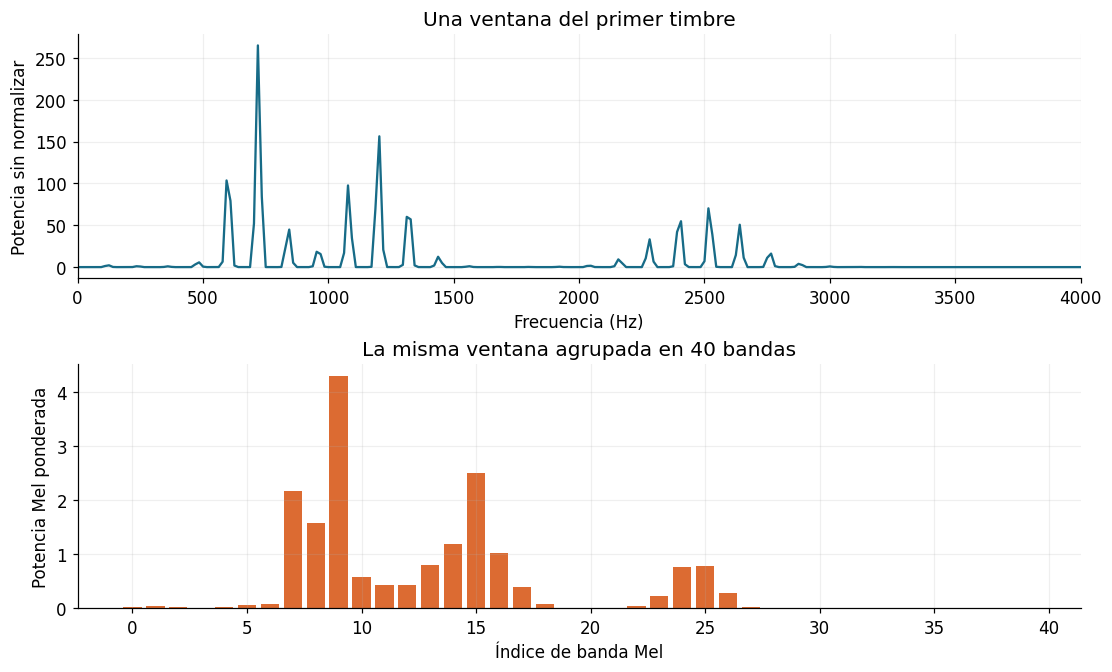

In [43]:
M_m=W_m@P_m
M_lib_m=librosa.feature.melspectrogram(S=P_m,sr=sr_m,n_fft=nfft_m,n_mels=n_mels_m,fmin=0,fmax=sr_m/2,htk=False,norm="slaney",dtype=np.float64)
print("Mel manual:",M_m.shape,"| librosa:",M_lib_m.shape)
print("Error máximo:",np.max(np.abs(M_m-M_lib_m)))
assert np.allclose(M_m,M_lib_m,atol=1e-10)
col_m=int(round(0.5*sr_m/hop_m))
banda_m=9
contribuciones_m=W_m[banda_m]*P_m[:,col_m]
print(f"Banda {banda_m}, ventana {col_m}: suma={contribuciones_m.sum():.6f}, matriz={M_m[banda_m,col_m]:.6f}")
fig,ejes=plt.subplots(2,1,figsize=(10,6),constrained_layout=True)
ejes[0].plot(freq_m,P_m[:,col_m],color=COLOR)
ejes[0].set(xlabel="Frecuencia (Hz)",ylabel="Potencia sin normalizar",title="Una ventana del primer timbre",xlim=(0,4000))
ejes[1].bar(np.arange(n_mels_m),M_m[:,col_m],color=ACENTO)
ejes[1].set(xlabel="Índice de banda Mel",ylabel="Potencia Mel ponderada",title="La misma ventana agrupada en 40 bandas")
plt.show()

<a id="tema-40" name="tema-40"></a>

## 40. Espectrograma log-Mel

Las potencias pueden diferir por muchos órdenes de magnitud. Un logaritmo permite ver y modelar diferencias relativas: multiplicaciones se convierten en sumas.

$$L[b,m]=10\log_{10}\left(\frac{\max(M[b,m],\epsilon)}{P_{\mathrm{ref}}}\right).$$

Aquí fijaremos **`ref=1.0`, `amin=1e-10`, `top_db=None`**. Son dB respecto a la unidad numérica de esta representación, no dB SPL calibrados. `top_db=None` evita recortar automáticamente a 80 dB del máximo; `amin` impone un piso para evitar logaritmo de cero.

**Ejemplo:** potencias `[1,10,100,1000]` producen `[0,10,20,30]` dB. Cada paso representa multiplicar potencia por 10, no añadir la misma cantidad.

También se usa logaritmo natural o base 10 sin el factor 10. Todos pueden llamarse log-Mel; por eso documentamos nuestra convención.

Usar `ref=np.max` por grabación quitaría una escala global: útil para visualizar, pero diferente para características. No cambiaremos esa decisión silenciosamente. La normalización estadística del entrenamiento se calculará solo con sus datos.

Fuente: [librosa: power_to_db](https://librosa.org/doc/0.11.0/generated/librosa.power_to_db.html).

[**↑ Volver al índice**](#indice)

Potencias [1,10,100,1000] en dB: [ 0. 10. 20. 30.]


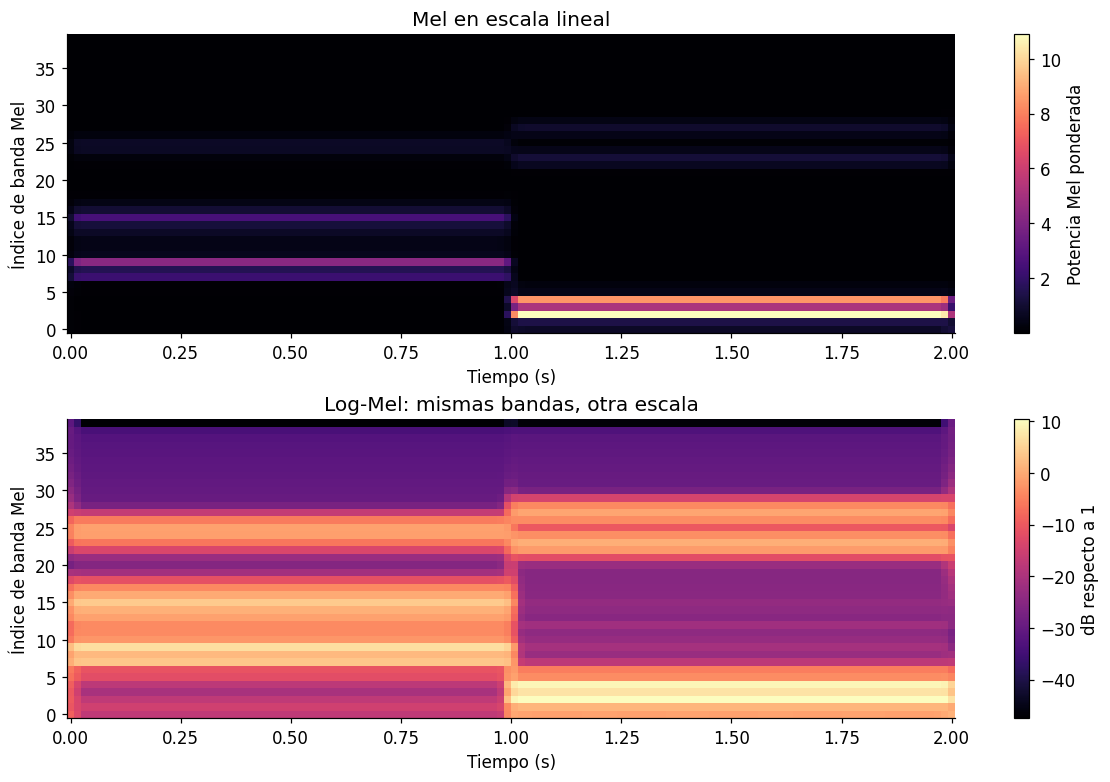

In [44]:
logM_m=librosa.power_to_db(M_m,ref=1.0,amin=1e-10,top_db=None)
logM_manual_m=10*np.log10(np.maximum(M_m,1e-10))
assert np.allclose(logM_m,logM_manual_m)
print("Potencias [1,10,100,1000] en dB:",10*np.log10([1,10,100,1000]))
fig,ejes=plt.subplots(2,1,figsize=(10,7),constrained_layout=True)
for ax,datos,titulo,etiqueta in zip(ejes,[M_m,logM_m],["Mel en escala lineal","Log-Mel: mismas bandas, otra escala"],["Potencia Mel ponderada","dB respecto a 1"]):
    ax.grid(False)
    im=ax.pcolormesh(tiempos_m,np.arange(n_mels_m),datos,shading="auto",cmap="magma")
    ax.set(xlabel="Tiempo (s)",ylabel="Índice de banda Mel",title=titulo)
    fig.colorbar(im,ax=ax,label=etiqueta)
plt.show()

<a id="tema-41" name="tema-41"></a>

## 41. Coeficientes MFCC

**MFCC** significa *Mel-Frequency Cepstral Coefficients*: coeficientes cepstrales en frecuencia Mel. Aplicamos una **transformada discreta del coseno (DCT)** sobre las bandas de cada columna log-Mel.

$$C[q,m]=\alpha_q\sum_{b=0}^{B-1}L[b,m]\cos\left[\frac{\pi}{B}\left(b+\frac12\right)q\right]$$

Para DCT-II ortonormal, $\alpha_0=1/\sqrt{B}$ y $\alpha_q=\sqrt{2/B}$ si $q>0$.

- $b$: índice de banda Mel; $m$: ventana temporal.
- $q$: índice de coeficiente. **No es frecuencia en Hz ni índice de banda Mel.**
- $q=0$: proporcional al promedio del log-Mel; no es necesariamente el logaritmo de la energía total.
- Órdenes bajos: patrones suaves a través de bandas.
- Órdenes altos: variaciones rápidas entre bandas; no equivalen directamente a sonidos de frecuencia alta.

**Analogía:** describir el perfil de una montaña mediante una forma general y luego detalles pequeños. Conservar pocos términos describe el contorno, pero pierde detalles. De manera similar, JPEG utiliza DCT para describir bloques de imagen; aquí la aplicamos al eje de bandas, no a imágenes ni al eje temporal.

La DCT puede reducir correlaciones entre características, pero **no garantiza independencia estadística**. Si conservamos los $B$ coeficientes y no hubo recorte previo, el cambio de base es invertible; al retener solo 13 de 40, la compresión sí pierde información.

Fuente: [librosa: MFCC](https://librosa.org/doc/0.11.0/generated/librosa.feature.mfcc.html), [SciPy: DCT](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.dct.html). Referencia clásica: Davis y Mermelstein (1980), [DOI](https://doi.org/10.1109/TASSP.1980.1163420).

[**↑ Volver al índice**](#indice)

Todos los coeficientes: (40, 126) | MFCC conservados: (13, 126)


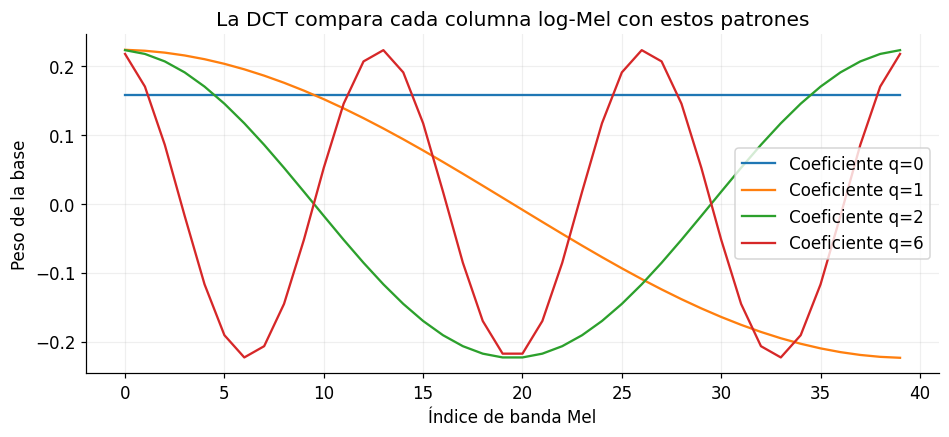

In [45]:
# Construir la base DCT explícitamente para entender qué hace la librería.
B_m=n_mels_m
q_m=np.arange(B_m)[:,None]
b_m=np.arange(B_m)[None,:]
base_m=np.cos(np.pi/B_m*(b_m+0.5)*q_m)*np.sqrt(2/B_m)
base_m[0]/=np.sqrt(2)
C_manual_m=base_m@logM_m
C_scipy_m=dct(logM_m,type=2,axis=0,norm="ortho")
n_mfcc_m=13
C_lib_m=librosa.feature.mfcc(S=logM_m,n_mfcc=n_mfcc_m,dct_type=2,norm="ortho",lifter=0)
assert np.allclose(C_manual_m,C_scipy_m,atol=1e-10)
assert np.allclose(C_lib_m,C_manual_m[:n_mfcc_m],atol=1e-10)
print("Todos los coeficientes:",C_manual_m.shape,"| MFCC conservados:",C_lib_m.shape)
fig,ax=plt.subplots(figsize=(10,4))
for q in [0,1,2,6]: ax.plot(np.arange(B_m),base_m[q],label=f"Coeficiente q={q}")
ax.set(xlabel="Índice de banda Mel",ylabel="Peso de la base",title="La DCT compara cada columna log-Mel con estos patrones")
ax.legend()
plt.show()

<a id="tema-42" name="tema-42"></a>

## 42. Reducción del número de coeficientes

Podemos volver de todos los coeficientes al log-Mel mediante `idct`. Si ponemos a cero los coeficientes omitidos, recuperamos una aproximación más suave. **Esto reconstruye log-Mel, no el audio original**: el banco Mel ya agrupó frecuencias y la potencia ya descartó fase.

Aunque recuperáramos exactamente el log-Mel, todavía faltarían esas informaciones para reconstruir las muestras. No atribuyamos toda la pérdida a la DCT.

[**↑ Volver al índice**](#indice)

Error máximo con 40 coeficientes: 1.7763568394002505e-14
Error cuadrático medio con 13 coeficientes: 6.377274409471002


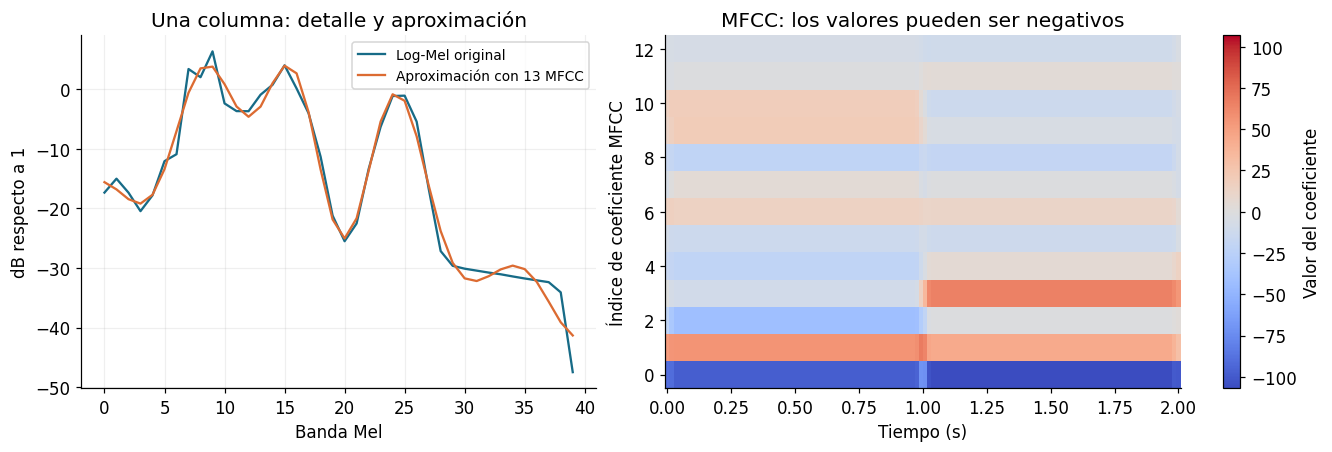

In [46]:
logM_total_m=idct(C_scipy_m,type=2,axis=0,norm="ortho")
assert np.allclose(logM_total_m,logM_m,atol=1e-10)
C_trunc_m=np.zeros_like(C_scipy_m)
C_trunc_m[:n_mfcc_m]=C_scipy_m[:n_mfcc_m]
logM_aprox_m=idct(C_trunc_m,type=2,axis=0,norm="ortho")
print("Error máximo con 40 coeficientes:",np.max(np.abs(logM_total_m-logM_m)))
print("Error cuadrático medio con 13 coeficientes:",np.mean((logM_aprox_m-logM_m)**2))
fig,ejes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
ejes[0].plot(np.arange(B_m),logM_m[:,col_m],label="Log-Mel original",color=COLOR)
ejes[0].plot(np.arange(B_m),logM_aprox_m[:,col_m],label="Aproximación con 13 MFCC",color=ACENTO)
ejes[0].set(xlabel="Banda Mel",ylabel="dB respecto a 1",title="Una columna: detalle y aproximación")
ejes[0].legend(fontsize=9)
ejes[1].grid(False)
lim_m=np.max(np.abs(C_lib_m))
im=ejes[1].pcolormesh(tiempos_m,np.arange(n_mfcc_m),C_lib_m,shading="auto",cmap="coolwarm",vmin=-lim_m,vmax=lim_m)
ejes[1].set(xlabel="Tiempo (s)",ylabel="Índice de coeficiente MFCC",title="MFCC: los valores pueden ser negativos")
fig.colorbar(im,ax=ejes[1],label="Valor del coeficiente")
plt.show()

<a id="tema-43" name="tema-43"></a>

## 43. Efecto de la amplitud sobre las características

Si multiplicamos el audio por $g>0$, su potencia se multiplica por $g^2$. Sin pisos ni recortes activos:

$$\Delta L=20\log_{10}(g).$$

Para $g=0.5$, el log-Mel baja aproximadamente 6.02 dB en todas las bandas. Un desplazamiento constante entre bandas se concentra en $q=0$ de la DCT. Los otros coeficientes cambian solo por redondeo **si se cumplen las condiciones**. Los pisos numéricos, silencios y otras normalizaciones rompen esa igualdad exacta.

Esto ayuda a interpretar el primer MFCC; no significa que quitarlo haga al sistema inmune a toda variación de micrófono, ruido o distancia.

[**↑ Volver al índice**](#indice)

In [47]:
g_m=0.5
logM_mitad=librosa.power_to_db(M_m*g_m**2,ref=1.0,amin=1e-10,top_db=None)
C_mitad=dct(logM_mitad,type=2,axis=0,norm="ortho")
validas_m=np.all(M_m*g_m**2>1e-10,axis=0)
print("Columnas sin piso activo:",np.count_nonzero(validas_m))
if np.any(validas_m):
    cambio_m=C_mitad[:,validas_m]-C_scipy_m[:,validas_m]
    print("Cambio esperado de log-Mel:",20*np.log10(g_m),"dB")
    print("Cambio esperado en q=0:",np.sqrt(B_m)*20*np.log10(g_m))
    print("Cambio medio observado en q=0:",cambio_m[0].mean())
    print("Máximo cambio en q>0:",np.max(np.abs(cambio_m[1:])))

Columnas sin piso activo: 126
Cambio esperado de log-Mel: -6.020599913279624 dB
Cambio esperado en q=0: -38.077617213151676
Cambio medio observado en q=0: -38.07761721315168
Máximo cambio en q>0: 2.1316282072803006e-14


<a id="tema-44" name="tema-44"></a>

## 44. Función de extracción de características

Concentramos el procesamiento en una función para evitar diferencias accidentales entre experimentos. Aquí `center=True`, Hann periódica, Slaney, referencia fija y 13 MFCC quedan explícitos.

`n_mels` controla la resolución del banco; `n_mfcc` controla cuántos patrones DCT conservamos. No significan número de palabras, hablantes ni clases. Si pedimos demasiados filtros para pocos bins, algunos pueden quedar mal representados: más características no siempre significa más información útil.

La aplicación final convierte estas matrices a tensores, las normaliza con estadísticas de entrenamiento y las agrupa por lotes.

[**↑ Volver al índice**](#indice)

In [48]:
def caracteristicas_audio(y,sr,n_fft=1024,hop_length=256,n_mels=40,n_mfcc=13):
    y=np.asarray(y,dtype=np.float64)
    assert y.ndim==1 and len(y)>0 and sr>0 and np.all(np.isfinite(y))
    assert 1<=n_mfcc<=n_mels and 0<hop_length<=n_fft
    D=librosa.stft(y,n_fft=n_fft,win_length=n_fft,hop_length=hop_length,window="hann",center=True,pad_mode="constant")
    P=np.abs(D)**2
    W=librosa.filters.mel(sr=sr,n_fft=n_fft,n_mels=n_mels,fmin=0,fmax=sr/2,htk=False,norm="slaney",dtype=np.float64)
    mel=W@P
    logmel=librosa.power_to_db(mel,ref=1.0,amin=1e-10,top_db=None)
    mfcc=librosa.feature.mfcc(S=logmel,n_mfcc=n_mfcc,dct_type=2,norm="ortho",lifter=0)
    return {"potencia":P,"mel":mel,"logmel":logmel,"mfcc":mfcc}

car_m=caracteristicas_audio(y_m,sr_m)
for nombre,matriz in car_m.items(): print(f"{nombre:8s}: {matriz.shape}, {matriz.dtype}")
assert np.allclose(car_m["mfcc"],C_lib_m)
# Silencio: el piso logarítmico debe evitar NaN e infinitos.
sil_m=caracteristicas_audio(np.zeros(sr_m),sr_m)
assert all(np.isfinite(v).all() for v in sil_m.values())
print("Silencio procesado sin valores no finitos.")

potencia: (513, 126), float64
mel     : (40, 126), float64
logmel  : (40, 126), float64
mfcc    : (13, 126), float64
Silencio procesado sin valores no finitos.


<a id="tema-45" name="tema-45"></a>

## 45. Ejercicios y ejemplos de aplicación

Prueba `n_mels=24, n_mfcc=8` y luego `n_mels=64, n_mfcc=20`. Compara forma, tamaño y detalle. Cambia un parámetro a la vez si quieres atribuirle un efecto.

| Situación cotidiana o técnica | Conexión | Límite de la analogía |
|---|---|---|
| Rueda que parece girar al revés en video | Aliasing por observaciones temporales insuficientes. | La cámara también tiene obturación y movimiento espacial. |
| Bordes difuminados en una imagen | Hann suaviza bordes, a costa de detalle. | No es un filtro antialias de adquisición. |
| Fotos panorámicas superpuestas | OLA necesita alinear y compensar pesos. | En audio sumamos amplitudes con fase, no solo brillo. |
| Agrupar datos en intervalos | Los filtros Mel resumen bins vecinos. | Son intervalos ponderados y solapados. |
| Escala de órdenes de magnitud | Log-Mel comprime grandes razones. | La referencia y el piso cambian los valores. |
| Contorno general de una montaña | Pocos MFCC retienen variaciones suaves entre bandas. | El eje MFCC no es frecuencia acústica en Hz. |

Una palabra no se reconoce porque tenga un único pico. El modelo aprenderá patrones que cambian en el tiempo, con variación entre personas, ruido y pronunciaciones.

[**↑ Volver al índice**](#indice)

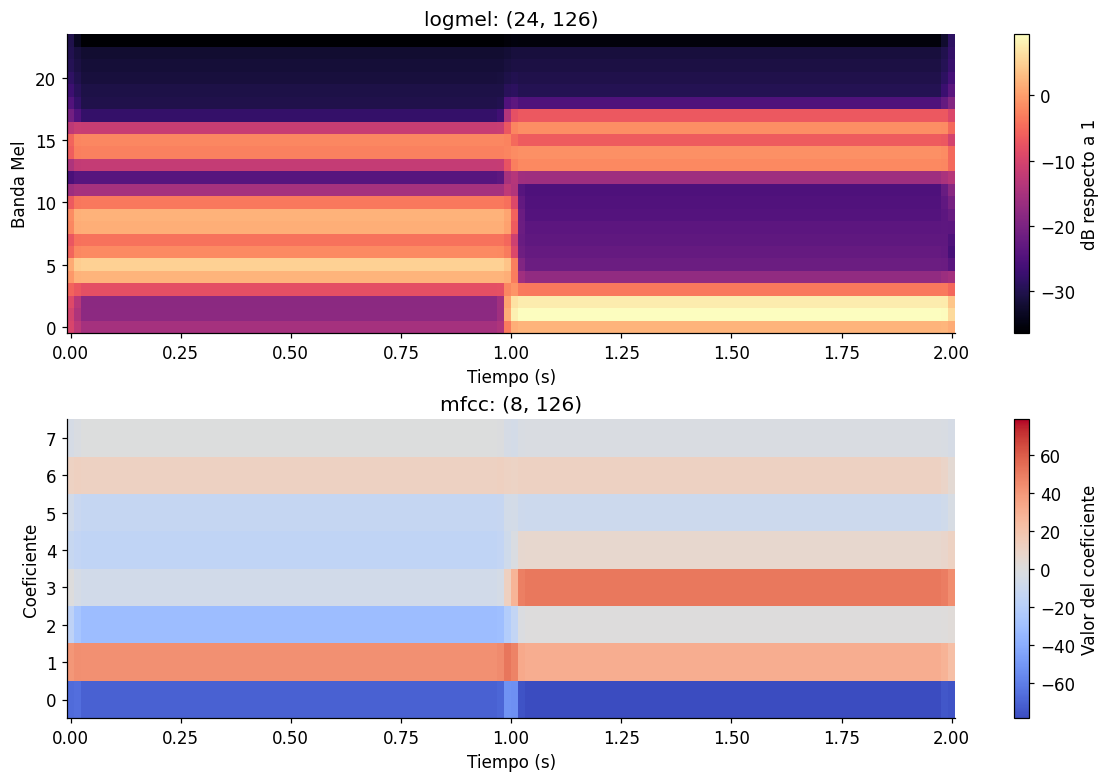

In [49]:
mis_mels=24
mis_mfcc=8
mis_car=caracteristicas_audio(y_m,sr_m,n_mels=mis_mels,n_mfcc=mis_mfcc)
fig,ejes=plt.subplots(2,1,figsize=(10,7),constrained_layout=True)
for ax,nombre in zip(ejes,["logmel","mfcc"]):
    datos=mis_car[nombre]
    ax.grid(False)
    if nombre=="mfcc":
        limite=np.max(np.abs(datos))
        im=ax.pcolormesh(tiempos_m,np.arange(datos.shape[0]),datos,shading="auto",cmap="coolwarm",vmin=-limite,vmax=limite)
    else:
        im=ax.pcolormesh(tiempos_m,np.arange(datos.shape[0]),datos,shading="auto",cmap="magma")
    ax.set(xlabel="Tiempo (s)",ylabel="Banda Mel" if nombre=="logmel" else "Coeficiente",title=f"{nombre}: {datos.shape}")
    fig.colorbar(im,ax=ax,label="dB respecto a 1" if nombre=="logmel" else "Valor del coeficiente")
plt.show()

<a id="tema-46" name="tema-46"></a>

## 46. Ejercicios y respuestas razonadas

1. ¿Qué diferencia hay entre tasa de Nyquist y frecuencia de Nyquist?
2. ¿Por qué Hann no resuelve el aliasing que ya ocurrió al grabar?
3. Si analizamos con Hann y volvemos a multiplicar por Hann en síntesis, ¿por qué dividimos entre la suma de cuadrados?
4. ¿Por qué 50% de solapamiento con Hann no implica suma constante de Hann al cuadrado?
5. Una potencia STFT tiene forma `(513,126)` y el banco `(40,513)`. ¿Qué forma tiene Mel?
6. ¿Qué diferencia hay entre cambiar el eje a logarítmico y aplicar filtros Mel?
7. ¿Por qué usamos `power_to_db` para Mel de potencia y no `amplitude_to_db` directamente?
8. ¿El coeficiente MFCC 12 representa 12 Hz, la banda Mel 12 o un patrón de variación entre bandas?
9. Si conservamos todos los coeficientes DCT, ¿se recupera exactamente el audio?
10. ¿Por qué no es válido comparar modelos cambiando silenciosamente la referencia logarítmica o las particiones?

### Respuestas

1. $2B$ depende de la señal; $f_s/2$ depende del sistema de muestreo.
2. La ambigüedad se produjo antes de dividir el audio en ventanas. Hann reduce fuga por bordes, otro fenómeno.
3. Cada bloque contiene dos factores de ventana: el de análisis y el de síntesis. Se acumula $w^2$ por muestra.
4. La identidad de suma de $w$ no es la de suma de $w^2$. Se reconstruye dividiendo por la suma de cuadrados no nula, aunque varíe.
5. `(40,126)`: reducimos el eje de frecuencias y conservamos el temporal.
6. El eje solo cambia cómo dibujamos; el banco combina numéricamente varios bins.
7. La potencia usa $10\log_{10}$; la amplitud usa $20\log_{10}$. Aplicar la segunda directamente a potencia duplicaría los dB con la misma referencia.
8. Un patrón DCT de variación a lo largo de las bandas, no una frecuencia acústica.
9. Se recupera log-Mel si no hubo pérdidas adicionales en esa etapa; potencia y Mel ya descartaron fase y detalle espectral.
10. Se mezclaría el efecto de arquitectura con cambios en datos o características. El experimento debe controlar esas decisiones.

[**↑ Volver al índice**](#indice)

<a id="tema-47" name="tema-47"></a>

## 47. Referencias sobre características de audio

Las referencias están junto a cada explicación. Para profundizar:

- **Muestreo:** Shannon (1949), [Communication in the Presence of Noise](https://doi.org/10.1109/JRPROC.1949.232969).
- **Ventanas:** Harris (1978), [On the use of windows for harmonic analysis with the discrete Fourier transform](https://doi.org/10.1109/PROC.1978.10837).
- **Síntesis STFT:** [librosa ISTFT](https://librosa.org/doc/0.11.0/generated/librosa.istft.html), [SciPy NOLA](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.check_NOLA.html).
- **Escala Mel:** Stevens, Volkmann y Newman (1937), [escala de altura perceptual](https://doi.org/10.1121/1.1915893); [convenciones de librosa](https://librosa.org/doc/0.11.0/generated/librosa.mel_frequencies.html).
- **Características de voz:** Davis y Mermelstein (1980), [Comparison of Parametric Representations for Monosyllabic Word Recognition in Continuously Spoken Sentences](https://doi.org/10.1109/TASSP.1980.1163420).
- **Código:** [Mel](https://librosa.org/doc/0.11.0/generated/librosa.feature.melspectrogram.html), [MFCC](https://librosa.org/doc/0.11.0/generated/librosa.feature.mfcc.html), [DCT](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.dct.html).

Estas referencias respaldan los conceptos y las funciones empleadas en los ejemplos.

[**↑ Volver al índice**](#indice)

<a id="tema-48" name="tema-48"></a>

# Aplicación final · Speech Commands y preparación de datos
## 48. Speech Commands

Speech Commands contiene grabaciones de palabras aisladas. La tarea consiste en asociar cada audio con una etiqueta, por ejemplo `yes` o `stop`. Esto es distinto de transcribir frases completas.

Utilizamos **la versión 0.02** y conservamos sus listas oficiales de validación y prueba. La carpeta `_background_noise_` contiene grabaciones de ruido; no se interpreta como una palabra. Este ejemplo conserva las clases de palabras encontradas en las carpetas y no crea clases adicionales de silencio o desconocido.

El recorrido termina con un lote de características y sus etiquetas. Las redes recurrentes y convolucionales se describen al final, sin entrenarlas.

**Recursos:** la descarga completa ocupa varios GB y la extracción requiere espacio adicional. Conviene disponer de unos 6 GB libres. El límite de ejemplos de la práctica reduce el procesamiento, pero no el tamaño de la descarga original. Las partes 1–4 siguen funcionando sin descargar el conjunto.

Referencia: Pete Warden (2018), [Speech Commands: A Dataset for Limited-Vocabulary Speech Recognition](https://arxiv.org/abs/1804.03209). La [implementación oficial de torchaudio](https://docs.pytorch.org/audio/stable/_modules/torchaudio/datasets/speechcommands.html) documenta las listas de partición y la suma de verificación del archivo. Aquí leemos los WAV directamente para explicar cada operación.

[**↑ Volver al índice**](#indice)

<a id="tema-49" name="tema-49"></a>

## 49. Descarga y carpeta de trabajo

`DESCARGAR_DATOS` permite obtener el archivo oficial si no está disponible. Está en `False` para que ejecutar todos los ejemplos de señales no inicie una descarga grande. Para trabajar con voz real, cambia el valor a `True` y ejecuta este bloque. Si ya tienes el conjunto extraído, ajusta `RUTA_DATOS` a la carpeta que contiene `validation_list.txt` y `testing_list.txt`.

La descarga se comprueba mediante SHA-256 antes de extraerla. El archivo temporal se renombra al terminar, de modo que una descarga interrumpida no se confunda con una completa.

`MAX_POR_CLASE` selecciona una muestra pequeña de cada partición para la práctica. Usa `None` para procesar todos sus registros. La selección es reproducible y no mueve archivos entre particiones.

[**↑ Volver al índice**](#indice)

In [50]:
DESCARGAR_DATOS = False  # Cambia a True para descargar Speech Commands v0.02.
RUTA_DATOS = Path("/content/speech_commands_v0.02") if Path("/content").exists() else Path("datos/speech_commands_v0.02")
SEMILLA_DATOS = 42
MAX_POR_CLASE = {"train": 20, "validation": 5, "test": 5}
CONFIG_AUDIO = {"sr":16000, "duracion":1.0, "n_fft":1024, "hop_length":256, "n_mels":40}
URL_DATOS = "https://storage.googleapis.com/download.tensorflow.org/data/speech_commands_v0.02.tar.gz"
SHA_DATOS = "af14739ee7dc311471de98f5f9d2c9191b18aedfe957f4a6ff791c709868ff58"
torch.manual_seed(SEMILLA_DATOS)

def verificar_sha256(ruta):
    h = hashlib.sha256()
    with Path(ruta).open("rb") as f:
        for bloque in iter(lambda:f.read(1024*1024), b""):
            h.update(bloque)
    return h.hexdigest()

def preparar_speech_commands(raiz, descargar=False):
    raiz = Path(raiz)
    listas = [raiz/"validation_list.txt", raiz/"testing_list.txt"]
    if all(p.is_file() for p in listas):
        return True  # También acepta una carpeta previamente extraída por el usuario.
    if not descargar:
        print("Datos no disponibles. Activa DESCARGAR_DATOS o ajusta RUTA_DATOS.")
        return False
    raiz.parent.mkdir(parents=True,exist_ok=True)
    archivo = raiz.parent/"speech_commands_v0.02.tar.gz"
    if not archivo.exists():
        parcial = archivo.with_suffix(archivo.suffix+".part")
        torch.hub.download_url_to_file(URL_DATOS,str(parcial),hash_prefix=SHA_DATOS,progress=True)
        parcial.replace(archivo)
    if verificar_sha256(archivo) != SHA_DATOS:
        raise ValueError(f"La descarga no coincide con SHA-256. Revisa o elimina {archivo} para descargarla de nuevo.")
    temporal = raiz.with_name(raiz.name+"_extraccion")
    temporal.mkdir(parents=True,exist_ok=True)
    with tarfile.open(archivo,"r:gz") as tar:
        # Solo archivos regulares y carpetas dentro del destino.
        base = temporal.resolve()
        for miembro in tar:
            destino = (temporal/miembro.name).resolve()
            if not destino.is_relative_to(base):
                raise ValueError("Ruta fuera de la carpeta de extracción.")
            if miembro.isdir():
                destino.mkdir(parents=True,exist_ok=True)
            elif miembro.isfile():
                destino.parent.mkdir(parents=True,exist_ok=True)
                with tar.extractfile(miembro) as entrada, destino.open("wb") as salida:
                    shutil.copyfileobj(entrada,salida)
            else:
                raise ValueError("Tipo de archivo inesperado en la descarga.")
    if not all((temporal/p.name).exists() for p in listas):
        raise ValueError("No se encontraron las listas oficiales después de extraer.")
    if raiz.exists():
        raise FileExistsError(f"La carpeta {raiz} existe pero está incompleta; revisa su contenido antes de reemplazarla.")
    temporal.rename(raiz)
    return True

DATOS_DISPONIBLES = preparar_speech_commands(RUTA_DATOS,DESCARGAR_DATOS)

Datos no disponibles. Activa DESCARGAR_DATOS o ajusta RUTA_DATOS.


<a id="tema-50" name="tema-50"></a>

## 50. Archivos, etiquetas y hablantes

La etiqueta se obtiene del nombre de la carpeta. El identificador de hablante es la parte del nombre anterior a `_nohash_`. Una misma persona puede aportar varias grabaciones, por lo que no conviene repartir archivos al azar sin considerar su origen.

El **manifiesto** es una lista de registros: ruta, palabra, hablante y partición. No carga todos los audios en memoria. Las grabaciones de validación y prueba se identifican con las listas oficiales; el resto pertenece a entrenamiento.

[**↑ Volver al índice**](#indice)

In [51]:
def crear_manifiesto(raiz):
    raiz = Path(raiz)
    validacion = set((raiz/"validation_list.txt").read_text().splitlines())
    prueba = set((raiz/"testing_list.txt").read_text().splitlines())
    assert validacion.isdisjoint(prueba), "Las listas de validación y prueba se superponen."
    registros = []
    for ruta in sorted(raiz.glob("*/*.wav")):
        if ruta.parent.name.startswith("_") or "_nohash_" not in ruta.stem:
            continue
        relativa = ruta.relative_to(raiz).as_posix()
        particion = "validation" if relativa in validacion else "test" if relativa in prueba else "train"
        registros.append({"ruta":ruta,"relativa":relativa,"etiqueta":ruta.parent.name,
                          "hablante":ruta.stem.split("_nohash_")[0],"particion":particion})
    disponibles = {r["relativa"] for r in registros}
    faltantes = (validacion|prueba)-disponibles
    if faltantes:
        raise ValueError(f"Faltan {len(faltantes)} archivos de las listas oficiales. Revisa la extracción.")
    if not registros:
        raise ValueError("No se encontraron grabaciones de palabras.")
    return registros

registros_sc = crear_manifiesto(RUTA_DATOS) if DATOS_DISPONIBLES else []
if registros_sc:
    print("Grabaciones:",len(registros_sc))
    print("Clases:",len({r["etiqueta"] for r in registros_sc}))
    print("Distribución por partición:",dict(Counter(r["particion"] for r in registros_sc)))
    print("Primer registro:",registros_sc[0])

<a id="tema-51" name="tema-51"></a>

## 51. Particiones y distribución de clases

| Partición | Uso |
|---|---|
| Entrenamiento | Calcular estadísticas de preprocesamiento y, en un experimento de aprendizaje, ajustar parámetros. |
| Validación | Revisar decisiones de configuración sin utilizar la prueba final. |
| Prueba | Reservar ejemplos para una evaluación independiente. Aquí solo se organiza su acceso. |

Compartir hablantes entre particiones puede facilitar el reconocimiento de características de una persona en lugar de la palabra. Comprobamos que las listas oficiales mantengan separados esos identificadores.

Las frecuencias por clase ayudan a detectar desbalance. Limitar a la misma cantidad por clase en esta práctica facilita inspeccionar ejemplos, pero **no describe la distribución original**. Se muestran los conteos completos antes de seleccionar.

[**↑ Volver al índice**](#indice)

In [52]:
particiones_sc = {nombre:[r for r in registros_sc if r["particion"]==nombre] for nombre in ["train","validation","test"]}
clases_sc = sorted({r["etiqueta"] for r in particiones_sc["train"]})
etiqueta_a_indice = {nombre:i for i,nombre in enumerate(clases_sc)}

def seleccionar_por_clase(registros, limite, semilla):
    if limite is None:
        return list(registros)
    if limite <= 0:
        raise ValueError("El límite debe ser positivo o None.")
    rng = np.random.default_rng(semilla)
    seleccion = []
    for etiqueta in sorted({r["etiqueta"] for r in registros}):
        candidatos = [r for r in registros if r["etiqueta"]==etiqueta]
        indices = rng.permutation(len(candidatos))[:limite]
        seleccion.extend(candidatos[int(i)] for i in indices)
    return seleccion

seleccion_sc = {nombre:seleccionar_por_clase(rs,MAX_POR_CLASE[nombre],SEMILLA_DATOS) for nombre,rs in particiones_sc.items()}
if registros_sc:
    hablantes = {nombre:{r["hablante"] for r in rs} for nombre,rs in particiones_sc.items()}
    assert hablantes["train"].isdisjoint(hablantes["validation"])
    assert hablantes["train"].isdisjoint(hablantes["test"])
    assert hablantes["validation"].isdisjoint(hablantes["test"])
    assert all(r["etiqueta"] in etiqueta_a_indice for r in registros_sc)
    print("Hablantes separados entre particiones.")
    print("Selección de práctica:",{k:len(v) for k,v in seleccion_sc.items()})
    fig, ax = plt.subplots(figsize=(12,4))
    conteo = Counter(r["etiqueta"] for r in particiones_sc["train"])
    ax.bar(clases_sc,[conteo[c] for c in clases_sc],color=COLOR)
    ax.tick_params(axis="x",labelrotation=90)
    ax.set(xlabel="Palabra",ylabel="Grabaciones",title="Distribución completa de entrenamiento")
    plt.tight_layout()
    plt.show()

<a id="tema-52" name="tema-52"></a>

## 52. Lectura y revisión de una grabación

`wavfile.read` devuelve la frecuencia de muestreo y el arreglo. El tipo entero PCM necesita convertirse a amplitud flotante antes del análisis. Para `int16`, dividimos entre 32 768; para `uint8`, primero centramos en 128. No se divide por 32 768 un archivo que ya contiene flotantes.

La duración se calcula con el número de muestras por canal. En archivos multicanal, el promedio de canales produce una mezcla mono sencilla; puede cancelar componentes con fases opuestas, como se explicó en la primera parte.

[**↑ Volver al índice**](#indice)

In [53]:
def leer_audio_mono(ruta):
    sr, datos = wavfile.read(str(ruta))
    if datos.dtype == np.uint8:
        y = (datos.astype(np.float32)-128)/128
    elif np.issubdtype(datos.dtype,np.signedinteger):
        escala = float(2**(np.iinfo(datos.dtype).bits-1))
        y = datos.astype(np.float32)/escala
    elif np.issubdtype(datos.dtype,np.floating):
        y = datos.astype(np.float32)
    else:
        raise TypeError(f"Formato no contemplado: {datos.dtype}")
    if y.ndim == 2:
        y = y.mean(axis=1)
    if y.ndim != 1 or len(y)==0 or sr<=0 or not np.isfinite(y).all():
        raise ValueError("El audio no tiene una señal mono válida.")
    return y, int(sr)

if registros_sc:
    ejemplo_sc = seleccion_sc["train"][0]
    y_sc, sr_sc = leer_audio_mono(ejemplo_sc["ruta"])
    print("Palabra:",ejemplo_sc["etiqueta"],"| hablante:",ejemplo_sc["hablante"])
    print("Frecuencia de muestreo:",sr_sc,"Hz | duración:",len(y_sc)/sr_sc,"s")
    display(Audio(y_sc,rate=sr_sc,normalize=False))
    fig, ax = plt.subplots()
    ax.plot(np.arange(len(y_sc))/sr_sc,y_sc,color=COLOR)
    ax.set(xlabel="Tiempo (s)",ylabel="Amplitud",title="Grabación de "+ejemplo_sc["etiqueta"])
    plt.show()

<a id="tema-53" name="tema-53"></a>

## 53. Preprocesamiento del audio

Se aplica la misma secuencia a cada ejemplo:

1. Leer el WAV y convertir amplitudes a flotantes.
2. Convertir a mono si tiene varios canales.
3. Remuestrear a 16 kHz si hace falta. `librosa.resample` incluye filtrado; cambiar la etiqueta de frecuencia no es remuestrear.
4. Ajustar a un segundo: añadir ceros al final o recortar el centro si sobra audio.
5. Calcular log-Mel con parámetros fijos.

El recorte central es una decisión explícita y puede quitar contenido; no es una solución universal para grabaciones largas. En palabras de aproximadamente un segundo evita cambiar continuamente la forma de los arreglos. No se eliminan silencios ni se normaliza cada grabación por su propio pico.

**Ejemplo:** 12 000 muestras a 16 kHz equivalen a 0.75 s. Añadir 4 000 ceros completa un segundo; no alarga la palabra. Reproducir esas 12 000 muestras a 12 kHz sí cambiaría su duración y sus frecuencias.

[**↑ Volver al índice**](#indice)

Antes: 12000 muestras | después: 16000


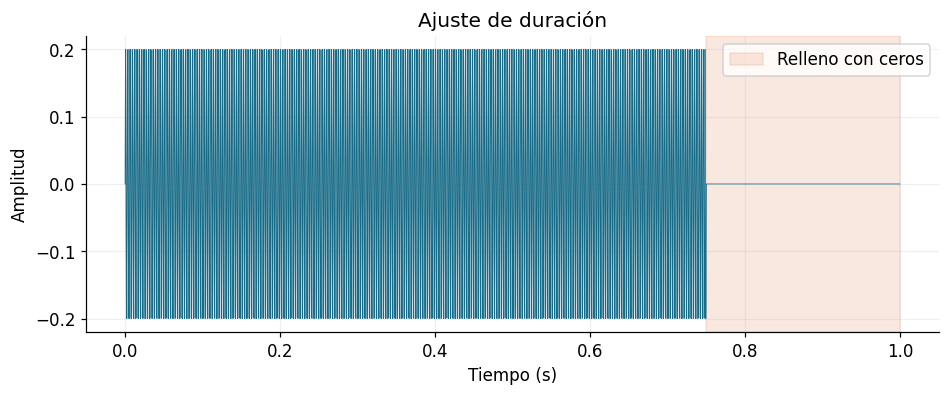

In [54]:
def ajustar_audio(y, sr_origen, sr_destino=16000, duracion=1.0):
    y = np.asarray(y,dtype=np.float32)
    if y.ndim != 1 or y.size == 0 or not np.isfinite(y).all():
        raise ValueError("Se espera audio mono, no vacío y finito.")
    if sr_origen <= 0 or sr_destino <= 0 or duracion <= 0:
        raise ValueError("Frecuencias y duración deben ser positivas.")
    if sr_origen != sr_destino:
        y = librosa.resample(y,orig_sr=sr_origen,target_sr=sr_destino,res_type="soxr_hq")
    longitud = int(round(sr_destino*duracion))
    if len(y) < longitud:
        y = np.pad(y,(0,longitud-len(y)))
    elif len(y) > longitud:
        inicio = (len(y)-longitud)//2
        y = y[inicio:inicio+longitud]
    return np.ascontiguousarray(y,dtype=np.float32)

# Ejemplo independiente del conjunto: relleno de una señal de 0.75 segundos.
corta_sc = 0.2*np.sin(2*np.pi*440*np.arange(12000)/16000)
ajustada_sc = ajustar_audio(corta_sc,16000)
print("Antes:",len(corta_sc),"muestras | después:",len(ajustada_sc))
fig, ax = plt.subplots()
ax.plot(np.arange(len(ajustada_sc))/16000,ajustada_sc,color=COLOR,linewidth=0.5)
ax.axvspan(0.75,1,color=ACENTO,alpha=0.15,label="Relleno con ceros")
ax.set(xlabel="Tiempo (s)",ylabel="Amplitud",title="Ajuste de duración")
ax.legend()
plt.show()

<a id="tema-54" name="tema-54"></a>

## 54. Log-Mel de tamaño fijo

La configuración conserva la de los ejemplos anteriores: Hann, 1 024 puntos de FFT, salto de 256 muestras, 40 filtros Slaney, potencia y dB respecto a 1. Con un segundo a 16 kHz, `center=True` y FFT par, se obtienen 63 ventanas:

$$T=1+\left\lfloor\frac{16000}{256}\right\rfloor=63.$$

Cada ejemplo tiene forma **`(40, 63)`**. El piso numérico evita logaritmos de cero; el silencio queda con valores finitos. Esta función es independiente de las variables de las partes anteriores.

[**↑ Volver al índice**](#indice)

In [55]:
def extraer_logmel(y, config):
    D = librosa.stft(y,n_fft=config["n_fft"],win_length=config["n_fft"],
                     hop_length=config["hop_length"],window="hann",center=True,pad_mode="constant")
    P = np.abs(D)**2
    M = librosa.feature.melspectrogram(S=P,sr=config["sr"],n_fft=config["n_fft"],
                                      n_mels=config["n_mels"],fmin=0,fmax=config["sr"]/2,
                                      htk=False,norm="slaney")
    X = librosa.power_to_db(M,ref=1.0,amin=1e-10,top_db=None)
    return np.ascontiguousarray(X,dtype=np.float32)

logmel_demo_sc = extraer_logmel(ajustada_sc,CONFIG_AUDIO)
print("Forma del ejemplo sintético:",logmel_demo_sc.shape)
if registros_sc:
    audio_procesado_sc = ajustar_audio(y_sc,sr_sc,CONFIG_AUDIO["sr"],CONFIG_AUDIO["duracion"])
    logmel_sc = extraer_logmel(audio_procesado_sc,CONFIG_AUDIO)
    fig, ax = plt.subplots(figsize=(10,4))
    ax.grid(False)
    tiempos = np.arange(logmel_sc.shape[1])*CONFIG_AUDIO["hop_length"]/CONFIG_AUDIO["sr"]
    im = ax.pcolormesh(tiempos,np.arange(CONFIG_AUDIO["n_mels"]),logmel_sc,shading="auto",cmap="magma")
    ax.set(xlabel="Tiempo (s)",ylabel="Banda Mel",title="Log-Mel de "+ejemplo_sc["etiqueta"])
    fig.colorbar(im,ax=ax,label="dB respecto a 1")
    plt.show()

Forma del ejemplo sintético: (40, 63)


<a id="tema-55" name="tema-55"></a>

## 55. Tensores de PyTorch

Un tensor organiza valores en uno o varios ejes. Para esta práctica, un espectrograma es una matriz y un lote añade un eje que identifica cada audio.

| Objeto | Forma | Tipo |
|---|---|---|
| Una señal | `(16000,)` | Flotante |
| Un log-Mel | `(40,63)` | `torch.float32` |
| Un lote de 8 ejemplos | `(8,40,63)` | `torch.float32` |
| Etiquetas del lote | `(8,)` | `torch.int64` o `torch.long` |

`torch.from_numpy` comparte memoria con el arreglo NumPy. `clone` crea una copia independiente. `unsqueeze` agrega un eje; `permute` cambia el orden de los ejes. `reshape` cambia la forma siguiendo el orden de los datos: no sustituye a `permute` cuando se quiere intercambiar tiempo y bandas.

La CPU es suficiente para este bloque. `.to(dispositivo)` permite mover un tensor a GPU si existe, pero el `Dataset` y sus trabajadores deben preparar los datos en CPU.

Referencia: [PyTorch, tensores](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html).

[**↑ Volver al índice**](#indice)

In [56]:
X_tensor_sc = torch.from_numpy(logmel_demo_sc).clone()
y_tensor_sc = torch.tensor(0,dtype=torch.long)  # Etiqueta ficticia solo para explicar el tipo.
print("Características:",X_tensor_sc.shape,X_tensor_sc.dtype)
print("Etiqueta:",y_tensor_sc.shape,y_tensor_sc.dtype)
print("Con un eje de canal:",X_tensor_sc.unsqueeze(0).shape)
print("Tiempo × bandas:",X_tensor_sc.permute(1,0).shape)
dispositivo_sc = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo disponible:",dispositivo_sc)

Características: torch.Size([40, 63]) torch.float32
Etiqueta: torch.Size([]) torch.int64
Con un eje de canal: torch.Size([1, 40, 63])
Tiempo × bandas: torch.Size([63, 40])
Dispositivo disponible: cpu


<a id="tema-56" name="tema-56"></a>

## 56. Dataset: un ejemplo y su etiqueta

Un `Dataset` define cómo obtener un elemento por índice. No es un lote ni una carpeta: es un objeto que relaciona los registros con su procesamiento.

- `__init__` guarda la lista de registros, las etiquetas y la configuración.
- `__len__` devuelve cuántos ejemplos hay.
- `__getitem__` recibe un índice, carga el WAV, lo procesa y devuelve características y etiqueta.

**Ejemplo:** `dataset[7]` solicita el octavo registro. Solo se carga ese archivo; no todo el conjunto. Esta lectura bajo demanda reduce el uso de memoria, aunque vuelve a calcular las características cuando se pide otra vez el mismo ejemplo.

Las mismas palabras conservan los mismos índices en todas las particiones. No se construye un diccionario de clases distinto para validación.

Referencia: [PyTorch, Dataset y DataLoader](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html).

[**↑ Volver al índice**](#indice)

In [57]:
class ComandosDataset(Dataset):
    def __init__(self, registros, clases, config, media=None, desviacion=None):
        self.registros = list(registros)
        self.clases = dict(clases)
        self.config = dict(config)
        if (media is None) != (desviacion is None):
            raise ValueError("Media y desviación deben proporcionarse juntas.")
        self.media = None if media is None else np.asarray(media,dtype=np.float32).copy()
        self.desviacion = None if desviacion is None else np.asarray(desviacion,dtype=np.float32).copy()

    def __len__(self):
        return len(self.registros)

    def __getitem__(self, indice):
        registro = self.registros[indice]
        audio, sr = leer_audio_mono(registro["ruta"])
        audio = ajustar_audio(audio,sr,self.config["sr"],self.config["duracion"])
        X = extraer_logmel(audio,self.config)
        if self.media is not None:
            X = (X-self.media)/self.desviacion
        y = self.clases[registro["etiqueta"]]
        return torch.from_numpy(np.ascontiguousarray(X,dtype=np.float32)), torch.tensor(y,dtype=torch.long)

train_sin_norm_sc = ComandosDataset(seleccion_sc["train"],etiqueta_a_indice,CONFIG_AUDIO)
if len(train_sin_norm_sc):
    X0_sc,y0_sc = train_sin_norm_sc[0]
    print("Número de ejemplos:",len(train_sin_norm_sc))
    print("Un ejemplo:",X0_sc.shape,"| clase:",clases_sc[y0_sc.item()])

<a id="tema-57" name="tema-57"></a>

## 57. Normalización con datos de entrenamiento

Para cada banda Mel calculamos media y desviación sobre los ejemplos de entrenamiento seleccionados y sus ventanas temporales:

$$\widetilde X[b,t]=\frac{X[b,t]-\mu_b}{\max(\sigma_b,\epsilon)}.$$

Validación y prueba usan exactamente esas estadísticas. Calcularlas con todo el conjunto introduciría información de datos reservados. Normalizar cada audio por separado sería otro procedimiento y cambiaría qué diferencias de amplitud se conservan.

Usaremos acumulación por grupos con la fórmula de Welford: evita guardar todos los espectrogramas y reduce errores por restar números grandes casi iguales. Incluimos las ventanas de relleno porque forman parte de la entrada definida aquí; excluirlas requeriría máscaras y otra convención explícita.

**Ejemplo:** si una banda tiene media −30 y desviación 10, un valor de −20 se transforma en 1. Esto no significa que su potencia física sea 1; es una coordenada estandarizada.

[**↑ Volver al índice**](#indice)

In [58]:
def calcular_estadisticas(dataset):
    if len(dataset)==0:
        raise ValueError("Se requieren ejemplos de entrenamiento.")
    cantidad = 0
    media = np.zeros((dataset.config["n_mels"],1),dtype=np.float64)
    M2 = np.zeros_like(media)
    for i in range(len(dataset)):
        X,_ = dataset[i]
        a = X.numpy().astype(np.float64)
        n = a.shape[1]
        media_bloque = a.mean(axis=1,keepdims=True)
        M2_bloque = ((a-media_bloque)**2).sum(axis=1,keepdims=True)
        delta = media_bloque-media
        total = cantidad+n
        media += delta*n/total
        M2 += M2_bloque + delta**2*cantidad*n/total
        cantidad = total
    desviacion = np.sqrt(np.maximum(M2/cantidad,0))
    return media.astype(np.float32),np.maximum(desviacion,1e-6).astype(np.float32)

media_sc = desviacion_sc = None
if len(train_sin_norm_sc):
    media_sc,desviacion_sc = calcular_estadisticas(train_sin_norm_sc)
    print("Estadísticas por banda:",media_sc.shape,desviacion_sc.shape)
    print("Calculadas solo con",len(train_sin_norm_sc),"ejemplos de entrenamiento.")
    salida_config_sc = RUTA_DATOS.parent/"preprocesamiento_speech_commands.json"
    salida_config_sc.write_text(json.dumps({"config_audio":CONFIG_AUDIO,"clases":clases_sc,
        "seleccion_por_clase":MAX_POR_CLASE,"semilla":SEMILLA_DATOS,
        "media":media_sc[:,0].tolist(),"desviacion":desviacion_sc[:,0].tolist()},indent=2),encoding="utf-8")
    print("Configuración guardada en:",salida_config_sc)

<a id="tema-58" name="tema-58"></a>

## 58. DataLoader: organización por lotes

El `DataLoader` solicita varios ejemplos al `Dataset` y los reúne. Con ocho matrices `(40,63)`, el lote queda `(8,40,63)` y sus ocho etiquetas quedan `(8,)`.

| Parámetro | Función en esta práctica |
|---|---|
| `batch_size=8` | Hasta ocho ejemplos por lote. |
| `shuffle=True` | Cambia el orden de los ejemplos de entrenamiento. |
| `num_workers=0` | Carga en el proceso principal; simplifica los ejemplos de Colab. |
| `drop_last=False` | Conserva un último lote pequeño si el total no es múltiplo de ocho. |
| `collate_fn` | Define cómo reunir ejemplos; la función predeterminada apila tensores de igual forma. |

`shuffle` no divide el conjunto ni mueve ejemplos a validación. Un recorrido completo del cargador visita una vez los ejemplos del conjunto, salvo que se use otro muestreador. Una semilla permite reproducir el orden inicial; los recorridos sucesivos pueden tener órdenes diferentes.

[**↑ Volver al índice**](#indice)

In [59]:
datasets_sc = {}
loaders_sc = {}
if media_sc is not None:
    datasets_sc = {nombre:ComandosDataset(rs,etiqueta_a_indice,CONFIG_AUDIO,media_sc,desviacion_sc)
                   for nombre,rs in seleccion_sc.items()}
    for nombre,ds in datasets_sc.items():
        generador = torch.Generator().manual_seed(SEMILLA_DATOS)
        loaders_sc[nombre] = DataLoader(ds,batch_size=8,shuffle=(nombre=="train"),
                                       num_workers=0,drop_last=False,generator=generador)
    print("Lotes por partición:",{k:len(v) for k,v in loaders_sc.items()})
    print("Prueba organizada sin consumir sus lotes.")
else:
    print("Los cargadores de voz real se crean cuando los datos y sus estadísticas están disponibles.")

Los cargadores de voz real se crean cuando los datos y sus estadísticas están disponibles.


<a id="tema-59" name="tema-59"></a>

## 59. collate_fn y longitudes diferentes

Si los audios no tuvieran la misma duración, sus matrices podrían tener distintos números de columnas. No se pueden apilar directamente. Una `collate_fn` puede rellenar hasta la longitud mayor del lote y conservar las longitudes originales mediante una máscara.

La máscara indica qué posiciones contienen datos válidos. Agregar ceros sin guardar las longitudes puede hacer que una red trate el relleno como observación real. El siguiente ejemplo es sintético y explica el mecanismo; los comandos de esta práctica ya tienen una longitud fija.

En características normalizadas, rellenar con cero equivale al valor medio, no necesariamente a silencio acústico. Por eso no se debe atribuir significado físico al relleno de un tensor.

[**↑ Volver al índice**](#indice)

In [60]:
def reunir_variables(ejemplos):
    longitudes = torch.tensor([X.shape[1] for X,_ in ejemplos],dtype=torch.long)
    bandas = ejemplos[0][0].shape[0]
    max_t = int(longitudes.max())
    lote = torch.zeros(len(ejemplos),bandas,max_t,dtype=torch.float32)
    etiquetas = torch.stack([y for _,y in ejemplos])
    for i,(X,_) in enumerate(ejemplos):
        if X.shape[0] != bandas:
            raise ValueError("Los ejemplos deben tener el mismo número de bandas.")
        lote[i,:,:X.shape[1]] = X
    mascara = torch.arange(max_t)[None,:] < longitudes[:,None]
    return lote,etiquetas,longitudes,mascara

ejemplos_variables_sc = [(torch.ones(3,4),torch.tensor(0)),(torch.full((3,6),2.0),torch.tensor(1))]
loader_variable_sc = DataLoader(ejemplos_variables_sc,batch_size=2,collate_fn=reunir_variables)
lote_var_sc,etiquetas_var_sc,longitudes_sc,mascara_sc = next(iter(loader_variable_sc))
print("Forma:",lote_var_sc.shape,"| longitudes:",longitudes_sc.tolist())
print("Máscara de posiciones válidas:")
print(mascara_sc)

Forma: torch.Size([2, 3, 6]) | longitudes: [4, 6]
Máscara de posiciones válidas:
tensor([[ True,  True,  True,  True, False, False],
        [ True,  True,  True,  True,  True,  True]])


<a id="tema-60" name="tema-60"></a>

## 60. Inspección de un lote

Antes de usar datos en un modelo conviene comprobar dimensiones, etiquetas, tipos y valores no finitos. También hay que mirar varios ejemplos: una forma correcta no garantiza que las etiquetas o el procesamiento sean correctos.

Este bloque consume un lote de entrenamiento. Los colores muestran características normalizadas; ya no son dB. Se usa una escala común entre los ejemplos mostrados para compararlos.

[**↑ Volver al índice**](#indice)

In [61]:
if "train" in loaders_sc:
    X_lote_sc,y_lote_sc = next(iter(loaders_sc["train"]))
    assert X_lote_sc.ndim==3 and X_lote_sc.shape[1]==CONFIG_AUDIO["n_mels"]
    assert X_lote_sc.dtype==torch.float32 and y_lote_sc.dtype==torch.long
    assert torch.isfinite(X_lote_sc).all()
    assert int(y_lote_sc.min())>=0 and int(y_lote_sc.max())<len(clases_sc)
    print("Características:",X_lote_sc.shape,"| etiquetas:",y_lote_sc.shape)
    print("Palabras:",[clases_sc[i] for i in y_lote_sc.tolist()])
    ver = min(4,len(y_lote_sc))
    fig,ejes = plt.subplots(1,ver,figsize=(4*ver,3.5),squeeze=False,constrained_layout=True)
    for i,ax in enumerate(ejes[0]):
        ax.grid(False)
        tiempos = np.arange(X_lote_sc.shape[2])*CONFIG_AUDIO["hop_length"]/CONFIG_AUDIO["sr"]
        im = ax.pcolormesh(tiempos,np.arange(CONFIG_AUDIO["n_mels"]),X_lote_sc[i].numpy(),
                          shading="auto",cmap="magma",vmin=-3,vmax=3)
        ax.set(xlabel="Tiempo (s)",ylabel="Banda Mel",title=clases_sc[int(y_lote_sc[i])])
    fig.colorbar(im,ax=ejes[0].tolist(),label="Valor estandarizado")
    plt.show()
else:
    print("Para inspeccionar voz real, activa la descarga o indica una carpeta válida y ejecuta desde la sección 49.")

Para inspeccionar voz real, activa la descarga o indica una carpeta válida y ejecuta desde la sección 49.


<a id="tema-61" name="tema-61"></a>

## 61. Introducción a las redes para comandos de voz

Las características preparadas pueden alimentar distintas arquitecturas. Las tres reciben la misma información log-Mel, organizada según sus operaciones:

- **Red recurrente:** interpreta la grabación como una secuencia de ventanas. Una GRU o LSTM mantiene un estado que se actualiza en el tiempo. Con `batch_first=True`, la entrada se organiza como `(B,T,M)`.
- **Convolucional 1D:** los filtros avanzan sobre el tiempo y las bandas Mel actúan como canales. Recibe `(B,M,T)`.
- **Convolucional 2D:** los filtros recorren regiones de tiempo y frecuencia. Se agrega un canal y la entrada queda `(B,1,M,T)`.

$B$ representa el tamaño del lote, $T$ las ventanas temporales y $M$ las bandas Mel. Ninguna arquitectura recibe aquí el color de la gráfica: recibe los valores de la matriz.

Entrenar implica comparar predicciones con etiquetas, calcular una pérdida y ajustar parámetros con gradientes. Evaluar implica usar datos reservados y examinar exactitud, errores por clase y, si hay desbalance, medidas como F1 macro. Estas ideas delimitan la aplicación de los datos; **este cuaderno no implementa entrenamiento ni reporta resultados de clasificación**.

Referencias: [GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html), [Conv1d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv1d.html), [Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html).

[**↑ Volver al índice**](#indice)

In [62]:
# Solo organización de dimensiones; no se crea ni se entrena una red.
entrada_demo_sc = torch.zeros(8,40,63)
print("Recurrente (B,T,M):",entrada_demo_sc.permute(0,2,1).shape)
print("Convolucional 1D (B,M,T):",entrada_demo_sc.shape)
print("Convolucional 2D (B,1,M,T):",entrada_demo_sc.unsqueeze(1).shape)

Recurrente (B,T,M): torch.Size([8, 63, 40])
Convolucional 1D (B,M,T): torch.Size([8, 40, 63])
Convolucional 2D (B,1,M,T): torch.Size([8, 1, 40, 63])


<a id="tema-62" name="tema-62"></a>

## 62. Ejercicios de preparación de datos

1. ¿Por qué no conviene mezclar grabaciones del mismo hablante entre entrenamiento y prueba?
2. ¿Qué diferencia hay entre cambiar `sr` y remuestrear una señal?
3. Si cada log-Mel tiene forma `(40,63)`, ¿qué forma tiene un lote de 16 ejemplos?
4. ¿Qué método del `Dataset` se ejecuta al solicitar `dataset[3]`?
5. ¿Por qué las etiquetas usan enteros y las características flotantes?
6. ¿De qué partición se obtienen la media y la desviación utilizadas en validación?
7. ¿`shuffle=True` modifica las particiones?
8. ¿Qué información debe acompañar a un lote de secuencias rellenadas?
9. ¿Qué cambia si `batch_size=8` y quedan solo tres ejemplos al final, con `drop_last=False`?
10. Inspecciona dos palabras diferentes y explica qué ves en sus espectrogramas sin atribuir a un solo pico el significado de la palabra.

### Respuestas

1. La evaluación puede beneficiarse de características del hablante conocidas durante el ajuste.
2. Cambiar el valor declarado altera la interpretación temporal; remuestrear calcula nuevas muestras con el filtrado necesario.
3. `(16,40,63)`; las etiquetas quedan `(16,)`.
4. `__getitem__`, con índice 3. Los índices comienzan en cero.
5. La etiqueta es un identificador de clase; las características contienen mediciones y transformaciones numéricas continuas.
6. Solo de entrenamiento. Se aplican después sin volver a ajustarlas.
7. No: cambia el orden de acceso dentro de un conjunto.
8. Longitudes originales o una máscara que identifique el relleno.
9. Se devuelve un último lote de tres elementos.
10. La respuesta depende de los audios. Se deben describir patrones temporales y espectrales observados, sin inventar resultados de clasificación.

[**↑ Volver al índice**](#indice)

<a id="tema-63" name="tema-63"></a>

## 63. Cierre y referencias

El cuaderno termina con un procedimiento para convertir grabaciones en lotes de características y etiquetas. El resultado depende de decisiones explícitas: frecuencia de muestreo, duración, ventana, banco Mel, escala logarítmica y normalización. Conservar esa configuración permite repetir el procesamiento y entender qué representa cada tensor.

Las partes 1–4 permiten estudiar los fundamentos con señales generadas. La aplicación final utiliza Speech Commands cuando se proporciona su carpeta o se activa la descarga. Los ejemplos sintéticos de tensores y lotes están identificados como tales.

### Referencias de la aplicación final

- Warden, P. (2018). [Speech Commands: A Dataset for Limited-Vocabulary Speech Recognition](https://arxiv.org/abs/1804.03209).
- PyTorch. [Dataset y DataLoader](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html).
- PyTorch. [Carga de datos y collate_fn](https://docs.pytorch.org/docs/stable/data.html).
- Torchaudio. [Organización oficial de SPEECHCOMMANDS](https://docs.pytorch.org/audio/stable/generated/torchaudio.datasets.SPEECHCOMMANDS.html).
- librosa. [Remuestreo](https://librosa.org/doc/0.11.0/generated/librosa.resample.html), [Mel](https://librosa.org/doc/0.11.0/generated/librosa.feature.melspectrogram.html) y [decibelios](https://librosa.org/doc/0.11.0/generated/librosa.power_to_db.html).

La introducción a redes explica cómo se organizan estas entradas para cada arquitectura.

[**↑ Volver al índice**](#indice)